# HW2: multiple object video detection

**How to run.** The notebook runs on Google Colab or on a local machine with an NVIDIA GPU. It detects Colab by itself.
- **Colab:** results go to `MyDrive/ai-ucu-hw-2` on Google Drive.
- **Local:** results go to `outputs/` next to the notebook, and the prepared training folder to `prep/`. Install a PyTorch build for your GPU first (an RTX 50xx needs CUDA 12.8 or newer), then the rest:
  ```
  pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128
  pip install -r requirements.txt
  ```
  The data is taken from `multiple-object-video-detection-hw-2-ucu-ai-2026/` if it is there, otherwise downloaded with `kagglehub`. The Kaggle token is read from `KAGGLE_API_TOKEN`, from `.env` (`KAGGLE_API_TOKEN=KGAT_...`) or asked for.

Flags in the first code cell: `SMOKE_TEST` runs every step on a few frames and 1 epoch to catch errors (it never submits); `TRAIN` trains models that have no saved weights yet; finished runs are read from `experiment_log.csv` and not repeated unless `FORCE` or `ONLY` says so.

In [1]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"
DRIVE = "/content/drive/MyDrive/ai-ucu-hw-2" if IN_COLAB else os.path.abspath("outputs")
PREP_ARCHIVE = f"{DRIVE}/prep.tar"
SMOKE_TEST = False  # first a short check of every step; then set False and Run All again
RUNS = f"{DRIVE}/runs-smoke" if SMOKE_TEST else f"{DRIVE}/runs"
TRAIN = True
FORCE = False
ONLY = []
SELECT_METRIC = 'mAP_shift'  # mean of val mAP on the test-like clips and on the same frames at test image quality
TRY_P2_HEAD = False  # experiment 8, the slowest training run
USE_TRAINVAL = False  # retrain the final YOLO on train + val and submit it as a second file (scored lower on Kaggle)
SUBMIT = True
STOP_RUNTIME = True

In [2]:
import shutil

if IN_COLAB:
    !nvidia-smi --query-gpu=name,memory.total --format=csv || echo "CPU runtime"
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(RUNS, exist_ok=True)

%pip install -q -U kagglehub ultralytics faster-coco-eval kaggle six ensemble-boxes seaborn scikit-learn transformers timm "rfdetr[train]"

free_gb = shutil.disk_usage("/content" if IN_COLAB else ".").free / 1e9
print(f"Free disk: {free_gb:.0f} GB")
if IN_COLAB:
    print(f"Free on Drive: {shutil.disk_usage(DRIVE).free / 1e9:.1f} GB")


def drive_ok():
    return not IN_COLAB or os.path.ismount("/content/drive")


def stop_runtime():
    if IN_COLAB and STOP_RUNTIME:
        if not drive_ok():
            print("Drive is not mounted, the runtime stays on so the results can be copied")
            return
        from google.colab import runtime
        drive.flush_and_unmount(timeout_ms=600_000)
        runtime.unassign()


def stop_on_error(shell, etype, value, tb, tb_offset=None):
    shell.showtraceback((etype, value, tb), tb_offset=tb_offset)
    if IN_COLAB and STOP_RUNTIME:
        import traceback
        with open(f"{RUNS}/last_error.txt", "w") as f:
            f.write("".join(traceback.format_exception(etype, value, tb)))
    stop_runtime()


get_ipython().set_custom_exc((Exception,), stop_on_error)

Note: you may need to restart the kernel to use updated packages.
Free disk: 1824 GB


In [3]:
import contextlib
import io
import json
import math
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from functools import partial
from getpass import getpass
from pathlib import Path

os.environ['YOLO_VERBOSE'] = 'False'

import cv2
import faster_coco_eval
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torchvision
from ensemble_boxes import weighted_boxes_fusion
from PIL import Image
from sklearn.model_selection import GroupKFold
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.io import read_image
from torchvision.models.detection import (fasterrcnn_resnet50_fpn_v2, fcos_resnet50_fpn, retinanet,
                                          retinanet_resnet50_fpn_v2, roi_heads)
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.fcos import FCOSClassificationHead
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.ops import batched_nms, box_iou, generalized_box_iou_loss
from tqdm.auto import tqdm
from ultralytics import RTDETR, YOLO
from ultralytics.utils import LOGGER

faster_coco_eval.init_as_pycocotools()
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

warnings.filterwarnings('ignore', message='grid_sampler_2d_backward_cuda')
LOGGER.setLevel('WARNING')

if torch.cuda.is_available():
    arch = 'sm_{}{}'.format(*torch.cuda.get_device_capability())
    print(torch.cuda.get_device_name(), arch, '| torch', torch.__version__, '| CUDA', torch.version.cuda)
    assert arch in torch.cuda.get_arch_list(), f'This PyTorch build has no kernels for {arch}, install a newer CUDA build'
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

CLASSES = ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']
COLORS = {'train': '#2a78d6', 'val': '#eb6834', 'test': '#1baf7a'}


def draw_boxes(image, boxes, color):
    thickness = max(2, image.shape[1] // 700)
    for x, y, w, h in boxes[['x', 'y', 'w', 'h']].to_numpy(int):
        cv2.rectangle(image, (x, y), (x + w, y + h), color, thickness)
    return image

/home/akulba/Documents/ai-ucu-hw-2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NVIDIA GeForce RTX 5090 Laptop GPU sm_120 | torch 2.15.0+cu132 | CUDA 13.2


In [4]:
def load_kaggle_token():
    if os.environ.get("KAGGLE_API_TOKEN"):
        return "environment"
    if IN_COLAB:
        from google.colab import userdata
        try:
            os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
            return "Colab Secrets"
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException) as e:
            print(f"Colab secret unavailable ({type(e).__name__}), asking instead.")
    else:
        for env_file in (".env", "../hw-1/.env"):
            for line in open(env_file) if os.path.exists(env_file) else []:
                if line.startswith("KAGGLE_API_TOKEN="):
                    os.environ["KAGGLE_API_TOKEN"] = line.split("=", 1)[1].strip().strip("\"'")
                    return env_file
    os.environ["KAGGLE_API_TOKEN"] = getpass("Kaggle API token (KGAT_...): ")
    return "prompt"


print("Kaggle token loaded from:", load_kaggle_token())

Kaggle token loaded from: environment


In [5]:
LOCAL_DATA = Path(COMPETITION)
if (LOCAL_DATA / 'test_images.csv').exists():
    path = str(LOCAL_DATA.resolve())
else:
    path = kagglehub.competition_download(COMPETITION)

print("Path to competition files:", path)

Path to competition files: /home/akulba/.cache/kagglehub/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


## Data overview
Drone video clips from VisDrone with 8 object classes. Train and val have labels, test has only frames. This section looks at the data, finds what is wrong with it, and puts the fixes into one `clean()`.

In [6]:
DATA = Path(path)


def load_split(split):
    coco = json.loads((DATA / split / 'annotations_coco.json').read_text())
    images = pd.DataFrame(coco['images']).rename(columns={'id': 'image_id'})
    boxes = pd.DataFrame(coco['annotations'])
    boxes[['x', 'y', 'w', 'h']] = np.array(boxes['bbox'].tolist())
    boxes = boxes.drop(columns='bbox').merge(
        images[['image_id', 'video', 'frame_id', 'width', 'height']], on='image_id')
    return images, boxes


train_images, train_boxes = load_split('train')
val_images, val_boxes = load_split('val')
test_images = pd.read_csv(DATA / 'test_images.csv')

print('Train:', train_images.shape, train_boxes.shape)
print('Val:', val_images.shape, val_boxes.shape)
print('Test:', test_images.shape)
display(train_boxes.head())

Train: (24201, 7) (1616260, 18)
Val: (2846, 7) (146092, 18)
Test: (3811, 6)


,id,image_id,category_id,area,iscrowd,truncation,occlusion,track_id,orig_category_id,ignore,x,y,w,h,video,frame_id,width,height
0,1,1,1,3080,0,0.0,0.0,2.0,1,NaN,424,543,35,88,uav0000013_00000_v,1,1344,756
1,2,1,1,3060,0,0.0,1.0,3.0,1,NaN,416,530,36,85,uav0000013_00000_v,1,1344,756
2,3,1,6,9918,0,1.0,0.0,4.0,7,NaN,531,641,87,114,uav0000013_00000_v,1,1344,756
3,4,1,1,2528,0,0.0,0.0,5.0,1,NaN,591,422,32,79,uav0000013_00000_v,1,1344,756
4,5,1,1,1008,0,0.0,0.0,6.0,1,NaN,454,413,21,48,uav0000013_00000_v,1,1344,756


In [7]:
print(train_boxes.isna().sum())
print(val_boxes.isna().sum())
print(test_images.isna().sum())

id                        0
image_id                  0
category_id               0
area                      0
iscrowd                   0
truncation           510744
occlusion            510744
track_id             510744
orig_category_id          0
ignore              1105516
x                         0
y                         0
w                         0
h                         0
video                     0
frame_id                  0
width                     0
height                    0
dtype: int64
id                       0
image_id                 0
category_id              0
area                     0
iscrowd                  0
truncation           31960
occlusion            31960
track_id             31960
orig_category_id         0
ignore              114132
x                        0
y                        0
w                        0
h                        0
video                    0
frame_id                 0
width                    0
height                  

In [8]:
dd = pd.DataFrame({
    'column': ['x', 'y', 'w', 'h', 'category_id', 'orig_category_id', 'iscrowd',
               'truncation', 'occlusion', 'track_id', 'video', 'frame_id'],
    'description': ['left edge, px', 'top edge, px', 'box width, px', 'box height, px',
                    'merged class, 1-8', 'original VisDrone class', '1 = ignore region, not an object',
                    '1 = object cut by the frame edge', '0 none, 1 partial, 2 heavy',
                    'same object across frames', 'clip name', 'frame number in the clip'],
}).set_index('column')
dd['dtype'] = train_boxes.dtypes.astype(str)
dd['missing_%'] = (train_boxes.isna().mean() * 100).round(2)
dd[['dtype', 'missing_%', 'description']]

,dtype,missing_%,description
column,,,
x,int64,0.0,"left edge, px"
y,int64,0.0,"top edge, px"
w,int64,0.0,"box width, px"
h,int64,0.0,"box height, px"
category_id,int64,0.0,"merged class, 1-8"
orig_category_id,int64,0.0,original VisDrone class
iscrowd,int64,0.0,"1 = ignore region, not an object"
truncation,float64,31.6,1 = object cut by the frame edge
occlusion,float64,31.6,"0 none, 1 partial, 2 heavy"


Before any statistics, look at real frames. Green boxes are labelled objects, red boxes are `iscrowd=1` rows.

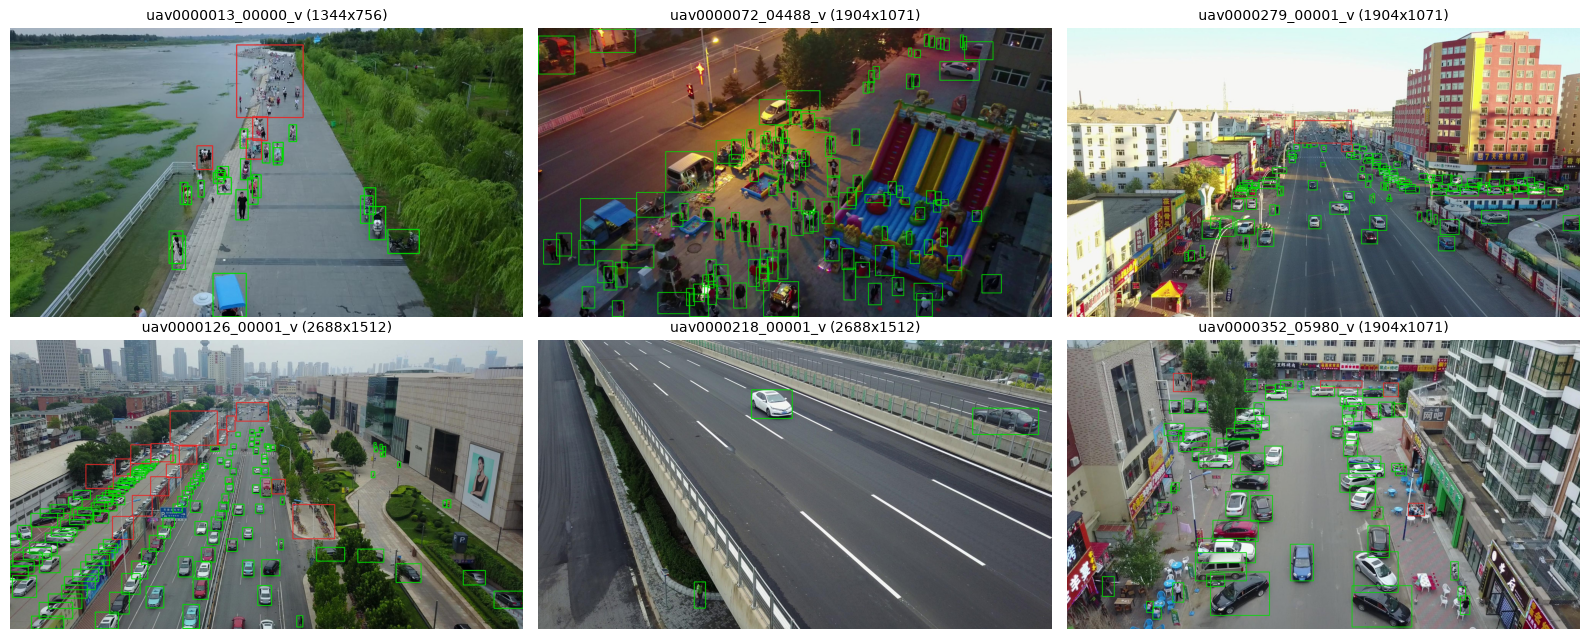

In [9]:
clips = train_images.video.drop_duplicates().sample(6, random_state=42)
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5))

for ax, clip in zip(axes.flatten(), clips):
    frame = train_images[train_images.video == clip].iloc[0]
    boxes = train_boxes[train_boxes.image_id == frame.image_id]
    image = cv2.cvtColor(cv2.imread(str(DATA / 'train' / frame.file_name)), cv2.COLOR_BGR2RGB)
    draw_boxes(image, boxes[boxes.iscrowd == 0], (0, 220, 0))
    draw_boxes(image, boxes[boxes.iscrowd == 1], (230, 40, 40))
    ax.imshow(image)
    ax.set_title(f'{clip} ({frame.width}x{frame.height})', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

### What are the `iscrowd` rows?
`track_id`, `truncation` and `occlusion` are missing on the same rows, about a third of the table. Check how those rows split by class.

In [10]:
pd.crosstab(train_boxes.iscrowd, train_boxes.category_id)

category_id,1,2,3,4,5,6,7,8
iscrowd,,,,,,,,
0,328701,40255,505301,46940,30498,41349,9653,102819
1,63843,63843,63843,63843,63843,63843,63843,63843


Every class has exactly the same number of `iscrowd=1` rows. Real objects cannot do that, so these look like the same regions copied once per class. Count the unique regions.

In [11]:
crowd = train_boxes[train_boxes.iscrowd == 1]
regions = crowd.drop_duplicates(['image_id', 'x', 'y', 'w', 'h'])

print('rows:', len(crowd), ' unique regions:', len(regions), ' copies:', len(crowd) / len(regions))
print(crowd.orig_category_id.value_counts())

rows: 510744  unique regions: 63843  copies: 8.0
orig_category_id
0     498952
11     11792
Name: count, dtype: int64


Confirmed: 63,843 regions, each repeated 8 times. They come from the original VisDrone classes 0 (ignored region) and 11 (others). So non-target objects and areas the annotators skipped are both stored as `iscrowd=1`, and neither is a training target. The other original classes are merged into the 8 target classes (for example pedestrian and people become person).

Do the YOLO `.txt` labels contain them? Compare the number of lines with the real boxes on every frame.

In [12]:
real_per_frame = train_boxes[train_boxes.iscrowd == 0].groupby('image_id').size()
expected = train_images.image_id.map(real_per_frame).fillna(0).astype(int)

lines = [len((DATA / 'train' / 'labels' / r.video / f'{r.frame_id:07d}.txt').read_text().splitlines())
         for r in tqdm(train_images.itertuples(), total=len(train_images))]

print('frames where labels differ from real boxes:', (np.array(lines) != expected).sum())
print('frames without any object:', (expected == 0).sum())

100%|██████████| 24201/24201 [00:00<00:00, 56527.42it/s]

frames where labels differ from real boxes: 0
frames without any object: 3


The labels already skip the ignore regions, so they can be used as they are. Next, check the real boxes for impossible values.

In [13]:
def add_geometry(df):
    df = df[df.iscrowd == 0].copy()
    df['rel_size'] = np.sqrt(df.w * df.h / (df.width * df.height))
    df['cx'] = (df.x + df.w / 2) / df.width
    df['cy'] = (df.y + df.h / 2) / df.height
    df['class_name'] = df.category_id.map(lambda i: CLASSES[i - 1])
    return df


real_train = add_geometry(train_boxes)
real_val = add_geometry(val_boxes)

for name, df in [('train', real_train), ('val', real_val)]:
    outside = (df.x < 0) | (df.y < 0) | (df.x + df.w > df.width) | (df.y + df.h > df.height)
    print(name)
    print('  non-positive size:', ((df.w <= 0) | (df.h <= 0)).sum())
    print('  outside the frame:', outside.sum())
    print('  duplicate track in a frame:', df.duplicated(['video', 'frame_id', 'track_id']).sum())
    print('  exact duplicate boxes:', df.duplicated(['image_id', 'category_id', 'x', 'y', 'w', 'h']).sum())
    print('  smallest side, px:', np.minimum(df.w, df.h).min())

train
  non-positive size: 0
  outside the frame: 0
  duplicate track in a frame: 0
  exact duplicate boxes: 0
  smallest side, px: 4
val
  non-positive size: 0
  outside the frame: 0
  duplicate track in a frame: 0
  exact duplicate boxes: 0
  smallest side, px: 5


There is nothing to fix here: the real labels have no impossible values, and even the smallest boxes are valid objects.

### Box size
Drone footage has very small objects, and this decides the input size of the model. Compare sizes as a share of the frame, because frame resolutions differ.

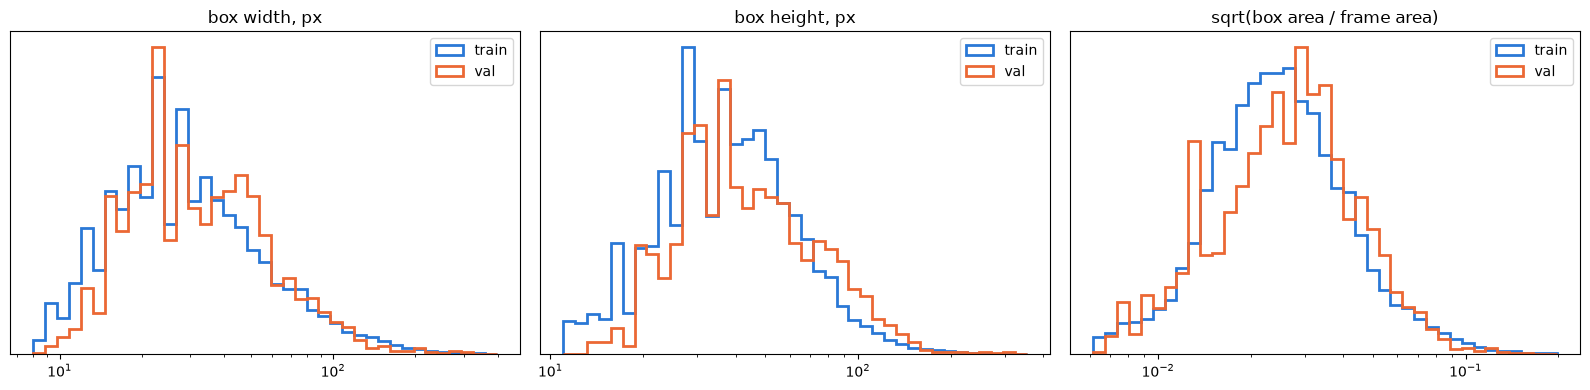

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
columns = [('w', 'box width, px'), ('h', 'box height, px'), ('rel_size', 'sqrt(box area / frame area)')]

for ax, (col, title) in zip(axes, columns):
    both = pd.concat([real_train[col], real_val[col]])
    bins = np.geomspace(both.quantile(0.001), both.quantile(0.999), 40)
    ax.hist(real_train[col], bins=bins, density=True, histtype='step', lw=2, color=COLORS['train'], label='train')
    ax.hist(real_val[col], bins=bins, density=True, histtype='step', lw=2, color=COLORS['val'], label='val')
    ax.set_xscale('log')
    ax.set_title(title)
    ax.set_yticks([])
    ax.legend()

plt.tight_layout()
plt.show()

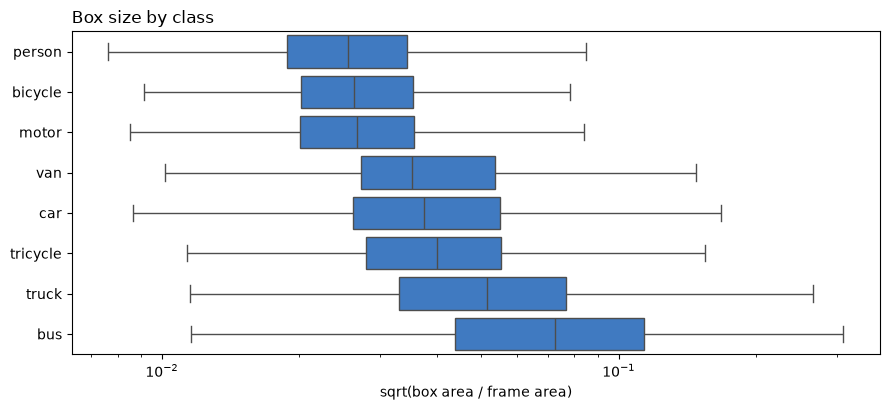

imgsz 640: 9.8% of boxes under 8 px, 54.2% under 16 px
imgsz 960: 1.7% of boxes under 8 px, 24.0% under 16 px
imgsz 1280: 0.6% of boxes under 8 px, 9.8% under 16 px


In [15]:
fig, ax = plt.subplots(figsize=(9, 4.2))
order = real_train.groupby('class_name').rel_size.median().sort_values().index
sns.boxplot(data=real_train, x='rel_size', y='class_name', order=order, showfliers=False,
            color=COLORS['train'], log_scale=True, ax=ax)
ax.set_xlabel('sqrt(box area / frame area)')
ax.set_ylabel('')
ax.set_title('Box size by class', loc='left')
plt.tight_layout()
plt.show()

for imgsz in (640, 960, 1280):
    side = np.sqrt(real_train.w * real_train.h) * imgsz / np.maximum(real_train.width, real_train.height)
    print(f'imgsz {imgsz}: {(side < 8).mean():.1%} of boxes under 8 px, {(side < 16).mean():.1%} under 16 px')

Train and val have almost the same size distribution, so val is a fair check for object size. Objects are tiny: at `imgsz=640`, 54.2% of boxes are under 16 px, compared with 24.0% at 960 and 9.8% at 1280. Person, bicycle and motor are the smallest classes, and bus is the largest.

Decision: `imgsz=960` for all detectors, with 1280 tested as an experiment. Anchor sizes for the anchor-based models come from these distributions.

### Classes

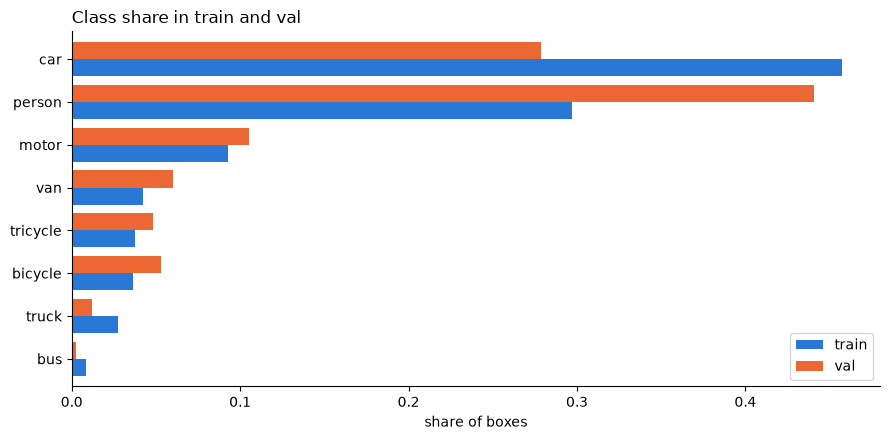

class_name
car         505301
person      328701
motor       102819
van          46940
tricycle     41349
bicycle      40255
truck        30498
bus           9653
Name: count, dtype: int64
car / bus: 52.3


In [16]:
share = pd.DataFrame({'train': real_train.class_name.value_counts(normalize=True),
                      'val': real_val.class_name.value_counts(normalize=True)}).sort_values('train')

fig, ax = plt.subplots(figsize=(9, 4.5))
share.plot.barh(ax=ax, color=[COLORS['train'], COLORS['val']], width=0.8)
ax.set_xlabel('share of boxes')
ax.set_ylabel('')
ax.set_title('Class share in train and val', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print(real_train.class_name.value_counts())
print('car / bus:', round((real_train.class_name == 'car').sum() / (real_train.class_name == 'bus').sum(), 1))

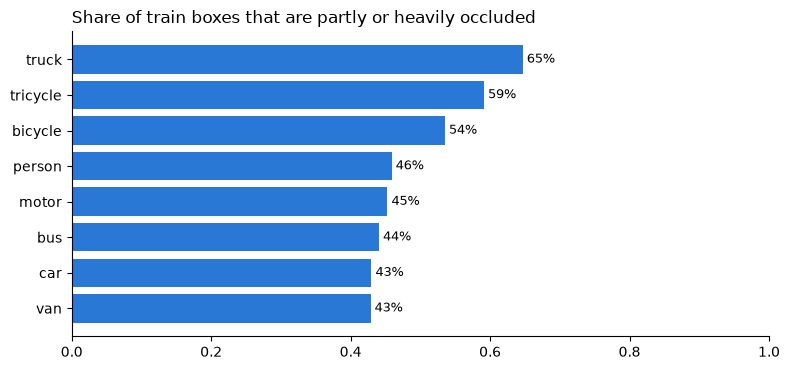

In [17]:
occluded = real_train.groupby('class_name').occlusion.apply(lambda s: (s > 0).mean()).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(occluded.index, occluded.values, color=COLORS['train'])
for y, v in enumerate(occluded.values):
    ax.text(v, y, f' {v:.0%}', va='center', fontsize=9)
ax.set_xlim(0, 1)
ax.set_title('Share of train boxes that are partly or heavily occluded', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

Car and person make up about 75% of train boxes, and there are 52 cars for every bus. Val has the opposite order (person 44%, car 28%), and bus has only 264 val boxes, so its val AP will be noisy. Results should be read per class, not only as one number.

Between 43% and 65% of the boxes in every class are partly or heavily occluded, with truck the highest. Scenes are crowded, so an aggressive NMS could remove real neighbouring objects.

### Where objects are and how many

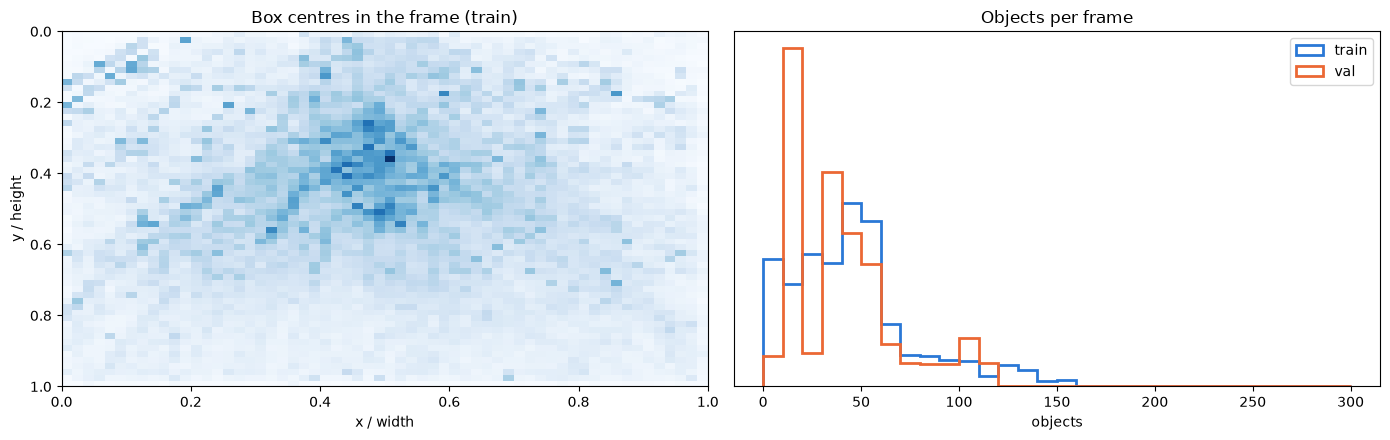

count    24198.0
mean        45.7
std         31.6
min          1.0
25%         22.0
50%         43.0
75%         57.0
max        180.0
dtype: float64


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist2d(real_train.cx, real_train.cy, bins=60, range=[[0, 1], [0, 1]], cmap='Blues')
axes[0].invert_yaxis()
axes[0].set_title('Box centres in the frame (train)')
axes[0].set_xlabel('x / width')
axes[0].set_ylabel('y / height')

per_frame = {'train': real_train.groupby('image_id').size(), 'val': real_val.groupby('image_id').size()}
bins = np.arange(0, 301, 10)
for name, counts in per_frame.items():
    axes[1].hist(counts, bins=bins, density=True, histtype='step', lw=2, color=COLORS[name], label=name)
axes[1].set_title('Objects per frame')
axes[1].set_xlabel('objects')
axes[1].set_yticks([])
axes[1].legend()

plt.tight_layout()
plt.show()

print(per_frame['train'].describe().round(1))

Objects gather around the centre and upper middle of the frame, because the camera looks down at an angle. A horizontal flip keeps this geometry, a vertical flip does not, so vertical flips stay off.

The median train frame has 43 objects and the densest has 180. That is below the 300 queries RT-DETR uses by default and the 500 detections scored per image, so neither limit should cut real objects. Val has more sparse frames than train, with a clear peak at 10-20 objects.

### How much clips differ
A dataset average can hide large differences between sequences, so repeat the main statistics for each clip.

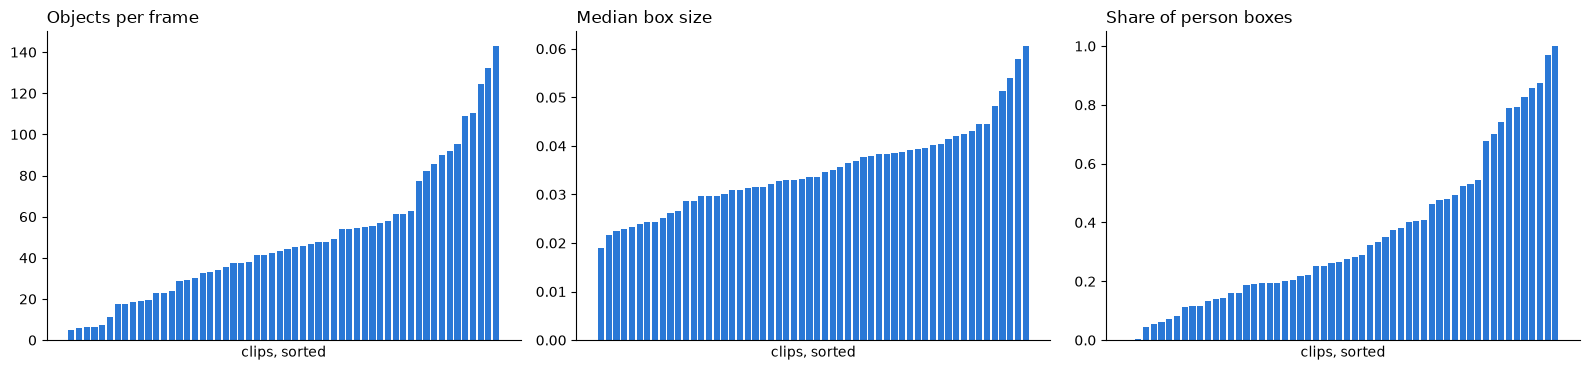

,objects_per_frame,box_size,person_share
min,5.147,0.019,0.000
50%,43.764,0.034,0.271
max,142.962,0.061,1.000


In [19]:
per_clip = real_train.groupby('video').agg(boxes=('id', 'size'), frames=('image_id', 'nunique'),
                                           box_size=('rel_size', 'median'))
per_clip['objects_per_frame'] = per_clip.boxes / per_clip.frames
per_clip['person_share'] = real_train.class_name.eq('person').groupby(real_train.video).mean()

columns = [('objects_per_frame', 'Objects per frame'), ('box_size', 'Median box size'),
           ('person_share', 'Share of person boxes')]

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (col, title) in zip(axes, columns):
    values = per_clip[col].sort_values().to_numpy()
    ax.bar(range(len(values)), values, width=0.8, color=COLORS['train'])
    ax.set_title(title, loc='left')
    ax.set_xlabel('clips, sorted')
    ax.set_xticks([])
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

per_clip[[c for c, _ in columns]].describe().loc[['min', '50%', 'max']].round(3)

Clips are very different. Objects per frame go from 5 to 143 (median 44), median box size from 0.019 to 0.061 of the frame, and the share of person boxes from 0% to 100%. This is why the splits are made by clip, and why one validation number depends so much on which clips are in val.

### Ignore regions
Objects inside a region are visible but not labelled, so a detector would be punished for finding them. The usual fix is to paint the regions out. Before doing that, check how much of the frame they cover and whether real boxes sit inside them.

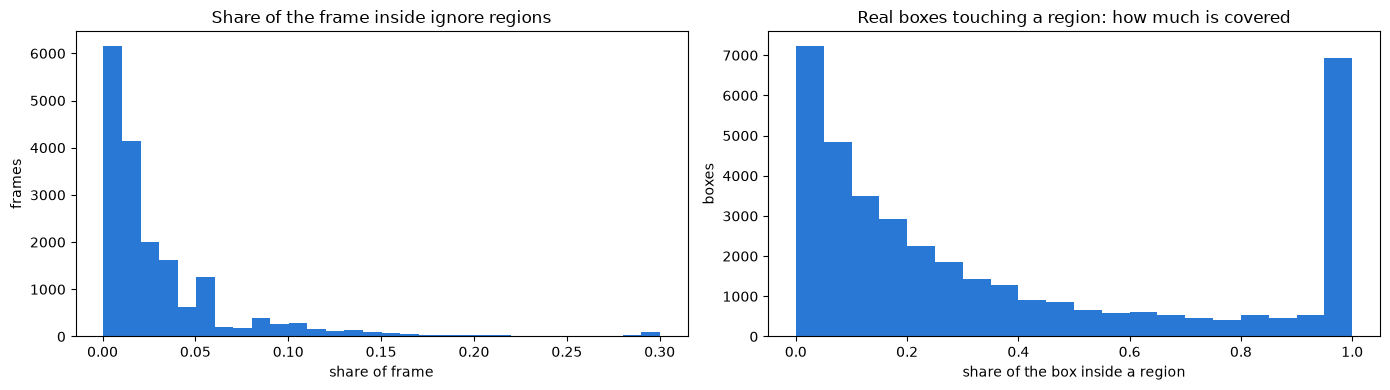

frames with regions: 18090 of 24201
mean frame coverage: 0.0323
real boxes touching a region: 38801
real boxes more than half covered: 11733


In [20]:
pairs = real_train[['id', 'image_id', 'x', 'y', 'w', 'h']].merge(
    regions[['image_id', 'x', 'y', 'w', 'h']], on='image_id', suffixes=('', '_r'))
overlap_w = (np.minimum(pairs.x + pairs.w, pairs.x_r + pairs.w_r) - np.maximum(pairs.x, pairs.x_r)).clip(lower=0)
overlap_h = (np.minimum(pairs.y + pairs.h, pairs.y_r + pairs.h_r) - np.maximum(pairs.y, pairs.y_r)).clip(lower=0)
pairs['covered'] = overlap_w * overlap_h / (pairs.w * pairs.h)
covered = pairs.groupby('id').covered.max()

coverage = (regions.w * regions.h / (regions.width * regions.height)).groupby(regions.image_id).sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(coverage.clip(upper=0.3), bins=30, color=COLORS['train'])
axes[0].set_title('Share of the frame inside ignore regions')
axes[0].set_xlabel('share of frame')
axes[0].set_ylabel('frames')
axes[1].hist(covered[covered > 0], bins=20, color=COLORS['train'])
axes[1].set_title('Real boxes touching a region: how much is covered')
axes[1].set_xlabel('share of the box inside a region')
axes[1].set_ylabel('boxes')
plt.tight_layout()
plt.show()

print('frames with regions:', coverage.size, 'of', len(train_images))
print('mean frame coverage:', round(coverage.mean(), 4))
print('real boxes touching a region:', (covered > 0).sum())
print('real boxes more than half covered:', (covered > 0.5).sum())

Regions appear on 18,090 of 24,201 frames (75%), but they cover only about 3.2% of a frame on average, so painting them removes little. However, 38,801 real boxes touch a region and 11,733 are more than half inside one. The peak at 1.0 shows many labelled objects sit fully inside a region.

Decision: paint the regions, then copy every labelled box back.

### Train vs test
Test has no labels, so compare what is available: resolution, clip length and the images themselves.

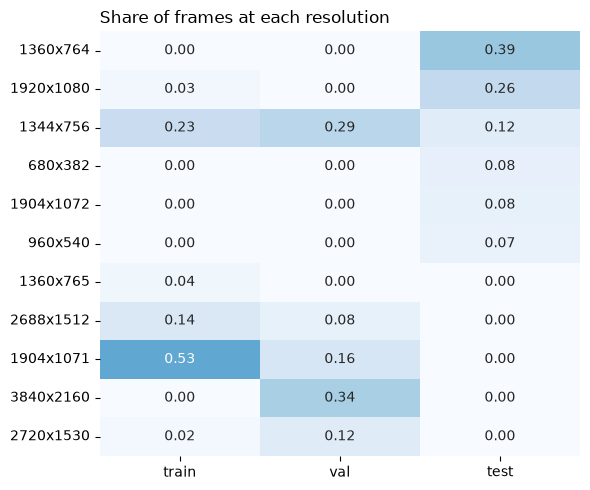

In [21]:
def resolution_share(df):
    return (df.width.astype(str) + 'x' + df.height.astype(str)).value_counts(normalize=True)


resolutions = pd.DataFrame({'train': resolution_share(train_images), 'val': resolution_share(val_images),
                            'test': resolution_share(test_images)}).fillna(0)
resolutions = resolutions.sort_values('test', ascending=False)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(resolutions, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=ax)
ax.set_title('Share of frames at each resolution', loc='left')
plt.tight_layout()
plt.show()

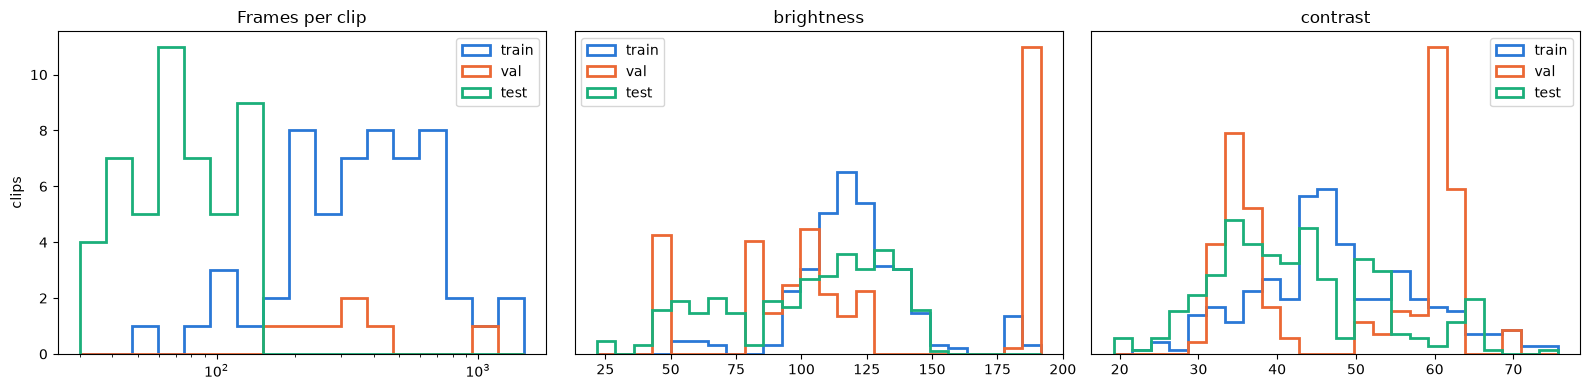

        train    val   test
count    56.0    7.0   48.0
min      58.0  184.0   35.0
50%     383.5  349.0   73.5
max    1424.0  978.0  148.0
            train    val   test
brightness  120.5  122.1  101.6
contrast     47.5   48.5   42.5


In [22]:
lengths = {'train': train_images.groupby('video').size(), 'val': val_images.groupby('video').size(),
           'test': test_images.groupby('clip').size()}


def image_stats(files, n=300):
    rows = []
    for f in pd.Series(files).sample(n, random_state=42):
        gray = cv2.imread(str(DATA / f), cv2.IMREAD_GRAYSCALE)
        rows.append({'brightness': gray.mean(), 'contrast': gray.std()})
    return pd.DataFrame(rows)


stats = {'train': image_stats('train/' + train_images.file_name),
         'val': image_stats('val/' + val_images.file_name),
         'test': image_stats(test_images.file_name)}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
bins = np.geomspace(30, 1500, 18)
for name, values in lengths.items():
    axes[0].hist(values, bins=bins, histtype='step', lw=2, color=COLORS[name], label=name)
axes[0].set_xscale('log')
axes[0].set_title('Frames per clip')
axes[0].set_ylabel('clips')
axes[0].legend()

for ax, col in zip(axes[1:], ['brightness', 'contrast']):
    both = pd.concat([s[col] for s in stats.values()])
    bins = np.linspace(both.min(), both.max(), 25)
    for name, s in stats.items():
        ax.hist(s[col], bins=bins, density=True, histtype='step', lw=2, color=COLORS[name], label=name)
    ax.set_title(col)
    ax.set_yticks([])
    ax.legend()

plt.tight_layout()
plt.show()

print(pd.DataFrame({k: v.describe() for k, v in lengths.items()}).loc[['count', 'min', '50%', 'max']])
print(pd.DataFrame({k: v.mean() for k, v in stats.items()}).round(1))

- **Resolution:** only 1344x756 and 1920x1080 appear in both train and test. Test frames are never larger than 1920x1080, and about 16% are low resolution (680x382 or 960x540), while train goes up to 2720x1530. Frames are not resized on disk, because the model input size handles this.
- **Val:** 34% of val frames are 3840x2160, so one kind of footage has a large effect on val scores.
- **Clip length:** test clips are short (35-148 frames) compared with train (58-1,424).
- **Images:** on 300 sampled frames per split, test is darker (mean brightness 101.6 vs 120.5) and has lower contrast (42.5 vs 47.5). Brightness augmentation should help. Val forms separate groups because it has only 7 clips.

### Image quality per clip
The brightness gap above is an average over frames, so look at it per clip, together with sharpness. Plain sharpness depends on the scene (a city has more edges than a field), so the measure here is the ratio of fine detail at 640 px to detail at 320 px width (variance of the Laplacian). Scene texture shows at both scales and cancels out, while blur, upscaling and compression remove mostly the fine detail. Three frames per clip.

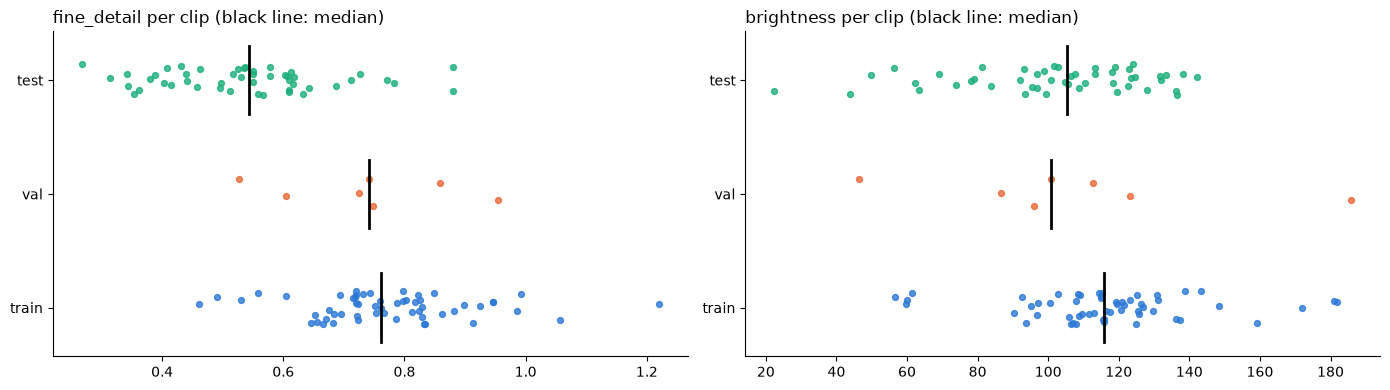

       fine_detail  brightness
split                         
test          0.54      105.20
train         0.76      115.68
val           0.74      100.74
split  test  train   val
width                   
680    0.31    NaN   NaN
960    0.44    NaN   NaN
1344   0.52   0.75  0.73
1360   0.56   0.72   NaN
1904   0.59   0.76  0.73
1920   0.63   1.22   NaN
2688    NaN   0.82  0.75
2720    NaN   0.74  0.53
3840    NaN    NaN  0.95
test: 48 clips, 7 with brightness under 70, 3 under 50
train: 56 clips, 4 with brightness under 70, 0 under 50
val: 7 clips, 1 with brightness under 70, 1 under 50


In [23]:
def detail(gray, width):
    height = round(gray.shape[0] * width / gray.shape[1])
    small = cv2.resize(gray, (width, height), interpolation=cv2.INTER_AREA).astype(np.float32)
    return cv2.Laplacian(small, cv2.CV_32F).var()


def fine_detail(gray):
    return detail(gray, 640) / detail(gray, 320)


def clip_quality(split, frames, clip_column, folder):
    rows = []
    for clip, group in frames.groupby(clip_column):
        for file in group.file_name.iloc[np.linspace(0, len(group) - 1, 3).astype(int)]:
            gray = cv2.imread(str(folder / file), cv2.IMREAD_GRAYSCALE)
            rows.append({'split': split, 'clip': clip, 'width': gray.shape[1], 'fine_detail': fine_detail(gray),
                         'brightness': cv2.resize(gray, (480, 270), interpolation=cv2.INTER_AREA).mean()})
    return pd.DataFrame(rows).groupby(['split', 'clip']).agg(
        brightness=('brightness', 'mean'), fine_detail=('fine_detail', 'mean'), width=('width', 'first')).reset_index()


quality = pd.concat([clip_quality('train', train_images, 'video', DATA / 'train'),
                     clip_quality('val', val_images, 'video', DATA / 'val'),
                     clip_quality('test', test_images, 'clip', DATA)])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['fine_detail', 'brightness']):
    for k, split in enumerate(['train', 'val', 'test']):
        values = quality[quality.split == split][col]
        ax.scatter(values, np.full(len(values), k) + np.random.default_rng(k).uniform(-0.15, 0.15, len(values)),
                   s=18, color=COLORS[split], alpha=0.8)
        ax.plot([values.median()] * 2, [k - 0.3, k + 0.3], color='black', lw=2)
    ax.set_yticks([0, 1, 2], ['train', 'val', 'test'])
    ax.set_title(f'{col} per clip (black line: median)', loc='left')
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print(quality.groupby('split')[['fine_detail', 'brightness']].median().round(2))
print(quality.pivot_table(index='width', columns='split', values='fine_detail', aggfunc='median').round(2))
for split, group in quality.groupby('split'):
    print(f'{split}: {len(group)} clips, {(group.brightness < 70).sum()} with brightness under 70, '
          f'{(group.brightness < 50).sum()} under 50')

- **Test is blurrier than train and val.** The fine-detail ratio has a median of 0.54 on test clips against 0.76 on train and 0.74 on val, and test is lower at every resolution that both have (1344 px: 0.52 vs 0.75, 1360 px: 0.56 vs 0.72, 1904 px: 0.59 vs 0.76). So it is the footage (stronger compression or upscaling), not the scenes. The low-resolution test clips are the blurriest (680 px: 0.31, 960 px: 0.44).
- **Test has darker clips.** 7 of 48 test clips have a mean brightness under 70 and 3 under 50; train has 4 of 56 under 70 and none under 50.
- **Val does not show this.** Val is as sharp as train, so val mAP overestimates what a model does on test frames, and a model that copes better with blur cannot win on val alone.

Decisions, in the preprocessing below: train on a mix where half the frames are degraded to test quality, and score the final candidates also on a copy of the test-like val frames degraded the same way (`mAP_blur`).

### Labels across frames and clips
Three checks on the training labels: whether an object keeps its box in every frame of its track, how much each clip gives to the training subset, and how object size depends on resolution.

In [24]:
tracks = real_train.dropna(subset=['track_id']).groupby(['video', 'track_id']).frame_id.agg(['min', 'max', 'count'])
span = tracks['max'] - tracks['min'] + 1
print(f'{len(tracks)} tracks; frames inside a track where the object has no box: {1 - tracks["count"].sum() / span.sum():.1%}')

per_clip_frames = train_images[train_images.groupby('video').cumcount() % 5 == 0].groupby('video').size()
print(f'every 5th frame: {per_clip_frames.sum()} frames from {len(per_clip_frames)} clips, '
      f'the 5 longest clips give {per_clip_frames.nlargest(5).sum() / per_clip_frames.sum():.0%}, '
      f'frames per clip {per_clip_frames.min()}-{per_clip_frames.max()}')

side = np.sqrt(real_train.w * real_train.h)
by_resolution = pd.DataFrame({
    'train frames': resolution_share(train_images), 'test frames': resolution_share(test_images),
    'median box side, px': side.groupby(real_train.width.astype(str) + 'x' + real_train.height.astype(str)).median()})
display(by_resolution.round(2))

7342 tracks; frames inside a track where the object has no box: 6.4%
every 5th frame: 4868 frames from 56 clips, the 5 longest clips give 22%, frames per clip 12-285


,train frames,test frames,"median box side, px"
1344x756,0.23,0.12,32.98
1360x764,NaN,0.39,NaN
1360x765,0.04,NaN,31.50
1904x1071,0.53,NaN,47.74
1904x1072,NaN,0.08,NaN
1920x1080,0.03,0.26,38.21
2688x1512,0.14,NaN,54.22
2720x1530,0.02,NaN,58.09
680x382,NaN,0.08,NaN
960x540,NaN,0.07,NaN


- **Track gaps:** an object is missing from the labels in 6.4% of the frames between its first and last appearance (full occlusion or a skipped label). Some "false positives" on val are therefore real objects. The gaps are not filled, because a fully occluded object must not get a box; the temporal rescoring at the end uses the same fact from the other side.
- **Clip balance:** with every 5th frame the 5 longest of 56 clips give 22% of the training frames and a clip gives 12-285 frames. Test clips are short (35-148 frames), so each test clip counts about the same. The frame-step experiment in the pipeline tests how much more variety helps.
- **Resolution:** 39% of test frames are 1360x764, against 4% of train; objects at 1344-1360 px have a median side of 31-33 px, at 1904 px 48 px. Training at 1280 px keeps 1360 px frames near their native size, which is one reason the 1280 px recipes work better.

### How similar are neighbouring frames?
Video frames are not independent, so check how fast a clip changes: the mean pixel difference between a frame and the frame `gap` steps later.

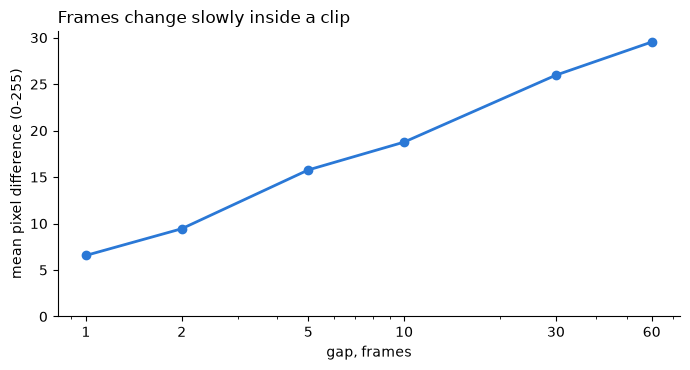

gap
1      6.6
2      9.4
5     15.8
10    18.8
30    26.0
60    29.5
Name: diff, dtype: float64


In [25]:
def small_gray(file_name):
    gray = cv2.imread(str(DATA / 'train' / file_name), cv2.IMREAD_GRAYSCALE)
    return cv2.resize(gray, (320, 180)).astype(float)


gaps = [1, 2, 5, 10, 30, 60]
long_clips = train_images.groupby('video').size().loc[lambda s: s >= 200].index
rows = []

for clip in pd.Series(long_clips).sample(8, random_state=42):
    files = train_images[train_images.video == clip].sort_values('frame_id').file_name.tolist()
    for start in np.linspace(0, len(files) - max(gaps) - 1, 4).astype(int):
        first = small_gray(files[start])
        for gap in gaps:
            rows.append({'clip': clip, 'gap': gap, 'diff': np.abs(first - small_gray(files[start + gap])).mean()})

change = pd.DataFrame(rows).groupby('gap')['diff'].median()

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(change.index, change.values, marker='o', lw=2, color=COLORS['train'])
ax.set_xscale('log')
ax.set_xticks(gaps, labels=gaps)
ax.set_ylim(0)
ax.set_xlabel('gap, frames')
ax.set_ylabel('mean pixel difference (0-255)')
ax.set_title('Frames change slowly inside a clip', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print(change.round(1))

The difference is 6.6 at a gap of 1, 15.8 at a gap of 5 and 29.5 at a gap of 60 (8 clips, 4 start points each). A gap of 5 already reaches over half of the change seen at 60, so every 5th frame keeps most of the variety for a fifth of the training cost. This is why `TRAIN_STRIDE = 5`.

The stride does not balance the clips: a long clip still gives more frames than a short one.

## Data cleaning: `clean()`
One deterministic function for train and val. It works row by row and learns nothing from the data, so there is no leakage between folds.
- `iscrowd=1`: removed from the targets, one copy of each region kept as `ignore`;
- class ids: shifted from 1-8 to the 0-7 used in the YOLO labels.

In [26]:
def clean(boxes: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    real = boxes[boxes.iscrowd == 0].copy()
    real['cls'] = real.category_id - 1
    ignore = boxes[boxes.iscrowd == 1].drop_duplicates(['image_id', 'x', 'y', 'w', 'h'])
    return real, ignore


train_clean, train_ignore = clean(train_boxes)
val_clean, val_ignore = clean(val_boxes)

print('Train:', len(train_clean), 'boxes,', len(train_ignore), 'ignore regions')
print('Val:', len(val_clean), 'boxes,', len(val_ignore), 'ignore regions')

Train: 1105516 boxes, 63843 ignore regions
Val: 114132 boxes, 3995 ignore regions


## Splits by clip
A random split would put almost identical frames on both sides, so `GroupKFold` keeps each clip in one fold. The provided train and val share no clips.

,clips,frames
fold,,
0,12,4952
1,11,4316
2,11,6057
3,11,4874
4,11,4002


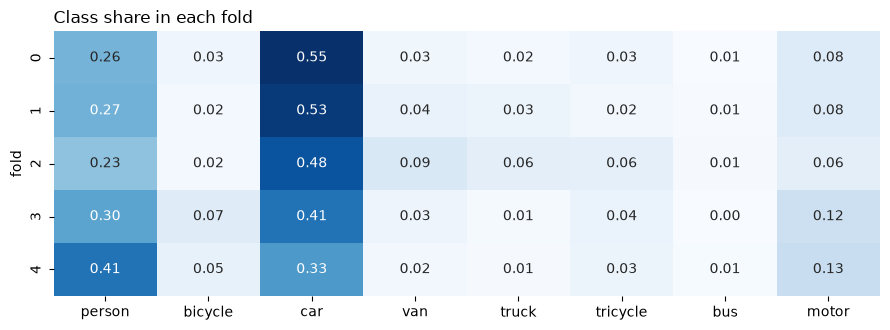

In [27]:
assert not set(train_images.video) & set(val_images.video)

gkf = GroupKFold(n_splits=5, shuffle=True, random_state=42)
train_images['fold'] = -1
for k, (_, rows) in enumerate(gkf.split(train_images, groups=train_images.video)):
    train_images.loc[train_images.index[rows], 'fold'] = k

display(train_images.groupby('fold').agg(clips=('video', 'nunique'), frames=('image_id', 'size')))

folds = real_train.assign(fold=real_train.image_id.map(train_images.set_index('image_id').fold))
fold_share = pd.crosstab(folds.fold, folds.class_name, normalize='index')[CLASSES]

fig, ax = plt.subplots(figsize=(9, 3.4))
sns.heatmap(fold_share, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=ax)
ax.set_title('Class share in each fold', loc='left')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

Folds differ a lot: car share goes from 33% to 55%, and fold size from 4,002 to 6,057 frames. A single split depends heavily on which clips it contains.

Five folds per detector do not fit the GPU budget, so all detectors are compared on the provided val split, which shares no clips with train.

In [28]:
TRAIN_STRIDE = 5

train_subset = train_images[train_images.groupby('video').cumcount() % TRAIN_STRIDE == 0]
print('Train frames:', len(train_images), '->', len(train_subset))

subset_boxes = real_train[real_train.image_id.isin(train_subset.image_id)]
compare = pd.DataFrame({'all frames': real_train.class_name.value_counts(normalize=True),
                        'every 5th frame': subset_boxes.class_name.value_counts(normalize=True)}).sort_values('all frames')
compare['diff'] = compare['all frames'] - compare['every 5th frame']
print(compare.round(4))

Train frames: 24201 -> 4868
            all frames  every 5th frame    diff
class_name                                     
bus             0.0087           0.0087  0.0000
truck           0.0276           0.0275  0.0001
bicycle         0.0364           0.0365 -0.0001
tricycle        0.0374           0.0374 -0.0000
van             0.0425           0.0424  0.0001
motor           0.0930           0.0929  0.0001
person          0.2973           0.2977 -0.0004
car             0.4571           0.4568  0.0003


Class shares change by at most 0.04 percentage points, so the subset keeps the class balance.

## Build the training folder
Ignore regions are painted grey, then every labelled box is copied back so no real object is lost. Val is painted too, otherwise detections of unlabelled objects would count as false positives. The competition does not penalise detections inside ignore regions, but test has no ignore files and stays as it is, so val scores are only a guide to the leaderboard.

Frames without regions are symlinks to the originals. A second folder, `train_dense`, holds every 3rd frame for Experiment 14. The folder, together with the test frames, is saved to Drive as `prep.tar`, so a GPU runtime does not need the full dataset.

In [29]:
PREP = Path('/content/prep' if IN_COLAB else 'prep').resolve()
MASK_VALUE = 114


def mask_frame(image, regions, objects):
    masked = image.copy()
    for x, y, w, h in regions:
        masked[y:y + h, x:x + w] = MASK_VALUE
    for x, y, w, h in objects:
        masked[y:y + h, x:x + w] = image[y:y + h, x:x + w]
    return masked


def boxes_by_image(boxes):
    return {k: v.to_numpy(int) for k, v in boxes.groupby('image_id')[['x', 'y', 'w', 'h']]}


def link_or_copy(source, target):
    # symlinks need extra rights on Windows, so fall back to a hard link or a copy
    try:
        target.symlink_to(source)
    except OSError:
        try:
            os.link(source, target)
        except OSError:
            shutil.copy(source, target)


def build_split(split, images, real, ignore, folder=None):
    folder = folder or split
    shutil.rmtree(PREP / folder, ignore_errors=True)
    regions, objects = boxes_by_image(ignore), boxes_by_image(real)
    no_boxes = np.empty((0, 4), int)

    for r in tqdm(images.itertuples(), total=len(images), desc=split):
        label = Path(r.file_name).relative_to('images').with_suffix('.txt')
        image_path = PREP / folder / r.file_name
        label_path = PREP / folder / 'labels' / label
        image_path.parent.mkdir(parents=True, exist_ok=True)
        label_path.parent.mkdir(parents=True, exist_ok=True)

        source = DATA / split / r.file_name
        if r.image_id in regions:
            image = cv2.imread(str(source))
            masked = mask_frame(image, regions[r.image_id], objects.get(r.image_id, no_boxes))
            cv2.imwrite(str(image_path), masked, [cv2.IMWRITE_JPEG_QUALITY, 95])
        else:
            link_or_copy(source, image_path)
        shutil.copy(DATA / split / 'labels' / label, label_path)


build_split('train', train_subset, train_clean, train_ignore)
build_split('val', val_images, val_clean, val_ignore)

DENSE_STRIDE = 3
dense_done = PREP / 'train_dense' / 'done.txt'
if not dense_done.exists():
    dense_subset = train_images[train_images.groupby('video').cumcount() % DENSE_STRIDE == 0]
    build_split('train', dense_subset, train_clean, train_ignore, folder='train_dense')
    dense_done.write_text(str(len(dense_subset)))
print('every 3rd frame:', dense_done.read_text(), 'frames in', PREP / 'train_dense')

data_yaml = PREP / 'data.yaml'
data_yaml.write_text(f"path: {PREP.resolve()}\ntrain: train/images\nval: val/images\n"
                     f"nc: {len(CLASSES)}\nnames: {json.dumps(CLASSES)}\n")
print(data_yaml.read_text())

train: 100%|██████████| 8090/8090 [01:02<00:00, 130.10it/s]

every 3rd frame: 8090 frames in /home/akulba/Documents/ai-ucu-hw-2/prep/train_dense
path: /home/akulba/Documents/ai-ucu-hw-2/prep
train: train/images
val: val/images
nc: 8
names: ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]



In [30]:
if IN_COLAB:
    local_archive = Path('/content/prep.tar')
    !tar -chf {local_archive} -C {DATA} test test_images.csv -C {PREP} train val data.yaml
    size_gb = local_archive.stat().st_size / 1e9
    free_gb = shutil.disk_usage(DRIVE).free / 1e9
    print(f'Archive: {size_gb:.1f} GB, free on Drive: {free_gb:.1f} GB')
    assert size_gb < free_gb, 'Not enough space on Drive for the archive'
    shutil.copy(local_archive, f'{PREP_ARCHIVE}.part')
    os.replace(f'{PREP_ARCHIVE}.part', PREP_ARCHIVE)
    local_archive.unlink()

Check that nothing was lost: every frame has an image and a label file, and the number of boxes matches `clean()`.

In [31]:
for split, images, real in [('train', train_subset, train_clean), ('val', val_images, val_clean)]:
    n_images = len(list((PREP / split / 'images').rglob('*.jpg')))
    labels = list((PREP / split / 'labels').rglob('*.txt'))
    n_boxes = sum(len(p.read_text().splitlines()) for p in labels)
    expected = real.image_id.isin(images.image_id).sum()
    print(f'{split}: {n_images} images, {len(labels)} labels, {n_boxes} boxes (expected {expected})')
    assert n_images == len(labels) == len(images) and n_boxes == expected

train: 4868 images, 4868 labels, 222879 boxes (expected 222879)
val: 2846 images, 2846 labels, 114132 boxes (expected 114132)


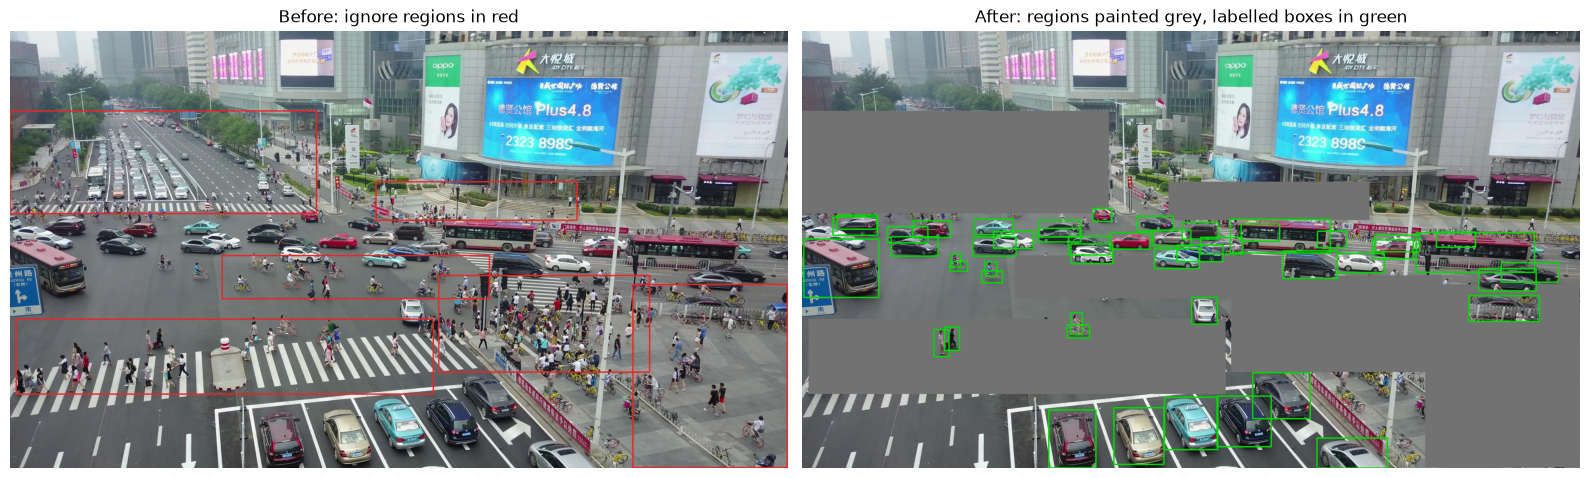

In [32]:
area = train_ignore[train_ignore.image_id.isin(train_subset.image_id)]
area = (area.w * area.h / (area.width * area.height)).groupby(area.image_id).sum()
frame = train_subset[train_subset.image_id == area.idxmax()].iloc[0]
boxes = train_clean[train_clean.image_id == frame.image_id]
regions_in_frame = train_ignore[train_ignore.image_id == frame.image_id]

before = cv2.cvtColor(cv2.imread(str(DATA / 'train' / frame.file_name)), cv2.COLOR_BGR2RGB)
after = cv2.cvtColor(cv2.imread(str(PREP / 'train' / frame.file_name)), cv2.COLOR_BGR2RGB)
draw_boxes(before, regions_in_frame, (230, 40, 40))
draw_boxes(after, boxes, (0, 220, 0))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(before)
axes[0].set_title('Before: ignore regions in red')
axes[1].imshow(after)
axes[1].set_title('After: regions painted grey, labelled boxes in green')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Resizing, normalization and augmentation
- **Resizing:** frames stay at their original size on disk. Ultralytics letterboxes them to `imgsz` keeping the aspect ratio; torchvision models resize them to the same 960 px long side.
- **Normalization:** pixel values are divided by 255 inside the framework.
- **Augmentation:** Ultralytics defaults: mosaic (turned off for the last 10 epochs), horizontal flip with probability 0.5, scale 0.5, translate 0.1, and HSV jitter (`hsv_v=0.4` covers the brightness gap with test). Torchvision models use horizontal flips. `flipud` stays 0, as explained above.
- **Test image quality:** half of the training frames of Experiment 10 are degraded offline to the sharpness and brightness of test (see *Test image quality*); the other models train on the prepared frames.
- **Reproducibility:** `seed=42` for training, `random_state=42` for sampling; `TRAIN_STRIDE`, `TRAIN_STEP`, `IMGSZ` and `EPOCHS` are set in the notebook.

## Preprocessing summary

| Check | Result |
|---|---|
| Missing values | Only on the `iscrowd=1` rows |
| Impossible values: box size, frame bounds, duplicates | None in real boxes |
| `iscrowd=1` rows | Ignore regions copied 8 times, removed from targets and painted grey |
| `clean()` | Same function for train and val |
| Imputation, one-hot encoding | Not needed: boxes have no missing values and classes are already numbers |
| Train vs test | Different resolutions; test clips are shorter and darker |
| Splits | `GroupKFold` by clip, no clip on both sides |
| Subsampling | `TRAIN_STRIDE = 5`: 24,201 -> 4,868 frames |
| Image quality | Test is blurrier (fine-detail ratio 0.54 vs 0.76) and has darker clips; half of the Experiment 10 frames are degraded to match, and val is also scored on a degraded copy |
| Track gaps | 6.4% of frames inside a track have no box; kept as they are |
| Every 3rd frame | `train_dense`, built the same way, for Experiment 14 |

## Detector setup
All detectors are trained under one protocol and scored by one evaluator, so differences come from the model and not from the setup.

In [33]:
PREP = Path('/content/prep' if IN_COLAB else 'prep').resolve()
VAL_JSON = Path(DRIVE) / 'val_annotations_coco.json'

if not (PREP / 'test_images.csv').exists() and Path(PREP_ARCHIVE).exists():
    PREP.mkdir(exist_ok=True)
    !tar -xf {PREP_ARCHIVE} -C {PREP}

DATA = Path(path) if 'path' in globals() else PREP
if not VAL_JSON.exists():
    source = DATA / 'val' / 'annotations_coco.json'
    if not source.exists():
        os.environ['KAGGLE_API_TOKEN'] = os.environ.get('KAGGLE_API_TOKEN') or getpass('Kaggle API token: ')
        source = kagglehub.competition_download(COMPETITION, path='val/annotations_coco.json')
    shutil.copy(source, VAL_JSON)

test_images = pd.read_csv(DATA / 'test_images.csv')
print('Device:', 'GPU' if torch.cuda.is_available() else 'CPU', ' training folder:', (PREP / 'data.yaml').exists())

Device: GPU  training folder: True


In [34]:
IMGSZ = 960
MIN_SIDE = IMGSZ * 9 // 16
TRAIN_STEP = 3
EPOCHS = 1 if SMOKE_TEST else 4
BATCH = 4
LR = 0.005
MAX_DET = 500
SCORE_THRESHOLD = 0.01
NMS_IOU = 0.7
SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
WORKERS = min(8, os.cpu_count()) if DEVICE == 'cuda' and os.name != 'nt' else 0


def label_path(image_path):
    return Path(str(image_path).replace(f'{os.sep}images{os.sep}', f'{os.sep}labels{os.sep}')).with_suffix('.txt')


def read_labels(image_path):
    path = label_path(image_path)
    return np.loadtxt(path, ndmin=2).reshape(-1, 5) if path.stat().st_size else np.zeros((0, 5))


def write_frame_list(name, frames):
    (PREP / f'{name}.txt').write_text(''.join(f'{p}\n' for p in frames))
    yaml = PREP / f'{name}.yaml'
    yaml.write_text(f'path: {PREP}\ntrain: {name}.txt\nval: val_protocol.txt\n'
                    f'nc: {len(CLASSES)}\nnames: {json.dumps(CLASSES)}\n')
    return yaml


PREPARED_FRAMES = sorted((PREP / 'train' / 'images').rglob('*.jpg'))
train_frames = PREPARED_FRAMES[::TRAIN_STEP]
val_coco = json.loads(VAL_JSON.read_text())
val_frames = [(im['id'], PREP / 'val' / im['file_name']) for im in val_coco['images']]
test_frames = [(i, DATA / f) for i, f in enumerate(test_images.file_name)]
if SMOKE_TEST:
    train_frames = train_frames[::len(train_frames) // 24][:24]
    val_frames = val_frames[::len(val_frames) // 12][:12]

(PREP / 'val_protocol.txt').write_text(''.join(f'{p}\n' for _, p in val_frames))
protocol_yaml = write_frame_list('train_protocol', train_frames)
print(f'{len(train_frames)} train frames x {EPOCHS} epochs, {len(val_frames)} val frames')

1623 train frames x 4 epochs, 2846 val frames


### Test image quality
Built from the image-quality analysis. `degrade` resamples a frame down and back up by a random factor from 0.35 to 0.9, makes it darker (gamma 1.3-2.0) in a quarter of the cases, and saves it as JPEG with quality 50-90. Boxes stay where they are, so the labels are copied unchanged. The range of factors comes from the calibration below: the fine-detail ratio of degraded train frames should cover the test range.

- **Training mix:** every prepared frame is replaced by its degraded copy with probability 0.5, so the number of frames and the training time stay the same.
- **Blurred val:** every test-like val frame is degraded once with a fixed seed. `mAP_blur` is the mAP on these frames, and `mAP_shift`, the mean of `mAP_testlike` and `mAP_blur`, selects the pipeline steps.

every 3rd frame mix: 4031 of 8090 frames degraded


training mix: 2473 of 4868 frames degraded; blurred val: 1286 frames
fine detail, 10th / 50th / 90th percentile:
  train frames: 0.67 / 0.78 / 0.91
  their degraded copies: 0.36 / 0.49 / 0.66
  test clips: 0.36 / 0.54 / 0.72


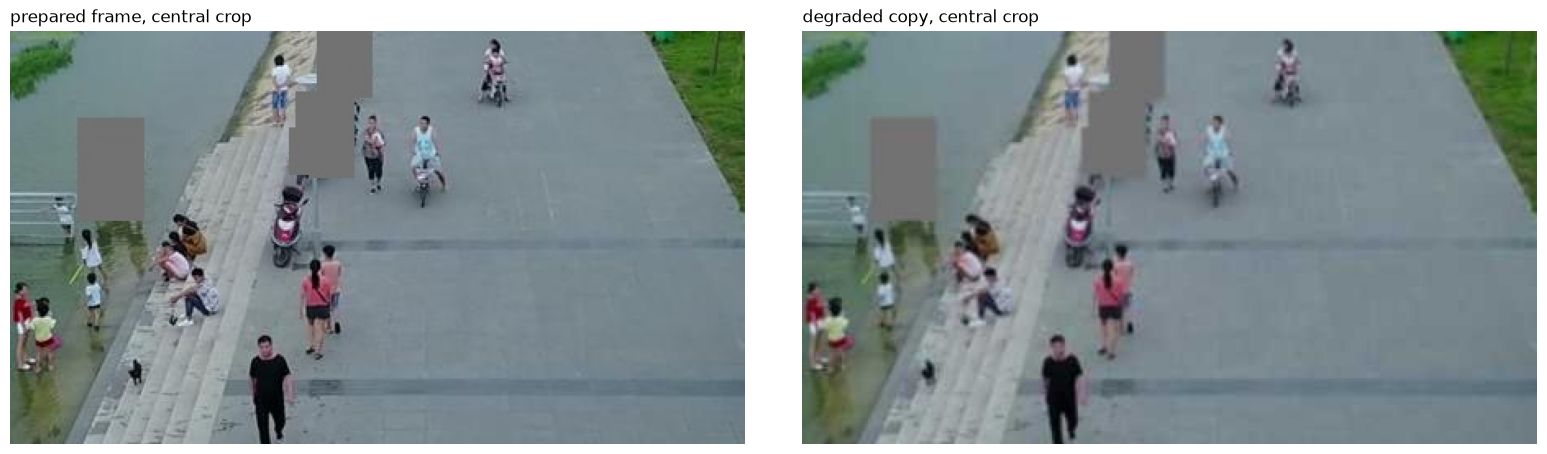

In [35]:
BLUR_ROOT = PREP / ('blur-smoke' if SMOKE_TEST else 'blur')
BLUR_SHARE = 0.5


def degrade(image, rng):
    height, width = image.shape[:2]
    scale = rng.uniform(0.35, 0.9)
    small = cv2.resize(image, (round(width * scale), round(height * scale)), interpolation=cv2.INTER_AREA)
    image = cv2.resize(small, (width, height), interpolation=cv2.INTER_LINEAR)
    if rng.random() < 0.25:
        image = cv2.LUT(image, (255 * (np.arange(256) / 255) ** rng.uniform(1.3, 2.0)).astype(np.uint8))
    return image, int(rng.integers(50, 91))


def degraded_copy(path, split, seed):
    target = BLUR_ROOT / split / path.relative_to(PREP / split)
    if not target.exists():
        target.parent.mkdir(parents=True, exist_ok=True)
        image, quality = degrade(cv2.imread(str(path)), np.random.default_rng(seed))
        part = target.with_suffix('.part.jpg')
        cv2.imwrite(str(part), image, [cv2.IMWRITE_JPEG_QUALITY, quality])
        os.replace(part, target)
        label_path(target).parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(label_path(path), label_path(target))
    return target


def degraded_copies(jobs):
    with ThreadPoolExecutor(max(1, WORKERS)) as pool:
        return list(tqdm(pool.map(lambda job: degraded_copy(*job), jobs), total=len(jobs), leave=False))


source_frames = train_frames if SMOKE_TEST else PREPARED_FRAMES
chosen = np.random.default_rng(SEED).random(len(source_frames)) < BLUR_SHARE
copies = iter(degraded_copies([(p, 'train', k) for k, p in enumerate(source_frames) if chosen[k]]))
BLUR_TRAIN_FRAMES = [next(copies) if pick else p for p, pick in zip(source_frames, chosen)]
BLUR_DATA = write_frame_list('train_blur_mix', BLUR_TRAIN_FRAMES)

dense_frames = train_frames if SMOKE_TEST else sorted((PREP / 'train_dense' / 'images').rglob('*.jpg'))
dense_chosen = np.random.default_rng(SEED + 1).random(len(dense_frames)) < BLUR_SHARE
dense_split = 'train' if SMOKE_TEST else 'train_dense'
dense_copies = iter(degraded_copies([(p, dense_split, k) for k, p in enumerate(dense_frames) if dense_chosen[k]]))
BLUR_DENSE_DATA = write_frame_list('train_dense_blur_mix',
                                   [next(dense_copies) if pick else p for p, pick in zip(dense_frames, dense_chosen)])
print(f'every 3rd frame mix: {dense_chosen.sum()} of {len(dense_frames)} frames degraded')

test_like = {im['id'] for im in val_coco['images'] if im['width'] <= 1920}
blur_frames = [(i, p) for (i, _), p in zip(
    [f for f in val_frames if f[0] in test_like],
    degraded_copies([(p, 'val', 1_000_000 + i) for i, p in val_frames if i in test_like]))]
print(f'training mix: {chosen.sum()} of {len(source_frames)} frames degraded; blurred val: {len(blur_frames)} frames')

check = [p for p, pick in zip(source_frames, chosen) if pick][::max(1, chosen.sum() // 40)]
before = [fine_detail(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)) for p in check]
after = [fine_detail(cv2.imread(str(BLUR_ROOT / 'train' / p.relative_to(PREP / 'train')), cv2.IMREAD_GRAYSCALE))
         for p in check]
test_detail = quality[quality.split == 'test'].fine_detail if 'quality' in globals() else pd.Series(dtype=float)
print('fine detail, 10th / 50th / 90th percentile:')
for name, values in [('train frames', before), ('their degraded copies', after), ('test clips', test_detail)]:
    if len(values):
        print(f'  {name}: ' + ' / '.join(f'{v:.2f}' for v in np.percentile(values, [10, 50, 90])))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, image, title in zip(axes, [check[0], BLUR_ROOT / 'train' / check[0].relative_to(PREP / 'train')],
                            ['prepared frame', 'degraded copy']):
    crop = cv2.cvtColor(cv2.imread(str(image)), cv2.COLOR_BGR2RGB)
    height, width = crop.shape[:2]
    ax.imshow(crop[height // 3:height // 3 + height // 3, width // 3:width // 3 + width // 3])
    ax.set_title(f'{title}, central crop', loc='left')
    ax.axis('off')
plt.tight_layout()
plt.show()

### Shared evaluator
COCO mAP, AP50, AP75, AP by object size and AP per class on the val frames. `AP_small` covers boxes under 32x32 px in the original frame. Ignore regions stay in the ground truth as `iscrowd=1`, so detections inside them are not penalised, as on the leaderboard, and `maxDets` is 500, the leaderboard limit.

Two additions, because val differs from test:
- `mAP_testlike`: mAP on the 4 val clips that are at most 1920 px wide (1,286 of 2,846 frames). The other 3 clips are 2688-3840 px wide, and no test frame is wider than 1920 px. 
- `mAP_blur`: mAP on the same test-like frames after `degrade`, the test image quality (pipeline runs only). `mAP_shift`, the mean of the two, is `SELECT_METRIC`, which picks the pipeline steps and the final model.
- `clip_<name>`: mAP of each of the 7 val clips. `paired` compares two runs clip by clip, which shows whether a gain holds on most clips or comes from one of them.

Every result goes to `experiment_log.csv` on Drive with the val predictions next to the weights, so finished runs are not repeated.

In [36]:
ground_truth = COCO(str(VAL_JSON))
LOG = Path(RUNS) / 'experiment_log.csv'
VAL_INFO = {im['id']: im for im in val_coco['images']}
VAL_IDS = [image_id for image_id, _ in val_frames]
TEST_LIKE_IDS = [i for i in VAL_IDS if VAL_INFO[i]['width'] <= 1920]
BLUR_IDS = [image_id for image_id, _ in blur_frames]
CLIP_IDS = {}
for image_id in VAL_IDS:
    CLIP_IDS.setdefault(VAL_INFO[image_id]['video'], []).append(image_id)


def coco_eval(results, image_ids):
    with contextlib.redirect_stdout(io.StringIO()):
        evaluation = COCOeval(ground_truth, results, 'bbox')
        evaluation.params.maxDets = [1, 100, MAX_DET]
        evaluation.params.imgIds = image_ids
        evaluation.evaluate()
        evaluation.accumulate()
        evaluation.summarize()
    return evaluation


def coco_metrics(rows):
    with contextlib.redirect_stdout(io.StringIO()):
        results = ground_truth.loadRes(rows)
    evaluation = coco_eval(results, VAL_IDS)
    names = ['mAP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large']
    metrics = dict(zip(names, [float(x) for x in evaluation.stats[:6]]))
    precision = evaluation.eval['precision'][:, :, :, 0, -1]
    for k, name in enumerate(CLASSES):
        values = precision[:, :, k]
        metrics[f'AP_{name}'] = float(values[values > -1].mean()) if (values > -1).any() else 0.0
    if TEST_LIKE_IDS:
        stats = coco_eval(results, TEST_LIKE_IDS).stats
        metrics.update(mAP_testlike=float(stats[0]), AP50_testlike=float(stats[1]), AP_small_testlike=float(stats[3]))
    for clip, ids in CLIP_IDS.items():
        metrics[f'clip_{clip}'] = float(coco_eval(results, ids).stats[0])
    return metrics


def blur_metrics(spec, metrics):
    rows = cached_rows(spec, 'blur')
    if not len(rows) or not BLUR_IDS:
        return {}
    with contextlib.redirect_stdout(io.StringIO()):
        results = ground_truth.loadRes(rows)
    blur = float(coco_eval(results, BLUR_IDS).stats[0])
    return {'mAP_blur': blur, 'mAP_shift': (metrics['mAP_testlike'] + blur) / 2}


def load_log():
    return pd.read_csv(LOG) if LOG.exists() else pd.DataFrame(columns=['run', 'section'])


def show(name):
    r = load_log().set_index('run').loc[name]
    like = f'  test-like {r.mAP_testlike:.3f}' if pd.notna(r.get('mAP_testlike')) else ''
    like += f'  blurred {r.mAP_blur:.3f}' if pd.notna(r.get('mAP_blur')) else ''
    print(f'{name}: mAP {r.mAP:.3f}{like}  AP50 {r.AP50:.3f}  AP_small {r.AP_small:.3f}  {r.ms_per_frame:.1f} ms/frame')


def finish(name, section, settings, rows, ms, minutes, **extra):
    assert drive_ok(), 'Google Drive is not mounted'
    (Path(RUNS) / name).mkdir(parents=True, exist_ok=True)
    np.save(Path(RUNS) / name / 'val_predictions.npy', rows)
    row = {'run': name, 'section': section, 'settings': settings, **coco_metrics(rows),
           'ms_per_frame': ms, 'train_minutes': minutes, **extra}
    if section == 'pipeline' and 'spec' in extra:
        row.update(blur_metrics(json.loads(extra['spec']), row))
    log = load_log()
    pd.concat([log[log.run != name], pd.DataFrame([row])], ignore_index=True).to_csv(LOG, index=False)
    show(name)


def should_run(name):
    if ONLY and name not in ONLY:
        return False
    if FORCE or name not in set(load_log().run):
        return True
    show(name)
    return False


def best_run(section):
    log = load_log()
    rows = log[(log.section == section) & ~log.run.str.endswith('-base')]
    return rows.nlargest(1, 'mAP').run.iloc[0] if len(rows) else None


def resolvable(spec):
    if spec['kind'] in ('torchvision', 'hf'):
        return spec['weights'] in TORCHVISION_BUILDERS
    return all(resolvable(child) for child in spec.get('members', []) + ([spec['base']] if 'base' in spec else []))


def add_blur_metric():
    log = load_log()
    if 'spec' not in log:
        return
    if 'mAP_blur' not in log:
        log['mAP_blur'] = np.nan
        log['mAP_shift'] = np.nan
    todo = log[(log.section == 'pipeline') & log.mAP_blur.isna() & log.spec.notna()].run.tolist()
    for run in tqdm(todo, desc='blurred val', leave=False):
        spec = json.loads(log.loc[log.run == run, 'spec'].iloc[0])
        if not resolvable(spec) or (DEVICE != 'cuda' and not SMOKE_TEST):
            continue
        row = log.loc[log.run == run].iloc[0]
        for key, value in blur_metrics(spec, row).items():
            log.loc[log.run == run, key] = value
        log.to_csv(LOG, index=False)


def paired(runs, reference):
    log = load_log().set_index('run')
    clips = log.filter(like='clip_')
    gain = clips.loc[list(runs)] - clips.loc[reference]
    return pd.DataFrame({SELECT_METRIC: log.loc[list(runs), SELECT_METRIC], 'mean clip gain': gain.mean(axis=1),
                         'clips better': (gain > 0).sum(axis=1), 'clips': gain.notna().sum(axis=1)}).round(3)


REPORT_COLUMNS = ['mAP', 'mAP_testlike', 'mAP_blur', 'mAP_shift', 'AP50', 'AP_small', 'ms_per_frame', 'train_minutes']


def report(runs, reference=None):
    log = load_log().set_index('run')
    names = list(dict.fromkeys(([reference] if reference else []) + list(runs)))
    names = [r for r in names if r in log.index]
    if not names:
        print('No finished runs yet')
        return
    table = log.loc[names, [c for c in REPORT_COLUMNS if c in log]].astype(float)
    if reference in log.index and len(names) > 1:
        main = next(c for c in (SELECT_METRIC, 'mAP_testlike', 'mAP') if c in table and table[c].notna().all())
        table[f'change in {main}'] = table[main] - table.loc[reference, main]
        gain = log.loc[names].filter(like='clip_') - log.loc[reference].filter(like='clip_')
        table['clips better'] = [f'{(g > 0).sum()}/{g.notna().sum()}' for _, g in gain.iterrows()]
    display(table.round(3))


def unfinished(last):
    return torch.load(last, map_location='cpu', weights_only=False).get('optimizer') is not None

Runs logged before these metrics existed get them from their saved val predictions. This needs no GPU.

In [37]:
def backfill_metrics():
    log = load_log()
    if 'mAP' not in log:
        return
    if 'mAP_testlike' not in log:
        log['mAP_testlike'] = np.nan
    missing = log.run[log.mAP.notna() & log.mAP_testlike.isna()].tolist()
    for run in tqdm(missing, desc='backfill', leave=False):
        file = Path(RUNS) / run / 'val_predictions.npy'
        if file.exists():
            for key, value in coco_metrics(np.load(file)).items():
                log.loc[log.run == run, key] = value
    if missing:
        assert drive_ok(), 'Google Drive is not mounted'
        log.to_csv(LOG, index=False)


backfill_metrics()
display(load_log().set_index('run').filter(regex='^(mAP|mAP_testlike|clip_.*)$').round(3))

,mAP,mAP_testlike,clip_uav0000086_00000_v,clip_uav0000117_02622_v,clip_uav0000137_00458_v,clip_uav0000182_00000_v,clip_uav0000268_05773_v,clip_uav0000305_00000_v,clip_uav0000339_00001_v
run,,,,,,,,,
frcnn-anchors,0.192,0.203,0.149,0.236,0.278,0.181,0.112,0.189,0.243
frcnn-giou,0.180,0.194,0.139,0.214,0.270,0.158,0.092,0.206,0.224
retinanet-base,0.149,0.178,0.116,0.198,0.195,0.110,0.090,0.239,0.209
retinanet-anchors,0.122,0.142,0.115,0.162,0.194,0.107,0.061,0.159,0.185
retinanet-focal,0.128,0.147,0.122,0.166,0.199,0.109,0.073,0.178,0.183
yolo11n-base,0.140,0.144,0.134,0.167,0.234,0.098,0.078,0.189,0.190
yolo11n-1280,0.171,0.173,0.169,0.212,0.279,0.130,0.054,0.244,0.182
yolo11n-box,0.136,0.154,0.188,0.157,0.233,0.096,0.052,0.167,0.193
rtdetr-base,0.007,0.008,0.003,0.007,0.029,0.004,0.003,0.016,0.010


### Training runners
An interrupted Ultralytics run continues from `last.pt`, and a torchvision run continues from `checkpoint.pt`, saved after every epoch. Torchvision keeps up to 500 detections per frame instead of the default 100 for Faster R-CNN and 300 for RetinaNet, because the densest train frame has 180 objects.

In [38]:
MODEL_KINDS = {'ultralytics', 'torchvision', 'hf', 'rfdetr'}
TORCHVISION_BUILDERS = {}
SIZES = {'val': {im['id']: (im['width'], im['height']) for im in val_coco['images']},
         'test': dict(enumerate(zip(test_images.width, test_images.height)))}
ORDER = {'val': {im['id']: (im['video'], im['frame_id']) for im in val_coco['images']},
         'test': dict(enumerate(zip(test_images['clip'], test_images['frame'])))}
SIZES['blur'], ORDER['blur'] = SIZES['val'], ORDER['val']


def to_rows(image_id, boxes, scores, classes):
    # one row per box: image id, x, y, w, h, score, 1-based class
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4).copy()
    boxes[:, 2:] -= boxes[:, :2]
    return np.column_stack([np.full(len(boxes), image_id), boxes, scores, np.asarray(classes) + 1])


def by_image(rows):
    rows = rows[np.argsort(rows[:, 0], kind='stable')]
    ids, starts = np.unique(rows[:, 0].astype(int), return_index=True)
    return dict(zip(ids.tolist(), np.split(rows, starts[1:])))


def tile_windows(width, height, grid, overlap=0.2):
    tile_w = math.ceil(width / (grid - (grid - 1) * overlap))
    tile_h = math.ceil(height / (grid - (grid - 1) * overlap))
    xs = np.linspace(0, width - tile_w, grid).round().astype(int)
    ys = np.linspace(0, height - tile_h, grid).round().astype(int)
    return [(x, y, x + tile_w, y + tile_h) for y in ys for x in xs]


def inference_name(spec):
    name = f"{spec['weights']}-{spec['checkpoint']}-{spec['imgsz']}-conf{spec['conf']:g}-nms{spec['iou']:g}"
    return name + ('-tiles' if spec['tiles'] else '') + ('-tta' if spec['augment'] else '')


def ultralytics_spec(weights, model='yolo', checkpoint='last', imgsz=IMGSZ, conf=SCORE_THRESHOLD, iou=NMS_IOU,
                     augment=False, tiles=0, run=None):
    spec = dict(kind='ultralytics', weights=weights, model=model, checkpoint=checkpoint, imgsz=imgsz,
                conf=conf, iou=iou, augment=augment, tiles=tiles)
    spec['run'] = run or inference_name(spec)
    return spec


def ultralytics_predict(spec, frames):
    Model = RTDETR if spec['model'] == 'rtdetr' else YOLO
    model = Model(str(Path(RUNS) / spec['weights'] / 'weights' / f"{spec['checkpoint']}.pt"))
    args = dict(imgsz=spec['imgsz'], conf=spec['conf'], iou=spec['iou'], max_det=MAX_DET,
                augment=spec['augment'], verbose=False)
    parts, seconds = [], 0.0
    for image_id, path in tqdm(frames, leave=False):
        image = cv2.imread(str(path))
        height, width = image.shape[:2]
        windows = [(0, 0, width, height)]
        if spec['tiles'] and max(width, height) > spec['imgsz']:
            windows += tile_windows(width, height, spec['tiles'])
        results = model.predict([image[y0:y1, x0:x1] for x0, y0, x1, y1 in windows], **args)
        boxes, scores, classes = [], [], []
        for (x0, y0, _, _), result in zip(windows, results):
            seconds += result.speed['inference'] / 1000
            boxes.append(result.boxes.xyxy.float().cpu() + torch.tensor([x0, y0, x0, y0], dtype=torch.float32))
            scores.append(result.boxes.conf.float().cpu())
            classes.append(result.boxes.cls.long().cpu())
        boxes, scores, classes = torch.cat(boxes), torch.cat(scores), torch.cat(classes)
        if len(windows) > 1:
            keep = batched_nms(boxes, scores, classes, spec['iou'])[:MAX_DET]
            boxes, scores, classes = boxes[keep], scores[keep], classes[keep]
        parts.append(to_rows(image_id, boxes.numpy(), scores.numpy(), classes.numpy()))
    return np.concatenate(parts), 1000 * seconds / len(frames)


def predict_rows(spec, split):
    # predictions of any spec (one model, an ensemble or a temporal step) on 'val' or 'test'
    frames = {'val': val_frames, 'test': test_frames, 'blur': blur_frames}[split]
    if spec['kind'] == 'ultralytics':
        return ultralytics_predict(spec, frames)
    if spec['kind'] in ('torchvision', 'hf'):
        model = TORCHVISION_BUILDERS[spec['weights']]()
        model.load_state_dict(torch.load(Path(RUNS) / spec['weights'] / 'model.pt', map_location='cpu'))
        rows, ms = DETECTOR_ROWS[spec['kind']](model, frames, **({'flip': True} if spec.get('flip') else {}))
        del model
        torch.cuda.empty_cache()
        return rows, ms
    if spec['kind'] == 'rfdetr':
        return rfdetr_predict(spec, frames)
    children = spec['members'] if spec['kind'] == 'ensemble' else [spec['base']]
    rows = [cached_rows(child, split) for child in children]
    log = load_log().set_index('run')
    ms = sum(log.ms_per_frame.get(child['run'], np.nan) for child in children)
    if spec['kind'] == 'ensemble':
        return wbf_rows(rows, split, spec['weights'], spec['iou_thr'], spec.get('conf_type', 'avg'),
                        spec.get('skip', 0.0)), ms
    return temporal_rows(rows[0], split, spec['window'], spec['weight'], spec['iou_thr']), ms


def cached_rows(spec, split):
    file = Path(RUNS) / spec['run'] / f'{split}_predictions.npy'
    if file.exists():
        return np.load(file)
    rows, _ = predict_rows(spec, split)
    file.parent.mkdir(parents=True, exist_ok=True)
    np.save(file, rows)
    return rows


def spec_of(run):
    row = load_log().set_index('run').loc[run]
    if isinstance(row.get('spec'), str):
        return json.loads(row['spec'])
    if row.section in ('two-stage', 'one-stage anchor'):
        return dict(kind='torchvision', run=run, weights=run)
    checkpoint = row.checkpoint if isinstance(row.get('checkpoint'), str) else 'last'
    return ultralytics_spec(row.weights, 'rtdetr' if row.section == 'query-based' else 'yolo', checkpoint,
                            int(row.imgsz), augment=str(row.augment) == 'True', run=run)


def run_spec(spec, settings, section='pipeline'):
    if not should_run(spec['run']):
        return
    if spec['kind'] in MODEL_KINDS and DEVICE != 'cuda' and not SMOKE_TEST:
        print('Needs a GPU runtime:', spec['run'])
        return
    rows, ms = predict_rows(spec, 'val')
    finish(spec['run'], section, settings, rows, ms, np.nan, spec=json.dumps(spec),
           **{k: spec[k] for k in ('weights', 'imgsz', 'augment', 'checkpoint') if k in spec})


# Colab trains on the local disk and copies to Drive after every epoch; locally runs are written to RUNS directly
LOCAL_RUNS = Path('/content/runs') if IN_COLAB else Path(RUNS)


def print_epoch(trainer):
    if trainer.epoch >= trainer.epochs:
        return
    minutes = (time.time() - trainer.train_time_start) / 60
    score = f"val mAP {trainer.metrics.get('metrics/mAP50-95(B)', 0):.3f}, " if trainer.args.val else ''
    print(f"epoch {trainer.epoch + 1}/{trainer.epochs}: {score}{minutes:.1f} min")


def with_callbacks(model, weights):
    target = Path(RUNS) / weights

    def sync(trainer):
        assert drive_ok(), 'Google Drive is not mounted'
        if Path(trainer.save_dir).resolve() != target.resolve():
            shutil.copytree(trainer.save_dir, target, dirs_exist_ok=True)

    model.add_callback('on_fit_epoch_end', print_epoch)
    model.add_callback('on_model_save', sync)
    model.add_callback('on_train_end', sync)
    return model


def run_ultralytics(name, section, settings, make_model=None, weights=None, data=None, imgsz=IMGSZ,
                    epochs=None, batch=8, augment=False, checkpoint='last', evaluate=True, **train_args):
    if not should_run(name):
        return
    weights = weights or name
    Model = RTDETR if section == 'query-based' else YOLO
    last = Path(RUNS) / weights / 'weights' / 'last.pt'
    if make_model is not None and TRAIN:
        data, epochs = (protocol_yaml, 1) if SMOKE_TEST else (data or protocol_yaml, epochs or EPOCHS)
        if not last.exists():
            with_callbacks(make_model(), weights).train(
                data=str(data), imgsz=imgsz, epochs=epochs, batch=batch, seed=SEED, plots=False, project=str(LOCAL_RUNS),
                name=weights, exist_ok=True, **{'warmup_epochs': 1.0, 'workers': 2 if IN_COLAB else min(8, os.cpu_count()), **train_args})
        elif unfinished(last):
            local = LOCAL_RUNS / weights
            if not (local / 'weights' / 'last.pt').exists():
                shutil.copytree(last.parent.parent, local, dirs_exist_ok=True)
            with_callbacks(Model(str(local / 'weights' / 'last.pt')), weights).train(resume=True)
    if not last.exists() or unfinished(last):
        print('Not trained yet:', name)
        return
    if not evaluate:
        return
    log = pd.read_csv(Path(RUNS) / weights / 'results.csv')
    minutes = log['time'].iloc[-1] / 60 if 'time' in log else float('nan')
    spec = ultralytics_spec(weights, 'rtdetr' if section == 'query-based' else 'yolo', checkpoint, imgsz,
                            augment=augment, run=name)
    rows, ms = predict_rows(spec, 'val')
    finish(name, section, settings, rows, ms, minutes, spec=json.dumps(spec), weights=weights, imgsz=imgsz,
           augment=augment, checkpoint=checkpoint)

In [39]:
class FrameDataset(Dataset):
    def __init__(self, images):
        self.images = images

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        path = self.images[index]
        image = read_image(str(path)).float() / 255
        height, width = image.shape[1:]
        labels = read_labels(path)
        cx, cy, w, h = (labels[:, 1:] * [width, height, width, height]).T
        boxes = torch.tensor(np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], axis=1), dtype=torch.float32)
        if torch.rand(1) < 0.5:
            image = image.flip(2)
            boxes[:, [0, 2]] = width - boxes[:, [2, 0]]
        return image, {'boxes': boxes.reshape(-1, 4), 'labels': torch.tensor(labels[:, 0] + 1, dtype=torch.int64)}


def collate(batch):
    return tuple(zip(*batch))


class PathDataset(Dataset):
    def __init__(self, frames):
        self.frames = frames

    def __len__(self):
        return len(self.frames)

    def __getitem__(self, index):
        image_id, path = self.frames[index]
        return image_id, read_image(str(path))


def frame_batches(frames):
    loader = DataLoader(PathDataset(frames), batch_size=BATCH, num_workers=WORKERS, collate_fn=collate)
    for ids, images in tqdm(loader, leave=False):
        yield ids, [image.to(DEVICE, non_blocking=True).float() / 255 for image in images]

In [40]:
def giou_fastrcnn_loss(class_logits, box_regression, labels, regression_targets):
    labels = torch.cat(labels)
    targets = torch.cat(regression_targets)
    classification = nn.functional.cross_entropy(class_logits, labels)
    positive = torch.where(labels > 0)[0]
    deltas = box_regression.reshape(len(labels), -1, 4)[positive, labels[positive]]

    def to_box(delta):
        dx, dy, dw, dh = (delta / delta.new_tensor([10, 10, 5, 5])).unbind(1)
        w, h = dw.clamp(max=math.log(1000 / 16)).exp(), dh.clamp(max=math.log(1000 / 16)).exp()
        return torch.stack([dx - w / 2, dy - h / 2, dx + w / 2, dy + h / 2], dim=1)

    box = generalized_box_iou_loss(to_box(deltas), to_box(targets[positive]), reduction='sum')
    return classification, box / labels.numel()


original_fastrcnn_loss = roi_heads.fastrcnn_loss
original_focal_loss = torchvision.ops.sigmoid_focal_loss


def build_faster_rcnn(anchors=(32, 64, 128, 256, 512), proposals=1000, box_loss='smooth_l1', min_size=MIN_SIDE,
                      max_size=IMGSZ, **options):
    roi_heads.fastrcnn_loss = giou_fastrcnn_loss if box_loss == 'giou' else original_fastrcnn_loss
    model = fasterrcnn_resnet50_fpn_v2(weights='DEFAULT', min_size=min_size, max_size=max_size,
                                       rpn_post_nms_top_n_test=proposals,
                                       box_detections_per_img=MAX_DET, box_score_thresh=SCORE_THRESHOLD, **options)
    model.rpn.anchor_generator = AnchorGenerator(tuple((size,) for size in anchors),
                                                 ((0.5, 1.0, 2.0),) * len(anchors))
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, 9)
    return model


def build_retinanet(anchors=(32, 64, 128, 256, 512), alpha=0.25, gamma=2.0, fg_iou=0.5, bg_iou=0.4):
    retinanet.sigmoid_focal_loss = partial(original_focal_loss, alpha=alpha, gamma=gamma)
    sizes = tuple((x, int(x * 2 ** (1 / 3)), int(x * 2 ** (2 / 3))) for x in anchors)
    generator = AnchorGenerator(sizes, ((0.5, 1.0, 2.0),) * len(sizes))
    model = retinanet_resnet50_fpn_v2(weights='DEFAULT', min_size=MIN_SIDE, max_size=IMGSZ,
                                      detections_per_img=MAX_DET, score_thresh=SCORE_THRESHOLD, topk_candidates=2000,
                                      fg_iou_thresh=fg_iou, bg_iou_thresh=bg_iou)
    model.anchor_generator = generator
    model.head.classification_head = RetinaNetClassificationHead(
        model.backbone.out_channels, generator.num_anchors_per_location()[0], 9,
        norm_layer=partial(nn.GroupNorm, 32))
    return model


def build_fcos(sizes=(8, 16, 32, 64, 128), center_radius=1.5):
    model = fcos_resnet50_fpn(weights='DEFAULT', min_size=MIN_SIDE, max_size=IMGSZ, detections_per_img=MAX_DET,
                              score_thresh=SCORE_THRESHOLD, topk_candidates=2000, center_sampling_radius=center_radius)
    model.anchor_generator = AnchorGenerator(tuple((size,) for size in sizes), ((1.0,),) * len(sizes))
    model.head.classification_head = FCOSClassificationHead(model.backbone.out_channels, 1, 9,
                                                            norm_layer=partial(nn.GroupNorm, 32))
    return model


HF_SIZE = (544, 960)
def build_hf(checkpoint, **config):
    from transformers import AutoImageProcessor, AutoModelForObjectDetection
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()
    model = AutoModelForObjectDetection.from_pretrained(
        checkpoint, num_labels=len(CLASSES), id2label=dict(enumerate(CLASSES)),
        label2id={name: k for k, name in enumerate(CLASSES)}, ignore_mismatched_sizes=True, **config)
    processor = AutoImageProcessor.from_pretrained(checkpoint)
    model.input_norm = (processor.image_mean, processor.image_std) if processor.do_normalize else None
    model.hf = True
    return model

In [41]:
def hf_pixels(model, images):
    pixels = torch.stack([nn.functional.interpolate(image[None], size=HF_SIZE, mode='bilinear', antialias=True)[0]
                          for image in images])
    if model.input_norm is not None:
        mean, std = (pixels.new_tensor(v)[:, None, None] for v in model.input_norm)
        pixels = (pixels - mean) / std
    return pixels


def hf_loss(model, images, targets):
    labels = []
    for image, target in zip(images, targets):
        height, width = image.shape[1:]
        boxes = target['boxes'] / target['boxes'].new_tensor([width, height, width, height])
        labels.append({'class_labels': target['labels'] - 1,
                       'boxes': torch.cat([(boxes[:, :2] + boxes[:, 2:]) / 2, boxes[:, 2:] - boxes[:, :2]], dim=1)})
    return model(pixel_values=hf_pixels(model, images), labels=labels).loss


def quick_map(model, frames):
    rows, _ = DETECTOR_ROWS['hf' if getattr(model, 'hf', False) else 'torchvision'](model, frames)
    model.train()
    if not len(rows):
        return 0.0
    with contextlib.redirect_stdout(io.StringIO()):
        results = ground_truth.loadRes(rows)
    return float(coco_eval(results, [image_id for image_id, _ in frames]).stats[0])


def train_torchvision(model, folder, epochs=None, lr=LR, frames=None, batch=BATCH, backbone_lr=1.0, curve=False):
    hf = getattr(model, 'hf', False)
    epochs = 1 if SMOKE_TEST else (epochs or EPOCHS)
    frames = train_frames if SMOKE_TEST or frames is None else frames
    checkpoint = folder / 'checkpoint.pt'
    loader = DataLoader(FrameDataset(frames), batch_size=batch, shuffle=True, collate_fn=collate,
                        num_workers=WORKERS)
    model.to(DEVICE).train()
    params = [p for p in model.parameters() if p.requires_grad]
    if hf:
        backbone = [p for n, p in model.named_parameters() if p.requires_grad and 'backbone' in n]
        others = [p for n, p in model.named_parameters() if p.requires_grad and 'backbone' not in n]
        optimizer = torch.optim.AdamW([{'params': backbone, 'lr': lr * backbone_lr}, {'params': others, 'lr': lr}],
                                      weight_decay=1e-4)
    else:
        optimizer = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=5e-4)
    steps = epochs * len(loader)
    warmup = min(500, max(1, steps // 10))
    scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, [
        torch.optim.lr_scheduler.LinearLR(optimizer, 0.01, total_iters=warmup),
        torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, max(1, steps - warmup))], milestones=[warmup])
    amp = DEVICE == 'cuda' and not hf
    scaler = torch.amp.GradScaler(enabled=amp)
    state = {'epoch': 0, 'minutes': 0.0, 'loss': [], 'val_map': []}
    curve_frames = val_frames[::4]

    if checkpoint.exists():
        saved = torch.load(checkpoint, map_location='cpu', weights_only=False)
        model.load_state_dict(saved['model'])
        optimizer.load_state_dict(saved['optimizer'])
        scheduler.load_state_dict(saved['scheduler'])
        if saved['scaler']:
            scaler.load_state_dict(saved['scaler'])
        state = {'val_map': [], **saved['state']}

    for epoch in range(state['epoch'], epochs):
        torch.manual_seed(SEED + epoch)
        start, losses = time.time(), []
        for images, targets in tqdm(loader, desc=f'epoch {epoch + 1}/{epochs}', leave=False):
            images = [image.to(DEVICE) for image in images]
            targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
            with torch.autocast(DEVICE, enabled=amp):
                loss = hf_loss(model, images, targets) if hf else sum(model(images, targets).values())
            optimizer.zero_grad()
            if torch.isfinite(loss):
                scaler.scale(loss).backward()
                if hf:
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_(params, 0.1)
                scaler.step(optimizer)
                scaler.update()
                losses.append(loss.item())
            scheduler.step()
        seconds = time.time() - start
        state = {'epoch': epoch + 1, 'minutes': state['minutes'] + seconds / 60,
                 'loss': state['loss'] + [float(np.mean(losses)) if losses else float('nan')],
                 'val_map': state['val_map'] + ([quick_map(model, curve_frames)] if curve else [])}
        curve_text = f", val mAP {state['val_map'][-1]:.3f} on every 4th val frame" if curve else ''
        print(f'epoch {epoch + 1}: loss {state["loss"][-1]:.3f}, {len(frames) / seconds:.1f} frames/s{curve_text}')
        torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict(),
                    'scaler': scaler.state_dict(), 'state': state}, f'{checkpoint}.part')
        os.replace(f'{checkpoint}.part', checkpoint)
    return state


@torch.no_grad()
def torchvision_rows(model, frames=None, flip=False):
    frames = val_frames if frames is None else frames
    model.to(DEVICE).eval()
    parts, seconds = [], 0.0
    for ids, images in frame_batches(frames):
        if flip:
            images = [image.flip(-1) for image in images]
        begin = time.time()
        with torch.autocast(DEVICE, enabled=DEVICE == 'cuda'):
            outputs = model(images)
        if DEVICE == 'cuda':
            torch.cuda.synchronize()
        seconds += time.time() - begin
        for image_id, image, output in zip(ids, images, outputs):
            boxes = output['boxes'].float().cpu().numpy().astype(float)
            if flip:
                boxes[:, [0, 2]] = image.shape[-1] - boxes[:, [2, 0]]
            boxes[:, 2:] -= boxes[:, :2]
            parts.append(np.column_stack([np.full(len(boxes), image_id), boxes, output['scores'].float().cpu().numpy(),
                                          output['labels'].cpu().numpy()]))
    return np.concatenate(parts), 1000 * seconds / len(frames)


@torch.no_grad()
def hf_rows(model, frames=None):
    frames = val_frames if frames is None else frames
    model.to(DEVICE).eval()
    parts, seconds = [], 0.0
    for ids, images in frame_batches(frames):
        begin = time.time()
        outputs = model(pixel_values=hf_pixels(model, images))
        if DEVICE == 'cuda':
            torch.cuda.synchronize()
        seconds += time.time() - begin
        probs = outputs.logits.float().sigmoid()
        num_classes = probs.shape[-1]
        for k, (image_id, image) in enumerate(zip(ids, images)):
            height, width = image.shape[1:]
            scores, index = probs[k].flatten().topk(min(MAX_DET, probs[k].numel()))
            keep = scores > SCORE_THRESHOLD
            scores, index = scores[keep], index[keep]
            cx, cy, w, h = (outputs.pred_boxes[k].float()[index // num_classes]
                            * torch.tensor([width, height, width, height], device=DEVICE)).unbind(1)
            boxes = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], dim=1)
            parts.append(to_rows(image_id, boxes.cpu().numpy(), scores.cpu().numpy(),
                                 (index % num_classes).cpu().numpy()))
    return np.concatenate(parts), 1000 * seconds / len(frames)


DETECTOR_ROWS = {'torchvision': torchvision_rows, 'hf': hf_rows}


def run_torchvision(name, section, settings, make_model, **train_args):
    TORCHVISION_BUILDERS[name] = make_model
    if not should_run(name):
        return
    folder = Path(RUNS) / name
    weights = folder / 'model.pt'
    if not weights.exists() and not TRAIN:
        print('Not trained yet:', name)
        return
    folder.mkdir(parents=True, exist_ok=True)
    model = make_model()
    kind = 'hf' if getattr(model, 'hf', False) else 'torchvision'
    if weights.exists():
        model.load_state_dict(torch.load(weights, map_location='cpu'))
        state = json.loads((folder / 'train_state.json').read_text())
    else:
        state = train_torchvision(model, folder, **train_args)
        torch.save(model.state_dict(), f'{weights}.part')
        os.replace(f'{weights}.part', weights)
        (folder / 'train_state.json').write_text(json.dumps(state))
        (folder / 'checkpoint.pt').unlink(missing_ok=True)
    rows, ms = DETECTOR_ROWS[kind](model)
    finish(name, section, settings, rows, ms, state['minutes'],
           spec=json.dumps(dict(kind=kind, run=name, weights=name)))
    del model
    torch.cuda.empty_cache()

In [42]:
RFDETR_DATA = PREP / ('rfdetr-smoke' if SMOKE_TEST else 'rfdetr')


def write_coco(frames, file):
    images, annotations = [], []
    for image_id, path in enumerate(frames):
        width, height = Image.open(path).size
        images.append({'id': image_id, 'file_name': str(path), 'width': width, 'height': height})
        for c, cx, cy, w, h in read_labels(path):
            box = [(cx - w / 2) * width, (cy - h / 2) * height, w * width, h * height]
            annotations.append({'id': len(annotations) + 1, 'image_id': image_id, 'category_id': int(c), 'bbox': box,
                                'area': box[2] * box[3], 'iscrowd': 0})
    file.parent.mkdir(parents=True, exist_ok=True)
    file.write_text(json.dumps({'images': images, 'annotations': annotations, 'categories': [
        {'id': k, 'name': name, 'supercategory': 'object'} for k, name in enumerate(CLASSES)]}))


def rfdetr_dataset(name, frames):
    folder = RFDETR_DATA / name
    if not (folder / 'test' / '_annotations.coco.json').exists():
        check = [path for _, path in val_frames[::8]]
        write_coco(frames, folder / 'train' / '_annotations.coco.json')
        for split in ('valid', 'test'):
            write_coco(check, folder / split / '_annotations.coco.json')
    return folder


def rfdetr_model(size, resolution, weights=None):
    import rfdetr
    Model = {'base': rfdetr.RFDETRBase, 'medium': rfdetr.RFDETRMedium, 'large': rfdetr.RFDETRLarge}[size]
    extra = {'pretrain_weights': str(weights), 'num_classes': len(CLASSES)} if weights else {}
    return Model(resolution=resolution, **extra)


def rfdetr_predict(spec, frames):
    model = rfdetr_model(spec['model'], spec['resolution'], Path(RUNS) / spec['weights'] / f"{spec['checkpoint']}.pth")
    parts, seconds = [], 0.0
    for start in tqdm(range(0, len(frames), BATCH), leave=False):
        batch = frames[start:start + BATCH]
        images = [Image.open(path).convert('RGB') for _, path in batch]
        begin = time.time()
        detections = model.predict(images, threshold=SCORE_THRESHOLD)
        detections = detections if isinstance(detections, list) else [detections]
        seconds += time.time() - begin
        for (image_id, _), found in zip(batch, detections):
            order = [i for i in np.argsort(-found.confidence) if found.class_id[i] < len(CLASSES)][:MAX_DET]
            parts.append(to_rows(image_id, found.xyxy[order], found.confidence[order], found.class_id[order]))
    del model
    torch.cuda.empty_cache()
    return np.concatenate(parts), 1000 * seconds / len(frames)


def run_rfdetr(name, section, settings, size='base', resolution=560, epochs=None, frames=None, batch=4,
               grad_accum=4, **train_args):
    if not should_run(name):
        return
    folder = Path(RUNS) / name
    done = folder / 'train_state.json'
    if not done.exists() and TRAIN:
        epochs = 1 if SMOKE_TEST else (epochs or EPOCHS)
        frames = train_frames if SMOKE_TEST or frames is None else frames
        data = rfdetr_dataset(name, frames)
        saved = sorted(folder.glob('*.ckpt'), key=os.path.getmtime)
        start = time.time()
        rfdetr_model(size, resolution).train(
            dataset_dir=str(data), output_dir=str(folder), epochs=epochs, batch_size=batch, grad_accum_steps=grad_accum,
            num_workers=WORKERS, seed=SEED, checkpoint_interval=1, tensorboard=False, eval_max_dets=MAX_DET,
            resume=str(saved[-1]) if saved else None, **train_args)
        done.write_text(json.dumps({'minutes': (time.time() - start) / 60, 'epochs': epochs}))
        torch.cuda.empty_cache()
    if not done.exists():
        print('Not trained yet:', name)
        return
    spec = dict(kind='rfdetr', run=name, weights=name, model=size, resolution=resolution, checkpoint='last_ema')
    rows, ms = predict_rows(spec, 'val')
    finish(name, section, settings, rows, ms, json.loads(done.read_text())['minutes'], spec=json.dumps(spec))

### Anchor sizes from the data
Anchors must match box sizes after the model resizes the frame, so the protocol train boxes are rescaled the way the detector does it. The default smallest anchor is 32 px.

In [43]:
sides = []
for path in tqdm(train_frames):
    width, height = Image.open(path).size
    labels = read_labels(path)
    scale = min(MIN_SIDE / min(width, height), IMGSZ / max(width, height))
    sides.append(np.sqrt(labels[:, 3] * width * labels[:, 4] * height) * scale)
side = pd.Series(np.concatenate(sides))

print(side.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1))
for limit in (8, 16, 32):
    print(f'boxes under {limit} px after resizing: {(side < limit).mean():.1%}')

SMALL_ANCHORS = (16, 32, 64, 128, 256)

100%|██████████| 1623/1623 [00:00<00:00, 10461.81it/s]

count    74190.0
mean        27.7
std         18.1
min          2.8
10%         12.1
25%         16.2
50%         22.8
75%         32.9
90%         49.7
max        354.5
dtype: float64
boxes under 8 px after resizing: 1.8%
boxes under 16 px after resizing: 24.0%
boxes under 32 px after resizing: 73.5%


## Two-stage anchor-based: Faster R-CNN
`fasterrcnn_resnet50_fpn_v2` from torchvision: pretrained COCO weights, SGD with momentum 0.9, linear warmup and a cosine schedule, batch 4, mixed precision.

In [44]:
run_torchvision('frcnn-base', 'two-stage', 'default anchors', build_faster_rcnn)
report(['frcnn-base'])

epoch 2: loss 0.830, 13.9 frames/s


epoch 3: loss 0.749, 14.0 frames/s


epoch 4: loss 0.707, 14.0 frames/s


frcnn-base: mAP 0.195  test-like 0.223  AP50 0.398  AP_small 0.078  28.9 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes
run,,,,,,
frcnn-base,0.195,0.223,0.398,0.078,28.858,111.714


### Experiment 1: small anchors
Anchors from 16 px instead of 32 px, following the size table above.

In [45]:
run_torchvision('frcnn-anchors', 'two-stage', 'small anchors', lambda: build_faster_rcnn(anchors=SMALL_ANCHORS))
report(['frcnn-anchors'], 'frcnn-base')

frcnn-anchors: mAP 0.192  test-like 0.203  AP50 0.411  AP_small 0.086  25.6 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
frcnn-base,0.195,0.223,0.398,0.078,28.858,111.714,0.00,0/7
frcnn-anchors,0.192,0.203,0.411,0.086,25.607,7.817,-0.02,4/7


### Experiment 2: GIoU box loss
Small anchors, and GIoU loss instead of smooth L1 for the second-stage box regression.

In [46]:
run_torchvision('frcnn-giou', 'two-stage', 'small anchors, GIoU box loss',
                lambda: build_faster_rcnn(anchors=SMALL_ANCHORS, box_loss='giou'))
report(['frcnn-giou'], 'frcnn-base')

frcnn-giou: mAP 0.180  test-like 0.194  AP50 0.400  AP_small 0.085  16.6 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
frcnn-base,0.195,0.223,0.398,0.078,28.858,111.714,0.000,0/7
frcnn-giou,0.180,0.194,0.400,0.085,16.553,6.643,-0.029,1/7


### Experiment 3: more proposals and sampled RoIs
A frame has 44 objects at the median and some have more than 140, while torchvision keeps 1000 RPN proposals at test time and samples 512 RoIs per image in training (Ren et al., 2015, *Faster R-CNN*). In dense frames that can be too few: an object that never gets a proposal cannot be detected. This run keeps the small anchors and raises the proposals to 2000 at test and 3000 in training, and the sampled RoIs to 1024.

In [47]:
run_torchvision('frcnn-rpn', 'two-stage', 'small anchors, 2000/3000 proposals, 1024 RoIs',
                lambda: build_faster_rcnn(anchors=SMALL_ANCHORS, proposals=2000, rpn_pre_nms_top_n_test=3000,
                                          rpn_pre_nms_top_n_train=4000, rpn_post_nms_top_n_train=3000,
                                          box_batch_size_per_image=1024))
report(['frcnn-rpn'], 'frcnn-base')

epoch 1/4:   0%|          | 0/406 [00:00<?, ?it/s]/home/akulba/Documents/ai-ucu-hw-2/.venv/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:1194: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1: loss 1.148, 10.2 frames/s


epoch 2: loss 0.827, 10.3 frames/s


epoch 3: loss 0.750, 10.3 frames/s


epoch 4: loss 0.713, 10.2 frames/s


frcnn-rpn: mAP 0.193  test-like 0.207  AP50 0.416  AP_small 0.084  45.3 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
frcnn-base,0.195,0.223,0.398,0.078,28.858,111.714,0.000,0/7
frcnn-rpn,0.193,0.207,0.416,0.084,45.343,10.551,-0.016,4/7


### Failure cases
Frames where the best Faster R-CNN misses the most objects, one frame per clip. A box is missed when no detection with score above 0.3 overlaps it with IoU 0.5, whatever the class. Missed objects are red, detections green.

,image_id,clip,objects,missed,missed_median_side
767,768,uav0000117_02622_v,93,60,40.1
955,956,uav0000137_00458_v,116,36,67.7
1349,1350,uav0000182_00000_v,87,28,32.1


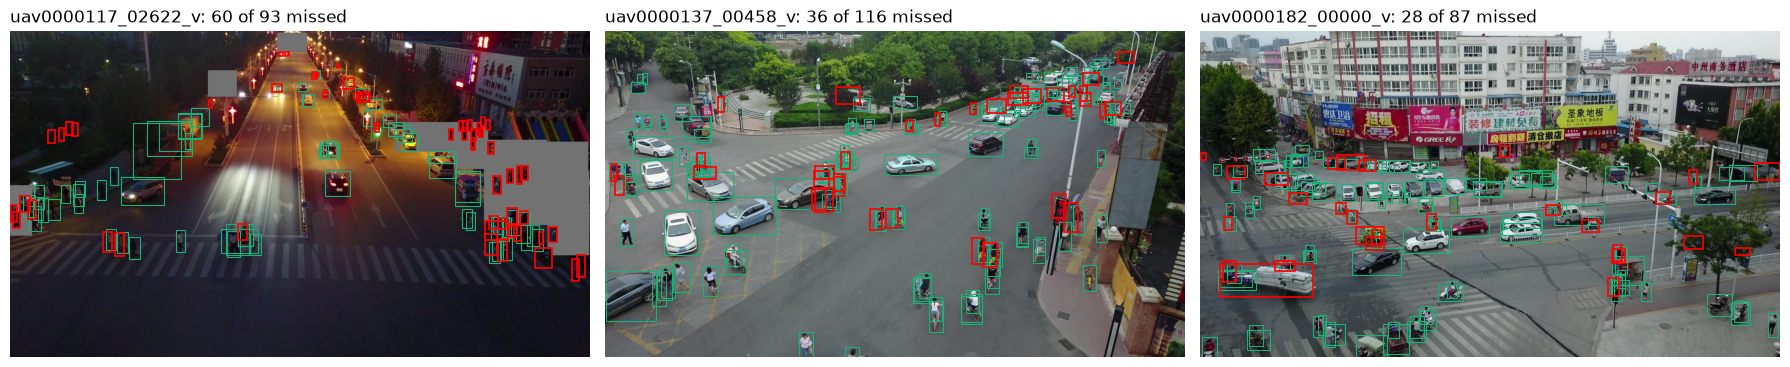

In [48]:
FAIL_RUN = best_run('two-stage')
SCORE = 0.3

rows = np.load(Path(RUNS) / FAIL_RUN / 'val_predictions.npy')
rows = rows[rows[:, 5] > SCORE]
paths = dict(val_frames)
truth = pd.DataFrame([a for a in val_coco['annotations'] if not a['iscrowd'] and a['image_id'] in paths])


def xyxy(boxes):
    boxes = torch.tensor(np.asarray(boxes, dtype=float).reshape(-1, 4))
    return torch.cat([boxes[:, :2], boxes[:, :2] + boxes[:, 2:]], dim=1)


misses = []
for image_id, objects in truth.groupby('image_id'):
    found = rows[rows[:, 0] == image_id, 1:5]
    best = box_iou(xyxy(objects.bbox.tolist()), xyxy(found)).max(1).values if len(found) else torch.zeros(len(objects))
    missed = objects[(best < 0.5).numpy()]
    misses.append({'image_id': image_id, 'clip': str(paths[image_id].parent.name), 'objects': len(objects),
                   'missed': len(missed), 'missed_median_side': np.sqrt(missed.area).median(), 'boxes': missed.bbox.tolist()})
misses = pd.DataFrame(misses)
worst = misses.sort_values('missed', ascending=False).drop_duplicates('clip').head(3)
display(worst.drop(columns='boxes').round(1))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, frame in zip(axes, worst.itertuples()):
    image = np.array(Image.open(paths[frame.image_id]).convert('RGB'))
    ax.imshow(image)
    for x, y, w, h in rows[rows[:, 0] == frame.image_id, 1:5]:
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, color='#1baf7a', lw=0.8))
    for x, y, w, h in frame.boxes:
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, color='red', lw=1.2))
    ax.set_title(f'{frame.clip}: {frame.missed} of {frame.objects} missed', loc='left')
    ax.axis('off')
plt.tight_layout()
plt.show()

## One-stage anchor-based: RetinaNet
`retinanet_resnet50_fpn_v2` from torchvision under the same protocol and training loop.

In [49]:
run_torchvision('retinanet-base', 'one-stage anchor', 'default anchors', build_retinanet)
report(['retinanet-base'])

retinanet-base: mAP 0.149  test-like 0.178  AP50 0.287  AP_small 0.049  10.3 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes
run,,,,,,
retinanet-base,0.149,0.178,0.287,0.049,10.303,3.95


### Experiment 1: small anchors

In [50]:
run_torchvision('retinanet-anchors', 'one-stage anchor', 'small anchors', lambda: build_retinanet(anchors=SMALL_ANCHORS))
report(['retinanet-anchors'], 'retinanet-base')

retinanet-anchors: mAP 0.122  test-like 0.142  AP50 0.275  AP_small 0.055  10.7 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
retinanet-base,0.149,0.178,0.287,0.049,10.303,3.950,0.000,0/7
retinanet-anchors,0.122,0.142,0.275,0.055,10.680,3.757,-0.036,0/7


### Experiment 2: focal loss gamma 1.5
Small anchors, and focal loss gamma 1.5 instead of 2.0, so easy examples are down-weighted less.

In [51]:
run_torchvision('retinanet-focal', 'one-stage anchor', 'small anchors, focal gamma 1.5',
                lambda: build_retinanet(anchors=SMALL_ANCHORS, gamma=1.5))
report(['retinanet-focal'], 'retinanet-base')

retinanet-focal: mAP 0.128  test-like 0.147  AP50 0.284  AP_small 0.056  9.9 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
retinanet-base,0.149,0.178,0.287,0.049,10.303,3.950,0.000,0/7
retinanet-focal,0.128,0.147,0.284,0.056,9.905,3.767,-0.031,2/7


### Experiment 3: lower IoU thresholds for anchor matching
RetinaNet calls an anchor positive at IoU 0.5 and negative below 0.4. A 10 px object can overlap the nearest 16 px anchor by less than 0.5 just because of the anchor grid, so tiny objects get few or no positive anchors (Zhang et al., 2017, *S3FD*; Zhang et al., 2020, *ATSS*). This run lowers the thresholds to 0.4 and 0.3 with the small anchors.

In [52]:
run_torchvision('retinanet-iou', 'one-stage anchor', 'small anchors, positive IoU 0.4, negative 0.3',
                lambda: build_retinanet(anchors=SMALL_ANCHORS, fg_iou=0.4, bg_iou=0.3))
report(['retinanet-iou'], 'retinanet-base')

epoch 1: loss 0.873, 20.6 frames/s


epoch 2: loss 0.588, 20.4 frames/s


epoch 3: loss 0.544, 20.6 frames/s


epoch 4: loss 0.526, 20.7 frames/s


retinanet-iou: mAP 0.127  test-like 0.143  AP50 0.275  AP_small 0.055  16.8 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
retinanet-base,0.149,0.178,0.287,0.049,10.303,3.950,0.000,0/7
retinanet-iou,0.127,0.143,0.275,0.055,16.799,5.253,-0.035,0/7


### Compared with the two-stage detector

,section,settings,mAP,mAP_testlike,AP50,AP_small,AP_medium,AP_large,ms_per_frame
run,,,,,,,,,
retinanet-base,one-stage anchor,default anchors,0.149,0.178,0.287,0.049,0.130,0.298,10.303
retinanet-anchors,one-stage anchor,small anchors,0.122,0.142,0.275,0.055,0.108,0.228,10.680
retinanet-focal,one-stage anchor,"small anchors, focal gamma 1.5",0.128,0.147,0.284,0.056,0.112,0.238,9.905
retinanet-iou,one-stage anchor,"small anchors, positive IoU 0.4, negative 0.3",0.127,0.143,0.275,0.055,0.110,0.233,16.799
frcnn-rpn,two-stage,"small anchors, 2000/3000 proposals, 1024 RoIs",0.193,0.207,0.416,0.084,0.190,0.352,45.343


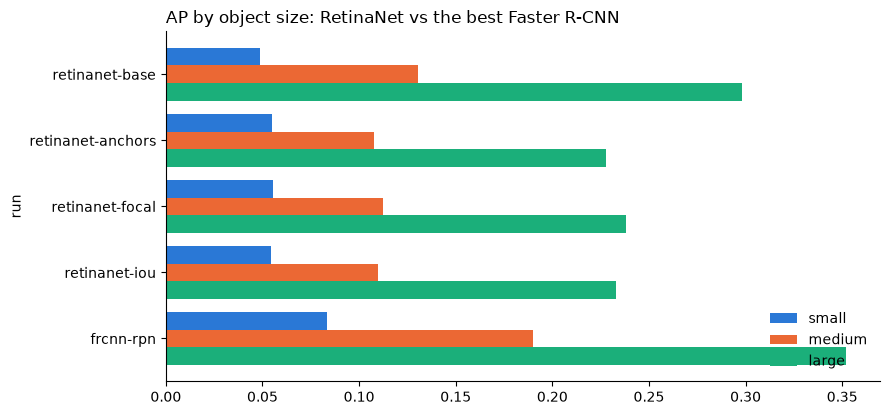

In [53]:
def compare(runs, title):
    log = load_log().set_index('run')
    rows = log.loc[[r for r in runs if r in log.index]]
    if rows.empty:
        print('No finished runs yet')
        return
    display(rows[['section', 'settings', 'mAP', 'mAP_testlike', 'AP50', 'AP_small', 'AP_medium', 'AP_large', 'ms_per_frame']].round(3))
    ax = rows[['AP_small', 'AP_medium', 'AP_large']].plot.barh(figsize=(9, 0.55 * len(rows) + 1.5), width=0.8,
                                                              color=['#2a78d6', '#eb6834', '#1baf7a'])
    ax.set_title(title, loc='left')
    ax.invert_yaxis()
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(['small', 'medium', 'large'], frameon=False, loc='lower right')
    plt.tight_layout()
    plt.show()


compare(['retinanet-base', 'retinanet-anchors', 'retinanet-focal', 'retinanet-iou', best_run('two-stage')],
        'AP by object size: RetinaNet vs the best Faster R-CNN')

## One-stage anchor-free: YOLO
YOLO11n from Ultralytics under the same protocol.

In [54]:
run_ultralytics('yolo11n-base', 'anchor-free', 'default', lambda: YOLO('yolo11n.pt'))
report(['yolo11n-base'])

yolo11n-base: mAP 0.140  test-like 0.144  AP50 0.282  AP_small 0.055  3.5 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes
run,,,,,,
yolo11n-base,0.14,0.144,0.282,0.055,3.463,1.292


### Experiment 1: input size 1280
At 1280 px, 9.8% of boxes are under 16 px, compared with 24.0% at 960.

In [55]:
run_ultralytics('yolo11n-1280', 'anchor-free', 'imgsz 1280', lambda: YOLO('yolo11n.pt'), imgsz=1280, batch=4)
report(['yolo11n-1280'], 'yolo11n-base')

yolo11n-1280: mAP 0.171  test-like 0.173  AP50 0.351  AP_small 0.087  3.5 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
yolo11n-base,0.140,0.144,0.282,0.055,3.463,1.292,0.000,0/7
yolo11n-1280,0.171,0.173,0.351,0.087,3.460,1.994,0.029,5/7


### Experiment 2: box loss gain 10
The box regression loss weight goes from the default 7.5 to 10.

In [56]:
run_ultralytics('yolo11n-box', 'anchor-free', 'box loss gain 10', lambda: YOLO('yolo11n.pt'), box=10.0)
report(['yolo11n-box'], 'yolo11n-base')

yolo11n-box: mAP 0.136  test-like 0.154  AP50 0.277  AP_small 0.058  3.4 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
yolo11n-base,0.140,0.144,0.282,0.055,3.463,1.292,0.00,0/7
yolo11n-box,0.136,0.154,0.277,0.058,3.372,1.243,0.01,2/7


### Experiment 3: YOLO26n
YOLO26 (Ultralytics, 2025) is the next YOLO generation: no NMS at inference (one-to-one head), no DFL, and a label assignment and loss schedule tuned for small objects (STAL, ProgLoss). Same protocol and size class as YOLO11n.

In [57]:
run_ultralytics('yolo26n-base', 'anchor-free', 'YOLO26n, default', lambda: YOLO('yolo26n.pt'))
report(['yolo26n-base'], 'yolo11n-base')

epoch 1/4: val mAP 0.125, 0.6 min
epoch 2/4: val mAP 0.143, 1.0 min
epoch 3/4: val mAP 0.158, 1.5 min
epoch 4/4: val mAP 0.160, 2.0 min


yolo26n-base: mAP 0.151  test-like 0.189  AP50 0.288  AP_small 0.062  3.7 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
yolo11n-base,0.140,0.144,0.282,0.055,3.463,1.292,0.000,0/7
yolo26n-base,0.151,0.189,0.288,0.062,3.726,2.016,0.045,3/7


## One-stage anchor-free: FCOS
FCOS (Tian et al., 2019) predicts a box from every feature-map point inside an object, with a centre-ness score that pushes down boxes from points near the object edge. It shares the ResNet-50 FPN backbone, the input size and the training loop with Faster R-CNN and RetinaNet, so it isolates the effect of dropping anchors.

In [58]:
run_torchvision('fcos-base', 'anchor-free', 'FCOS, default', build_fcos)
report(['fcos-base'])

Downloading: "https://download.pytorch.org/models/fcos_resnet50_fpn_coco-99b0c9b7.pth" to /home/akulba/.cache/torch/hub/checkpoints/fcos_resnet50_fpn_coco-99b0c9b7.pth


100%|██████████| 124M/124M [00:01<00:00, 94.8MB/s] 


epoch 1: loss 1.258, 18.0 frames/s


epoch 2: loss 1.122, 18.1 frames/s


epoch 3: loss 1.079, 18.2 frames/s


epoch 4: loss 1.054, 18.2 frames/s


fcos-base: mAP 0.160  test-like 0.176  AP50 0.327  AP_small 0.058  24.9 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes
run,,,,,,
fcos-base,0.16,0.176,0.327,0.058,24.853,5.982


### Experiment 1: wider centre sampling
Only points within 1.5 strides of the box centre count as positive. A 12 px car at stride 8 then has one or two positive points. A radius of 2.5 gives small objects more positives.

In [59]:
run_torchvision('fcos-center', 'anchor-free', 'FCOS, centre sampling radius 2.5', lambda: build_fcos(center_radius=2.5))
report(['fcos-center'], 'fcos-base')

epoch 1: loss 1.214, 18.1 frames/s


epoch 2: loss 1.062, 18.0 frames/s


epoch 3: loss 1.020, 18.1 frames/s


epoch 4: loss 0.997, 18.1 frames/s


fcos-center: mAP 0.151  test-like 0.164  AP50 0.307  AP_small 0.051  24.8 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
fcos-base,0.160,0.176,0.327,0.058,24.853,5.982,0.000,0/7
fcos-center,0.151,0.164,0.307,0.051,24.774,5.991,-0.011,0/7


### Experiment 2: smaller boxes per level
FCOS sends a box to the level whose range (4x to 8x the level size) holds its largest regression target. Halving the level sizes moves medium objects to the finer, higher-resolution levels, where small and medium objects get more points.

In [60]:
run_torchvision('fcos-levels', 'anchor-free', 'FCOS, level sizes 4-64', lambda: build_fcos(sizes=(4, 8, 16, 32, 64)))
report(['fcos-levels'], 'fcos-base')

epoch 1: loss 1.427, 18.0 frames/s


epoch 2: loss 1.212, 18.0 frames/s


epoch 3: loss 1.165, 18.1 frames/s


epoch 4: loss 1.138, 18.1 frames/s


fcos-levels: mAP 0.148  test-like 0.152  AP50 0.314  AP_small 0.052  25.6 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
fcos-base,0.160,0.176,0.327,0.058,24.853,5.982,0.000,0/7
fcos-levels,0.148,0.152,0.314,0.052,25.607,5.993,-0.024,0/7


### Compared with the anchor-based detectors, by object size

,section,settings,mAP,mAP_testlike,AP50,AP_small,AP_medium,AP_large,ms_per_frame
run,,,,,,,,,
yolo11n-base,anchor-free,default,0.140,0.144,0.282,0.055,0.126,0.296,3.463
yolo11n-1280,anchor-free,imgsz 1280,0.171,0.173,0.351,0.087,0.155,0.321,3.460
yolo11n-box,anchor-free,box loss gain 10,0.136,0.154,0.277,0.058,0.125,0.280,3.372
yolo26n-base,anchor-free,"YOLO26n, default",0.151,0.189,0.288,0.062,0.145,0.277,3.726
fcos-base,anchor-free,"FCOS, default",0.160,0.176,0.327,0.058,0.136,0.322,24.853
fcos-center,anchor-free,"FCOS, centre sampling radius 2.5",0.151,0.164,0.307,0.051,0.127,0.310,24.774
fcos-levels,anchor-free,"FCOS, level sizes 4-64",0.148,0.152,0.314,0.052,0.122,0.302,25.607
frcnn-rpn,two-stage,"small anchors, 2000/3000 proposals, 1024 RoIs",0.193,0.207,0.416,0.084,0.190,0.352,45.343
retinanet-focal,one-stage anchor,"small anchors, focal gamma 1.5",0.128,0.147,0.284,0.056,0.112,0.238,9.905


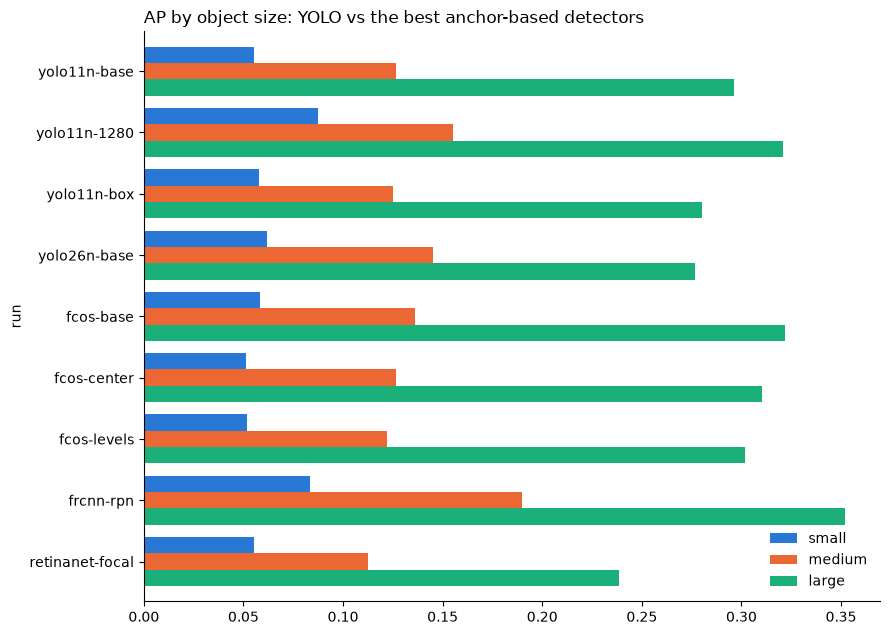

In [61]:
compare(['yolo11n-base', 'yolo11n-1280', 'yolo11n-box', 'yolo26n-base', 'fcos-base', 'fcos-center', 'fcos-levels',
         best_run('two-stage'), best_run('one-stage anchor')],
        'AP by object size: YOLO vs the best anchor-based detectors')

## Query-based: RT-DETR
RT-DETR-L from Ultralytics under the same protocol, with AdamW.

In [62]:
run_ultralytics('rtdetr-base', 'query-based', 'lr0 1e-4', lambda: RTDETR('rtdetr-l.pt'),
                batch=4, lr0=1e-4, optimizer='AdamW')
report(['rtdetr-base'])

rtdetr-base: mAP 0.007  test-like 0.008  AP50 0.024  AP_small 0.001  20.0 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes
run,,,,,,
rtdetr-base,0.007,0.008,0.024,0.001,20.048,7.357


### Experiment 1: learning rate 2e-4

In [63]:
run_ultralytics('rtdetr-lr', 'query-based', 'lr0 2e-4', lambda: RTDETR('rtdetr-l.pt'),
                batch=4, lr0=2e-4, optimizer='AdamW')
report(['rtdetr-lr'], 'rtdetr-base')

rtdetr-lr: mAP 0.039  test-like 0.041  AP50 0.081  AP_small 0.014  20.2 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
rtdetr-base,0.007,0.008,0.024,0.001,20.048,7.357,0.000,0/7
rtdetr-lr,0.039,0.041,0.081,0.014,20.184,7.457,0.033,7/7


### Experiment 2: input size 640

In [64]:
run_ultralytics('rtdetr-640', 'query-based', 'imgsz 640, lr0 1e-4', lambda: RTDETR('rtdetr-l.pt'),
                imgsz=640, batch=8, lr0=1e-4, optimizer='AdamW')
report(['rtdetr-640'], 'rtdetr-base')

rtdetr-640: mAP 0.013  test-like 0.013  AP50 0.042  AP_small 0.007  13.2 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
rtdetr-base,0.007,0.008,0.024,0.001,20.048,7.357,0.000,0/7
rtdetr-640,0.013,0.013,0.042,0.007,13.238,3.884,0.005,5/7


### Experiment 3: longer training (convergence check)
All RT-DETR curves still rise at the last epoch, so 4 epochs do not show what the model can do. The 640 px run is repeated with 16 epochs, 4 times the budget. This checks convergence; it is not part of the equal-budget comparison.

In [65]:
run_ultralytics('rtdetr-640-long', 'query-based', 'imgsz 640, lr0 1e-4, 16 epochs', lambda: RTDETR('rtdetr-l.pt'),
                imgsz=640, epochs=16, batch=8, lr0=1e-4, optimizer='AdamW')
report(['rtdetr-640-long'], 'rtdetr-640')

rtdetr-640-long: mAP 0.065  test-like 0.066  AP50 0.121  AP_small 0.030  12.9 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
rtdetr-640,0.013,0.013,0.042,0.007,13.238,3.884,0.000,0/7
rtdetr-640-long,0.065,0.066,0.121,0.030,12.887,15.465,0.053,7/7


## Query-based: RF-DETR
RF-DETR (Robinson et al., 2025) puts a DINOv2 vision-transformer backbone in front of a light deformable DETR decoder and was searched for real-time speed. It trains with its own loop: AdamW, lr 1e-4 and 1.5e-4 for the backbone, an EMA copy of the weights, batch 4 x 4 gradient steps. The square input is 560 px by default. Same frames and epochs as the other runs; predictions use the EMA weights after the last epoch.

In [66]:
run_rfdetr('rfdetr-base', 'query-based', 'RF-DETR-B, 560 px')
report(['rfdetr-base'])

Val (ema) (Epoch 4/4) — Overall Metrics             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.2425 │ 0.4728 │ 0.2179 │ 0.4365 │ 0.4791 │ 0.5307 │ 0.4731 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘

`Trainer.fit` stopped: `max_epochs=4` reached.


[2026-11-13 09:24:55] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.2528)


  0%|          | 0/712 [00:00<?, ?it/s][2026-11-13 09:24:56] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


rfdetr-base: mAP 0.234  test-like 0.269  AP50 0.453  AP_small 0.091  13.1 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes
run,,,,,,
rfdetr-base,0.234,0.269,0.453,0.091,13.075,5.359


### Experiment 1: learning rate x2
RT-DETR needed a different learning rate in 4 epochs. Same question for RF-DETR: lr 2e-4, backbone 3e-4.

In [67]:
run_rfdetr('rfdetr-lr', 'query-based', 'RF-DETR-B, 560 px, lr 2e-4 / 3e-4', lr=2e-4, lr_encoder=3e-4)
report(['rfdetr-lr'], 'rfdetr-base')

Val (ema) (Epoch 4/4) — Overall Metrics             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.2197 │ 0.4472 │ 0.1878 │ 0.3946 │ 0.4530 │ 0.4984 │ 0.4467 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘

`Trainer.fit` stopped: `max_epochs=4` reached.


[2026-11-13 09:30:51] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.2273)


  0%|          | 0/712 [00:00<?, ?it/s][2026-11-13 09:30:52] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


rfdetr-lr: mAP 0.209  test-like 0.236  AP50 0.426  AP_small 0.090  13.2 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
rfdetr-base,0.234,0.269,0.453,0.091,13.075,5.359,0.000,0/7
rfdetr-lr,0.209,0.236,0.426,0.090,13.182,4.663,-0.033,4/7


### Experiment 2: input 784 px
The input is square, so a 1920x1080 frame becomes 560x315 of real content and the median object goes below 10 px. At 784 px the frame is scaled down 2.4x instead of 3.4x. The size must be a multiple of 56 (patch 14, 4 windows).

In [68]:
run_rfdetr('rfdetr-res', 'query-based', 'RF-DETR-B, 784 px', resolution=784)
report(['rfdetr-res'], 'rfdetr-base')

Val (ema) (Epoch 4/4) — Overall Metrics             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.2716 │ 0.5285 │ 0.2381 │ 0.4859 │ 0.5176 │ 0.5725 │ 0.5031 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘

[2026-11-13 09:39:23] [INFO] rf-detr - Best EMA metric improved to 0.2716 (epoch 3)


`Trainer.fit` stopped: `max_epochs=4` reached.


[2026-11-13 09:39:24] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.2716)


  0%|          | 0/712 [00:00<?, ?it/s][2026-11-13 09:39:25] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


rfdetr-res: mAP 0.257  test-like 0.302  AP50 0.508  AP_small 0.120  27.3 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
rfdetr-base,0.234,0.269,0.453,0.091,13.075,5.359,0.000,0/7
rfdetr-res,0.257,0.302,0.508,0.120,27.334,7.275,0.033,7/7


## Query-based: Hugging Face transformers
Three more DETR-family detectors from `transformers`, trained with the same loop as the torchvision models but with the usual DETR settings: AdamW, weight decay 1e-4, gradient clipping 0.1, a lower learning rate for the backbone. The input is 960x544, the protocol size. Detections are the top 500 (query, class) pairs by sigmoid score. After each epoch the run scores every 4th val frame for the curve below.

- **D-FINE-S** (Peng et al., 2024): RT-DETR with boxes predicted as distributions that are refined layer by layer. lr 2e-4, backbone 1e-4 as in the paper.
- **RT-DETRv2-R18** (Lv et al., 2024): RT-DETR with sampling points per scale in the decoder. lr 1e-4, backbone 1e-5.
- **Deformable DETR** (Zhu et al., 2021): attention looks at a few sampled points on several feature levels, which is what made DETR work on small objects. lr 2e-4, backbone 2e-5.

In [69]:
run_torchvision('dfine-s-base', 'query-based', 'D-FINE-S, 960x544', lambda: build_hf('ustc-community/dfine-small-coco'),
                lr=2e-4, backbone_lr=0.5, batch=8, curve=True)
report(['dfine-s-base'])

Loading weights: 100%|██████████| 764/764 [00:00<00:00, 16683.93it/s]


epoch 1: loss 21.440, 24.9 frames/s, val mAP 0.159 on every 4th val frame


epoch 2: loss 15.678, 25.3 frames/s, val mAP 0.207 on every 4th val frame


epoch 3: loss 15.279, 25.0 frames/s, val mAP 0.210 on every 4th val frame


epoch 4: loss 15.140, 25.0 frames/s, val mAP 0.211 on every 4th val frame


dfine-s-base: mAP 0.207  test-like 0.235  AP50 0.395  AP_small 0.082  8.7 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes
run,,,,,,
dfine-s-base,0.207,0.235,0.395,0.082,8.667,4.32


### Experiment 1: 500 queries
D-FINE keeps 300 queries, so it returns at most 300 objects per frame. The densest train frame has 180 objects, but a DETR model does not use every query for a different object, so the margin is smaller than it looks. Here it keeps 500, the same as `MAX_DET`.

In [70]:
run_torchvision('dfine-s-queries', 'query-based', 'D-FINE-S, 960x544, 500 queries',
                lambda: build_hf('ustc-community/dfine-small-coco', num_queries=500),
                lr=2e-4, backbone_lr=0.5, batch=8, curve=True)
report(['dfine-s-queries'], 'dfine-s-base')

Loading weights: 100%|██████████| 764/764 [00:00<00:00, 16874.04it/s]


epoch 1: loss 18.636, 22.5 frames/s, val mAP 0.166 on every 4th val frame


epoch 2: loss 15.488, 22.4 frames/s, val mAP 0.174 on every 4th val frame


epoch 3: loss 15.131, 22.8 frames/s, val mAP 0.201 on every 4th val frame


epoch 4: loss 14.974, 22.9 frames/s, val mAP 0.198 on every 4th val frame


dfine-s-queries: mAP 0.196  test-like 0.224  AP50 0.380  AP_small 0.086  9.2 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
dfine-s-base,0.207,0.235,0.395,0.082,8.667,4.320,0.000,0/7
dfine-s-queries,0.196,0.224,0.380,0.086,9.199,4.776,-0.011,0/7


In [72]:
run_torchvision('rtdetrv2-r18-base', 'query-based', 'RT-DETRv2-R18, 960x544', lambda: build_hf('PekingU/rtdetr_v2_r18vd'),
                lr=1e-4, backbone_lr=0.1, batch=8, curve=True)
report(['rtdetrv2-r18-base'], 'dfine-s-base')

Loading weights: 100%|██████████| 529/529 [00:00<00:00, 19561.19it/s]


epoch 1: loss 14.038, 21.5 frames/s, val mAP 0.142 on every 4th val frame


epoch 2: loss 9.999, 20.9 frames/s, val mAP 0.183 on every 4th val frame


epoch 3: loss 9.563, 21.1 frames/s, val mAP 0.196 on every 4th val frame


epoch 4: loss 9.421, 21.1 frames/s, val mAP 0.197 on every 4th val frame


rtdetrv2-r18-base: mAP 0.196  test-like 0.212  AP50 0.376  AP_small 0.089  11.5 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
dfine-s-base,0.207,0.235,0.395,0.082,8.667,4.320,0.000,0/7
rtdetrv2-r18-base,0.196,0.212,0.376,0.089,11.463,5.112,-0.024,2/7


In [73]:
run_torchvision('deformable-detr-base', 'query-based', 'Deformable DETR R50, 960x544',
                lambda: build_hf('SenseTime/deformable-detr'), lr=2e-4, backbone_lr=0.1, batch=4, curve=True)
report(['deformable-detr-base'], 'dfine-s-base')

Loading weights: 100%|██████████| 545/545 [00:00<00:00, 15181.61it/s]


epoch 1: loss 2.151, 5.0 frames/s, val mAP 0.054 on every 4th val frame


epoch 2: loss 1.478, 5.0 frames/s, val mAP 0.054 on every 4th val frame


epoch 3: loss 1.340, 5.0 frames/s, val mAP 0.074 on every 4th val frame


epoch 4: loss 1.247, 5.0 frames/s, val mAP 0.086 on every 4th val frame


deformable-detr-base: mAP 0.086  test-like 0.089  AP50 0.185  AP_small 0.029  80.9 ms/frame


,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,
dfine-s-base,0.207,0.235,0.395,0.082,8.667,4.320,0.000,0/7
deformable-detr-base,0.086,0.089,0.185,0.029,80.911,21.795,-0.146,0/7


### Val mAP over training
Every query-based run against YOLO11n on the same frames and epochs. Each library scores its own checkpoints during training: Ultralytics with its own evaluator on all of val, the Hugging Face runs with the shared COCO evaluator on every 4th val frame, RF-DETR with its evaluator on every 8th val frame (EMA weights). The curves show the trend, the table above has the comparable numbers.

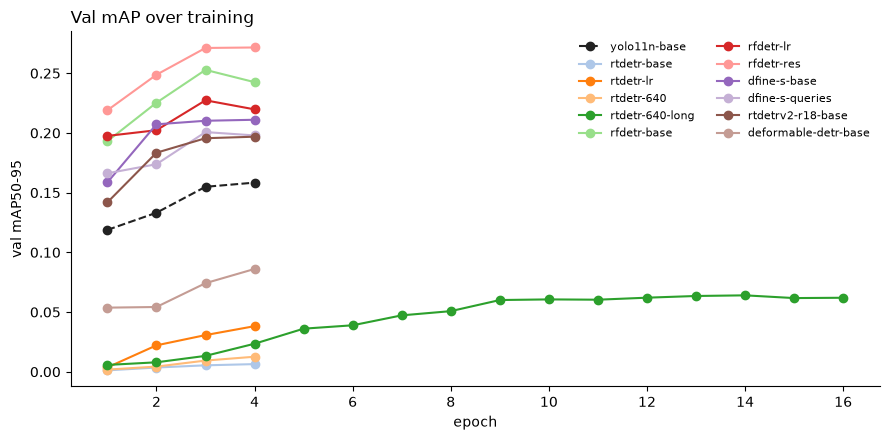

In [74]:
def training_curve(run):
    folder = Path(RUNS) / run
    if (folder / 'results.csv').exists():
        log = pd.read_csv(folder / 'results.csv')
        return log['epoch'], log['metrics/mAP50-95(B)']
    if (folder / 'metrics.csv').exists():
        log = pd.read_csv(folder / 'metrics.csv').dropna(subset=['val/ema_mAP_50_95'])
        log = log.drop_duplicates('epoch', keep='last')
        return log['epoch'] + 1, log['val/ema_mAP_50_95']
    if (folder / 'train_state.json').exists():
        values = json.loads((folder / 'train_state.json').read_text()).get('val_map') or []
        return range(1, len(values) + 1), values
    return [], []


QUERY_RUNS = ['rtdetr-base', 'rtdetr-lr', 'rtdetr-640', 'rtdetr-640-long', 'rfdetr-base', 'rfdetr-lr', 'rfdetr-res',
              'dfine-s-base', 'dfine-s-queries', 'rtdetrv2-r18-base', 'deformable-detr-base']
fig, ax = plt.subplots(figsize=(9, 4.5))
palette = plt.cm.tab20(np.linspace(0, 1, 20))
for k, name in enumerate(['yolo11n-base'] + QUERY_RUNS):
    epochs, values = training_curve(name)
    if len(values):
        ax.plot(epochs, values, marker='o', color='#222222' if k == 0 else palette[k], label=name,
                linestyle='--' if k == 0 else '-')
ax.set_xlabel('epoch')
ax.set_ylabel('val mAP50-95')
ax.set_title('Val mAP over training', loc='left')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### Query-based detectors by object size

,section,settings,mAP,mAP_testlike,AP50,AP_small,AP_medium,AP_large,ms_per_frame
run,,,,,,,,,
rtdetr-base,query-based,lr0 1e-4,0.007,0.008,0.024,0.001,0.004,0.021,20.048
rtdetr-lr,query-based,lr0 2e-4,0.039,0.041,0.081,0.014,0.033,0.093,20.184
rtdetr-640,query-based,"imgsz 640, lr0 1e-4",0.013,0.013,0.042,0.007,0.013,0.028,13.238
rtdetr-640-long,query-based,"imgsz 640, lr0 1e-4, 16 epochs",0.065,0.066,0.121,0.030,0.050,0.142,12.887
rfdetr-base,query-based,"RF-DETR-B, 560 px",0.234,0.269,0.453,0.091,0.222,0.375,13.075
rfdetr-lr,query-based,"RF-DETR-B, 560 px, lr 2e-4 / 3e-4",0.209,0.236,0.426,0.090,0.185,0.374,13.182
rfdetr-res,query-based,"RF-DETR-B, 784 px",0.257,0.302,0.508,0.120,0.243,0.417,27.334
dfine-s-base,query-based,"D-FINE-S, 960x544",0.207,0.235,0.395,0.082,0.192,0.381,8.667
dfine-s-queries,query-based,"D-FINE-S, 960x544, 500 queries",0.196,0.224,0.380,0.086,0.181,0.356,9.199


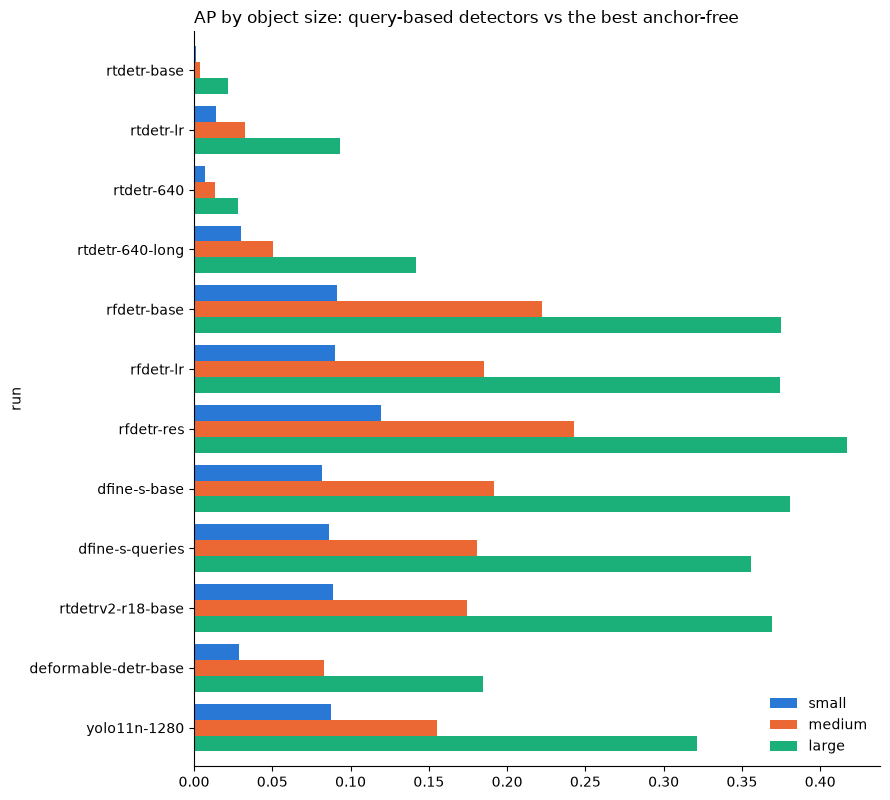

In [75]:
compare(QUERY_RUNS + [best_run('anchor-free')], 'AP by object size: query-based detectors vs the best anchor-free')

## All detectors compared

,run,section,settings,mAP,mAP_testlike,AP50,AP_small,ms_per_frame,train_minutes
49,rfdetr-res,query-based,"RF-DETR-B, 784 px",0.257,0.302,0.508,0.120,27.334,7.275
47,rfdetr-base,query-based,"RF-DETR-B, 560 px",0.234,0.269,0.453,0.091,13.075,5.359
48,rfdetr-lr,query-based,"RF-DETR-B, 560 px, lr 2e-4 / 3e-4",0.209,0.236,0.426,0.090,13.182,4.663
50,dfine-s-base,query-based,"D-FINE-S, 960x544",0.207,0.235,0.395,0.082,8.667,4.320
51,dfine-s-queries,query-based,"D-FINE-S, 960x544, 500 queries",0.196,0.224,0.380,0.086,9.199,4.776
52,rtdetrv2-r18-base,query-based,"RT-DETRv2-R18, 960x544",0.196,0.212,0.376,0.089,11.463,5.112
40,frcnn-base,two-stage,default anchors,0.195,0.223,0.398,0.078,28.858,111.714
41,frcnn-rpn,two-stage,"small anchors, 2000/3000 proposals, 1024 RoIs",0.193,0.207,0.416,0.084,45.343,10.551
0,frcnn-anchors,two-stage,small anchors,0.192,0.203,0.411,0.086,25.607,7.817
1,frcnn-giou,two-stage,"small anchors, GIoU box loss",0.180,0.194,0.400,0.085,16.553,6.643


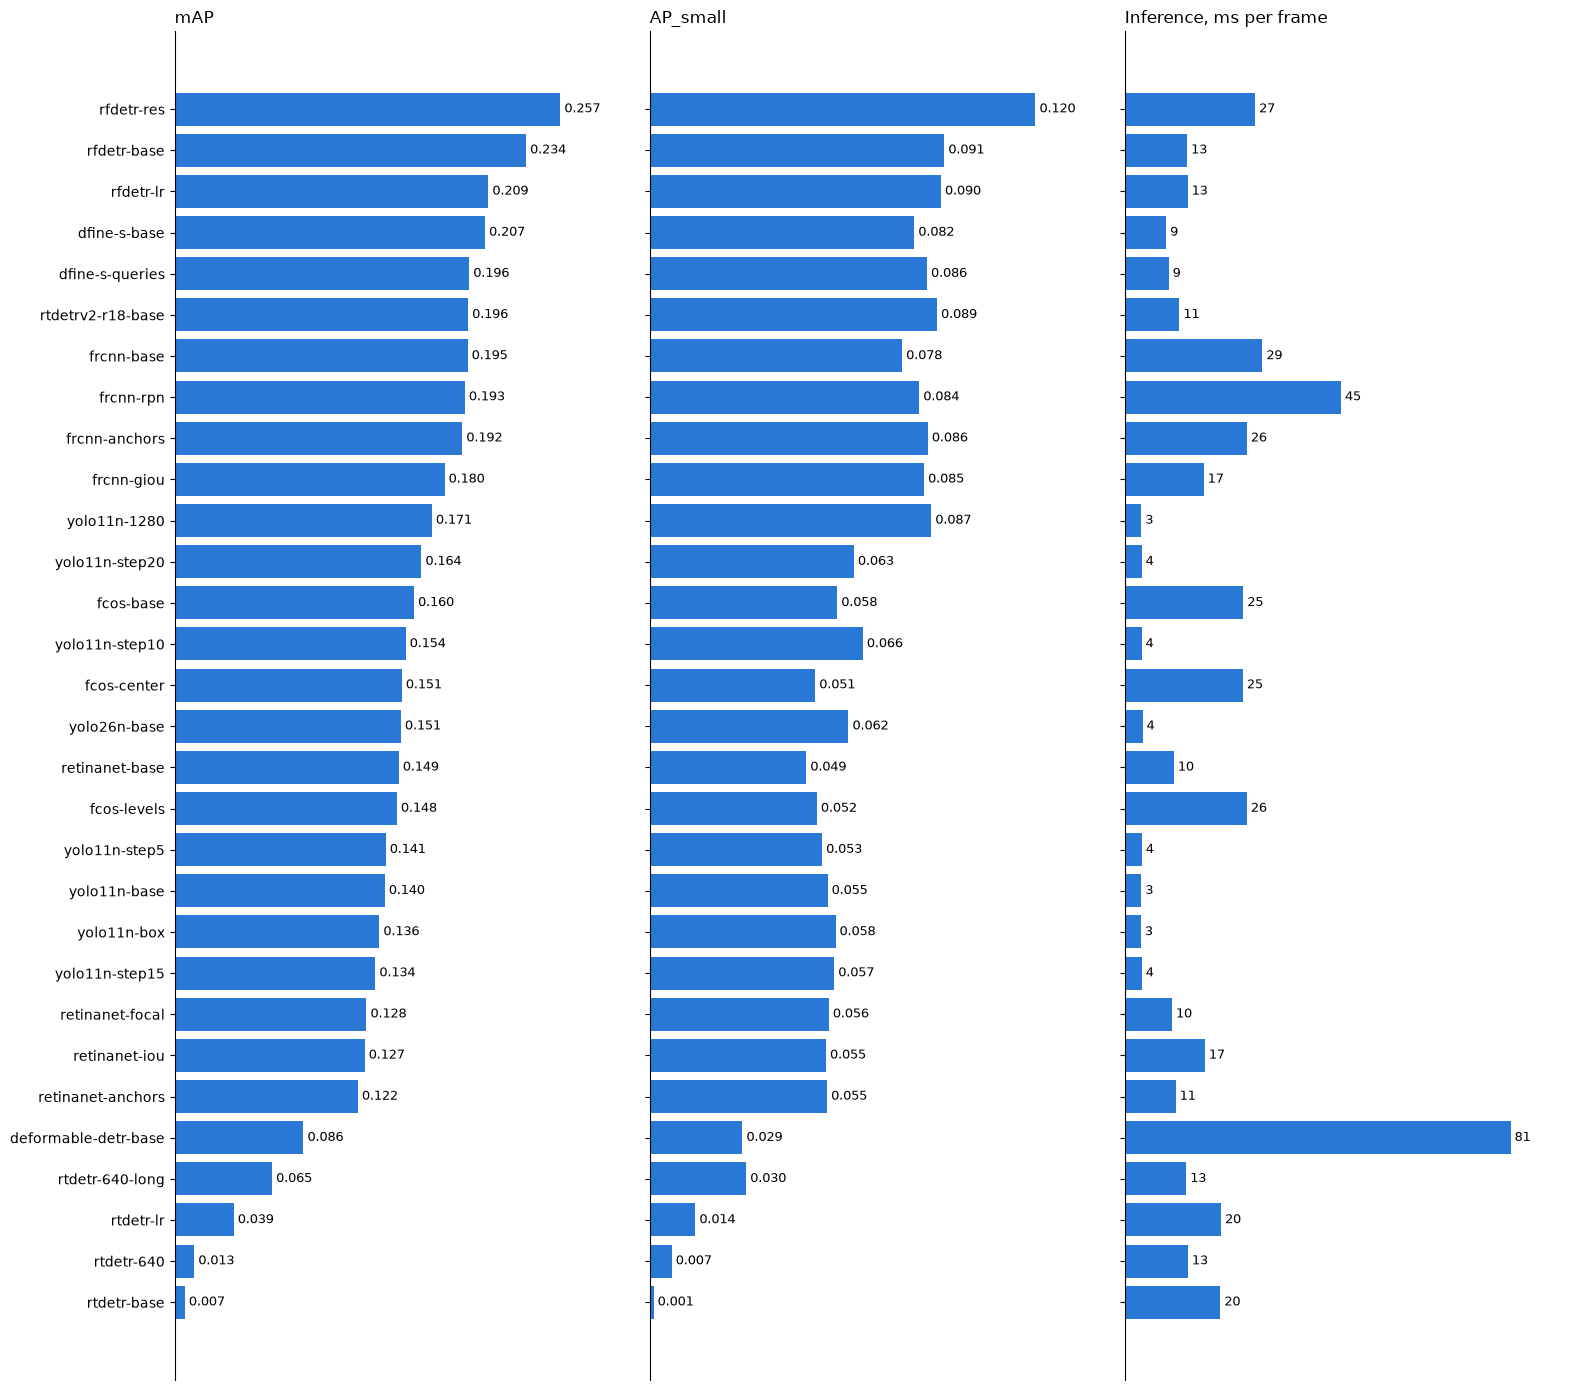

In [76]:
table = load_log()
table = table[table.section != 'pipeline'].sort_values('mAP', ascending=False)
display(table[['run', 'section', 'settings', 'mAP', 'mAP_testlike', 'AP50', 'AP_small', 'ms_per_frame', 'train_minutes']].round(3))

order = table.sort_values('mAP')
fig, axes = plt.subplots(1, 3, figsize=(16, 0.42 * len(order) + 1.4), sharey=True)
for ax, col, title in zip(axes, ['mAP', 'AP_small', 'ms_per_frame'], ['mAP', 'AP_small', 'Inference, ms per frame']):
    ax.barh(order.run, order[col], color='#2a78d6')
    for y, value in enumerate(order[col]):
        ax.text(value, y, f' {value:.3f}' if col != 'ms_per_frame' else f' {value:.0f}', va='center', fontsize=9)
    ax.set_title(title, loc='left')
    ax.set_xticks([])
    ax.margins(x=0.18)
    ax.spines[['top', 'right', 'bottom']].set_visible(False)
plt.tight_layout()
plt.show()

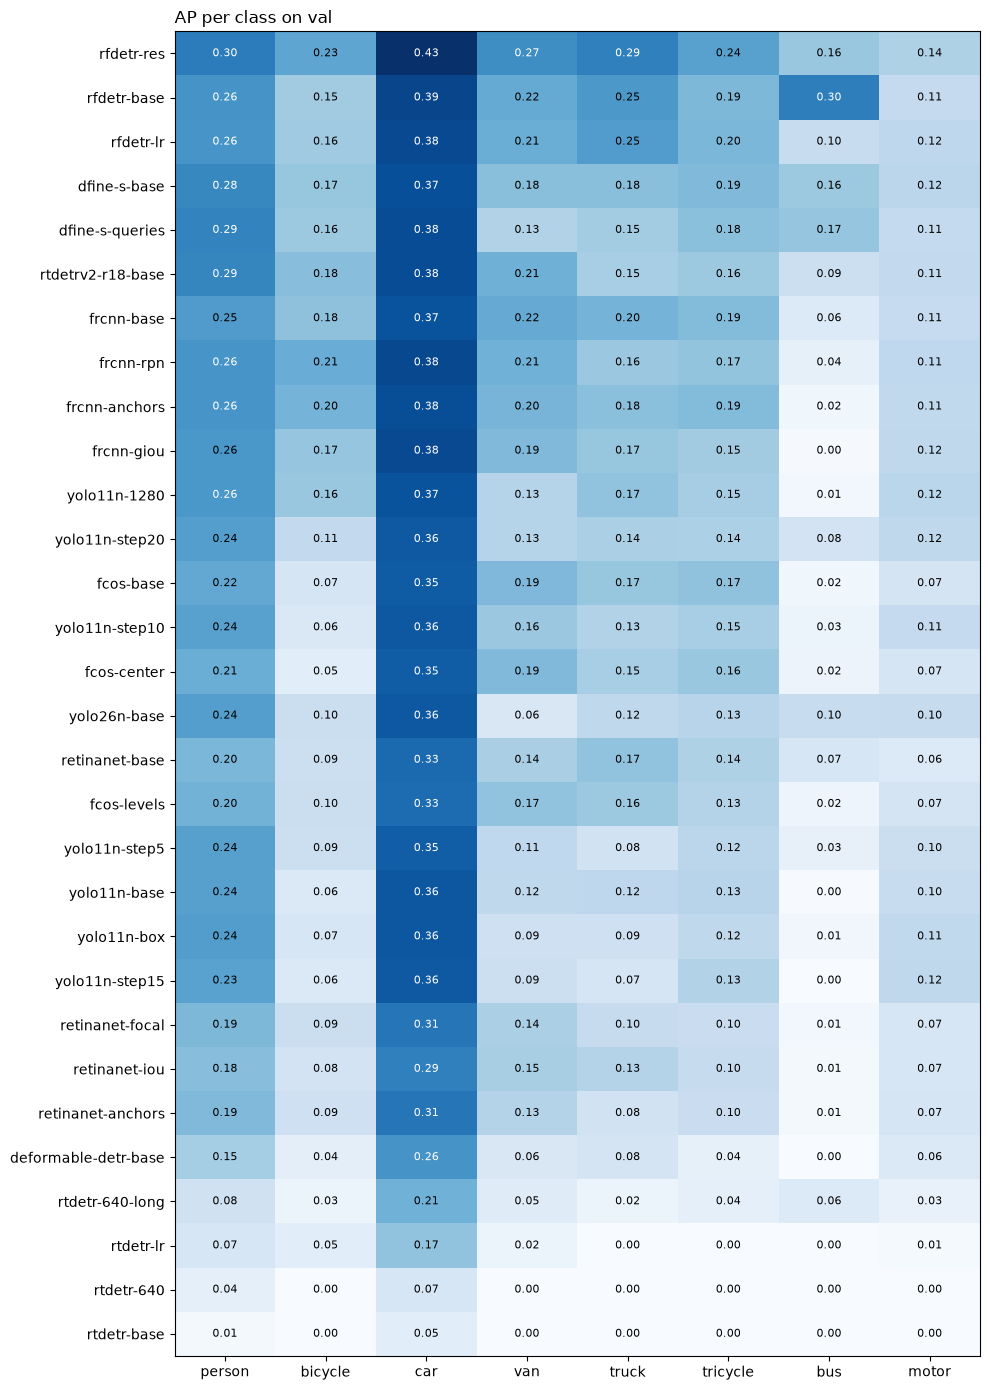

In [77]:
per_class = table.set_index('run')[[f'AP_{c}' for c in CLASSES]]
fig, ax = plt.subplots(figsize=(10, 0.42 * len(per_class) + 1.4))
ax.imshow(per_class.values, cmap='Blues', aspect='auto', vmin=0)
for (y, x), value in np.ndenumerate(per_class.values):
    ax.text(x, y, f'{value:.2f}', ha='center', va='center', fontsize=8,
            color='white' if value > per_class.values.max() * 0.6 else 'black')
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yticks(range(len(per_class)), per_class.index)
ax.set_title('AP per class on val', loc='left')
plt.tight_layout()
plt.show()

## Your Pipeline
Starts from the leaderboard baseline: YOLO11n on all prepared frames (every 5th frame), 20 epochs, `imgsz=960`, public score 0.232. The data experiment changes only the training frames, experiments 1-2 change only inference, experiments 3-4 change only the model and experiment 5 changes only the checkpoint. Experiments 6 and 8 change the model and experiment 7 the training data (augmentation). The inference experiments then change only prediction settings on fixed weights, and the ensemble and temporal steps work on saved predictions, so the effects stay separate.

The final model is the best row of this section by `SELECT_METRIC`. Rows with `best.pt` are optimistic: their epoch was chosen on the same val frames that score them.

### Data experiment: training frame step
YOLO11n on every 5th, 10th, 15th and 20th frame with the same budget of about 9,700 training images, so a smaller step means more different frames, each seen fewer times. Warmup lasts the same number of iterations in every run.

In [78]:
STEP_EPOCHS = {5: 2, 10: 4, 15: 6, 20: 8}
for step, epochs in STEP_EPOCHS.items():
    frames = PREPARED_FRAMES[::step // TRAIN_STRIDE]
    step_yaml = write_frame_list(f'train_step{step}', frames)
    run_ultralytics(f'yolo11n-step{step}', 'frame step', f'every {step}th frame, {len(frames)} frames x {epochs} epochs',
                    lambda: YOLO('yolo11n.pt'), data=step_yaml, epochs=epochs, warmup_epochs=epochs / 8)

yolo11n-step5: mAP 0.141  test-like 0.168  AP50 0.277  AP_small 0.053  3.6 ms/frame
yolo11n-step10: mAP 0.154  test-like 0.172  AP50 0.307  AP_small 0.066  3.5 ms/frame
yolo11n-step15: mAP 0.134  test-like 0.142  AP50 0.271  AP_small 0.057  3.6 ms/frame
yolo11n-step20: mAP 0.164  test-like 0.177  AP50 0.324  AP_small 0.063  3.5 ms/frame


,run,settings,mAP,AP50,AP_small,train_minutes
12,yolo11n-step5,"every 5th frame, 4868 frames x 2 epochs",0.141,0.277,0.053,1.286
13,yolo11n-step10,"every 10th frame, 2434 frames x 4 epochs",0.154,0.307,0.066,1.577
14,yolo11n-step15,"every 15th frame, 1623 frames x 6 epochs",0.134,0.271,0.057,1.862
15,yolo11n-step20,"every 20th frame, 1217 frames x 8 epochs",0.164,0.324,0.063,2.160


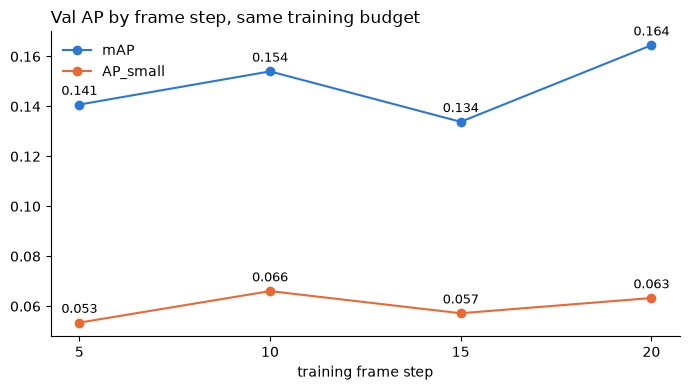

In [79]:
steps = load_log().query("section == 'frame step'").copy()
steps['step'] = steps.run.str.extract(r'step(\d+)', expand=False).astype(int)
steps = steps.sort_values('step')
display(steps[['run', 'settings', 'mAP', 'AP50', 'AP_small', 'train_minutes']].round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for col, color in [('mAP', '#2a78d6'), ('AP_small', '#eb6834')]:
    ax.plot(steps.step, steps[col], marker='o', color=color, label=col)
    for x, y in zip(steps.step, steps[col]):
        ax.annotate(f'{y:.3f}', (x, y), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=9)
ax.set_xticks(steps.step)
ax.set_xlabel('training frame step')
ax.set_title('Val AP by frame step, same training budget', loc='left')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Training recipes
The full-data recipes are kept in one place, so the final model can be retrained on train + val with exactly the same settings.

In [80]:
FULL_DATA = PREP / 'data.yaml'
RECIPES = {
    'baseline-yolo11n-960': dict(make_model=lambda: YOLO('yolo11n.pt'), epochs=20, batch=-1, warmup_epochs=3.0),
    'yolo11n-1280-full': dict(make_model=lambda: YOLO('yolo11n.pt'), imgsz=1280, epochs=20, batch=-1,
                              warmup_epochs=3.0),
    'yolo11s-960-full': dict(make_model=lambda: YOLO('yolo11s.pt'), epochs=20, batch=-1, warmup_epochs=3.0),
    'yolo11s-1280': dict(make_model=lambda: YOLO('yolo11s.pt'), imgsz=1280, epochs=20, batch=-1, warmup_epochs=3.0),
    'yolo11s-1280-aug': dict(make_model=lambda: YOLO('yolo11s.pt'), imgsz=1280, epochs=20, batch=-1,
                             warmup_epochs=3.0, scale=0.9, mixup=0.1, cos_lr=True),
    'yolo11s-1280-blur': dict(make_model=lambda: YOLO('yolo11s.pt'), imgsz=1280, epochs=20, batch=-1,
                              warmup_epochs=3.0, scale=0.9, mixup=0.1, cos_lr=True),
    'yolo11m-1280-blur': dict(make_model=lambda: YOLO('yolo11m.pt'), imgsz=1280, epochs=20, batch=-1,
                              warmup_epochs=3.0, scale=0.9, mixup=0.1, cos_lr=True),
    'yolo11l-1280-blur': dict(make_model=lambda: YOLO('yolo11l.pt'), imgsz=1280, epochs=20, batch=-1,
                              warmup_epochs=3.0, scale=0.9, mixup=0.1, cos_lr=True),
    'yolo26s-1280-blur': dict(make_model=lambda: YOLO('yolo26s.pt'), imgsz=1280, epochs=20, batch=-1,
                              warmup_epochs=3.0, scale=0.9, mixup=0.1, cos_lr=True),
    'yolo11s-1536-blur': dict(make_model=lambda: YOLO('yolo11s.pt'), imgsz=1536, epochs=20, batch=-1,
                              warmup_epochs=3.0, scale=0.9, mixup=0.1, cos_lr=True),
    'yolo11s-1280-blur-dense': dict(make_model=lambda: YOLO('yolo11s.pt'), imgsz=1280, epochs=20, batch=-1,
                                    warmup_epochs=3.0, scale=0.9, mixup=0.1, cos_lr=True),
    'yolo26s-1280-aug': dict(make_model=lambda: YOLO('yolo26s.pt'), imgsz=1280, epochs=20, batch=-1,
                             warmup_epochs=3.0, scale=0.9, mixup=0.1, cos_lr=True),
    'yolov8s-p2-1280': dict(make_model=lambda: YOLO('yolov8s-p2.yaml').load('yolov8s.pt'), imgsz=1280, epochs=20,
                            batch=-1, warmup_epochs=3.0),
}

In [81]:
add_blur_metric()
run_ultralytics('baseline-yolo11n-960', 'pipeline', 'baseline', data=FULL_DATA,
                **RECIPES['baseline-yolo11n-960'])
report(['baseline-yolo11n-960'])

baseline-yolo11n-960: mAP 0.141  test-like 0.168  blurred 0.151  AP50 0.273  AP_small 0.068  3.5 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes
run,,,,,,,,
baseline-yolo11n-960,0.141,0.168,0.151,0.159,0.273,0.068,3.529,12.44


### Experiment 1: inference at 1280
The baseline weights, with frames resized to 1280 instead of 960 at prediction time.

In [82]:
run_ultralytics('pipe-infer-1280', 'pipeline', 'baseline weights, predict at 1280', weights='baseline-yolo11n-960', imgsz=1280)
report(['pipe-infer-1280'], 'baseline-yolo11n-960')

pipe-infer-1280: mAP 0.145  test-like 0.174  blurred 0.156  AP50 0.280  AP_small 0.100  3.7 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
baseline-yolo11n-960,0.141,0.168,0.151,0.159,0.273,0.068,3.529,12.44,0.000,0/7
pipe-infer-1280,0.145,0.174,0.156,0.165,0.280,0.100,3.716,12.44,0.005,5/7


### Experiment 2: test-time augmentation
Ultralytics `augment=True`: the frame is predicted at three scales, one of them flipped, and the boxes are merged before NMS.

In [83]:
run_ultralytics('pipe-tta', 'pipeline', 'baseline weights, test-time augmentation', weights='baseline-yolo11n-960', augment=True)
report(['pipe-tta'], 'baseline-yolo11n-960')

pipe-tta: mAP 0.153  test-like 0.173  blurred 0.158  AP50 0.294  AP_small 0.067  11.0 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
baseline-yolo11n-960,0.141,0.168,0.151,0.159,0.273,0.068,3.529,12.44,0.000,0/7
pipe-tta,0.153,0.173,0.158,0.166,0.294,0.067,11.040,12.44,0.006,5/7


### Experiment 3: training at 1280
The baseline recipe with `imgsz=1280`.

In [84]:
run_ultralytics('yolo11n-1280-full', 'pipeline', 'yolo11n, imgsz 1280, 20 epochs', data=FULL_DATA,
                **RECIPES['yolo11n-1280-full'])
report(['yolo11n-1280-full'], 'baseline-yolo11n-960')

yolo11n-1280-full: mAP 0.164  test-like 0.203  blurred 0.181  AP50 0.315  AP_small 0.091  3.5 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
baseline-yolo11n-960,0.141,0.168,0.151,0.159,0.273,0.068,3.529,12.440,0.000,0/7
yolo11n-1280-full,0.164,0.203,0.181,0.192,0.315,0.091,3.537,20.897,0.033,7/7


### Experiment 4: larger model
The baseline recipe with YOLO11s instead of YOLO11n.

In [85]:
run_ultralytics('yolo11s-960-full', 'pipeline', 'yolo11s, imgsz 960, 20 epochs', data=FULL_DATA,
                **RECIPES['yolo11s-960-full'])
report(['yolo11s-960-full'], 'baseline-yolo11n-960')

yolo11s-960-full: mAP 0.140  test-like 0.153  blurred 0.135  AP50 0.278  AP_small 0.085  4.1 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
baseline-yolo11n-960,0.141,0.168,0.151,0.159,0.273,0.068,3.529,12.440,0.000,0/7
yolo11s-960-full,0.140,0.153,0.135,0.144,0.278,0.085,4.091,20.498,-0.015,5/7


### Experiment 5: checkpoint picked on val
The two full trainings with `best.pt` (highest val mAP during training) instead of the last epoch.

In [86]:
for weights, imgsz in [('yolo11n-1280-full', 1280), ('yolo11s-960-full', 960)]:
    run_ultralytics(f'{weights}-best', 'pipeline', f'{weights}, best.pt', weights=weights, imgsz=imgsz,
                    checkpoint='best')
report(['yolo11n-1280-full', 'yolo11n-1280-full-best', 'yolo11s-960-full', 'yolo11s-960-full-best'], 'baseline-yolo11n-960')

yolo11n-1280-full-best: mAP 0.172  test-like 0.210  blurred 0.184  AP50 0.331  AP_small 0.098  3.8 ms/frame
yolo11s-960-full-best: mAP 0.172  test-like 0.218  blurred 0.197  AP50 0.338  AP_small 0.094  4.1 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
baseline-yolo11n-960,0.141,0.168,0.151,0.159,0.273,0.068,3.529,12.440,0.000,0/7
yolo11n-1280-full,0.164,0.203,0.181,0.192,0.315,0.091,3.537,20.897,0.033,7/7
yolo11n-1280-full-best,0.172,0.210,0.184,0.197,0.331,0.098,3.782,20.897,0.038,7/7
yolo11s-960-full,0.140,0.153,0.135,0.144,0.278,0.085,4.091,20.498,-0.015,5/7
yolo11s-960-full-best,0.172,0.218,0.197,0.208,0.338,0.094,4.082,20.498,0.048,7/7


### Experiment 6: YOLO11s at 1280 (model)
Experiment 3 showed that 1280 px helps YOLO11n, and experiment 4 tried YOLO11s only at 960. This run combines both: YOLO11s with the experiment 3 recipe. It is scored with `last.pt`, so the number is not picked on val.

In [87]:
run_ultralytics('yolo11s-1280', 'pipeline', 'yolo11s, imgsz 1280, 20 epochs', data=FULL_DATA, **RECIPES['yolo11s-1280'])
report(['yolo11s-1280'], 'yolo11s-960-full')

yolo11s-1280: mAP 0.176  test-like 0.196  blurred 0.164  AP50 0.341  AP_small 0.088  5.5 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
yolo11s-960-full,0.140,0.153,0.135,0.144,0.278,0.085,4.091,20.498,0.000,0/7
yolo11s-1280,0.176,0.196,0.164,0.180,0.341,0.088,5.547,35.788,0.036,7/7


### Experiment 7: stronger augmentation (data)
YOLO11s at 960 had its best val mAP at epoch 3 and then went down, so it overfits the 56 train clips. Same model and input size as experiment 6, with scale jitter 0.9 instead of 0.5, mixup 0.1 (Zhang et al., Bag of Freebies) and a cosine learning rate.

In [88]:
run_ultralytics('yolo11s-1280-aug', 'pipeline', 'yolo11s, imgsz 1280, scale 0.9, mixup 0.1, cosine lr',
                data=FULL_DATA, **RECIPES['yolo11s-1280-aug'])
report(['yolo11s-1280-aug'], 'yolo11s-1280')

yolo11s-1280-aug: mAP 0.186  test-like 0.212  blurred 0.179  AP50 0.358  AP_small 0.109  5.6 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
yolo11s-1280,0.176,0.196,0.164,0.180,0.341,0.088,5.547,35.788,0.000,0/7
yolo11s-1280-aug,0.186,0.212,0.179,0.195,0.358,0.109,5.562,36.045,0.015,5/7


### Experiment 8 (optional): extra high-resolution head (model)
The smallest YOLO head has stride 8, so an object under 16 px covers at most a few cells of it, and 9.8% of boxes are still under 16 px at 1280. YOLOv8s with an extra stride-4 head (`yolov8s-p2.yaml`, the rest initialised from `yolov8s.pt`) gives these objects more locations. It is the slowest run, so it only runs with `TRY_P2_HEAD`.

In [89]:
if TRY_P2_HEAD:
    run_ultralytics('yolov8s-p2-1280', 'pipeline', 'yolov8s with a P2 head, imgsz 1280, 20 epochs', data=FULL_DATA,
                    **RECIPES['yolov8s-p2-1280'])
    report(['yolov8s-p2-1280'], 'yolo11s-1280')

### Experiment 9: YOLO26s with the same recipe (model)
The recipe of Experiment 7 with YOLO26s instead of YOLO11s, to see whether the newer head and small-object loss help on the full data.

In [90]:
run_ultralytics('yolo26s-1280-aug', 'pipeline', 'yolo26s, imgsz 1280, scale 0.9, mixup 0.1, cosine lr',
                data=FULL_DATA, **RECIPES['yolo26s-1280-aug'])
report(['yolo26s-1280-aug'], 'yolo11s-1280-aug')

epoch 1/20: val mAP 0.208, 4.1 min
epoch 2/20: val mAP 0.223, 8.2 min
epoch 3/20: val mAP 0.223, 12.3 min
epoch 4/20: val mAP 0.224, 16.4 min
epoch 5/20: val mAP 0.216, 20.5 min
epoch 6/20: val mAP 0.209, 24.5 min
epoch 7/20: val mAP 0.207, 28.6 min
epoch 8/20: val mAP 0.218, 32.7 min
epoch 9/20: val mAP 0.200, 36.8 min
epoch 10/20: val mAP 0.216, 40.9 min
epoch 11/20: val mAP 0.206, 44.5 min
epoch 12/20: val mAP 0.205, 48.2 min
epoch 13/20: val mAP 0.207, 51.8 min
epoch 14/20: val mAP 0.193, 55.5 min
epoch 15/20: val mAP 0.203, 59.1 min
epoch 16/20: val mAP 0.202, 62.7 min
epoch 17/20: val mAP 0.199, 66.3 min
epoch 18/20: val mAP 0.201, 70.0 min
epoch 19/20: val mAP 0.200, 73.6 min
epoch 20/20: val mAP 0.198, 77.2 min


yolo26s-1280-aug: mAP 0.182  test-like 0.210  blurred 0.179  AP50 0.356  AP_small 0.100  6.9 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
yolo11s-1280-aug,0.186,0.212,0.179,0.195,0.358,0.109,5.562,36.045,0.000,0/7
yolo26s-1280-aug,0.182,0.210,0.179,0.195,0.356,0.100,6.900,77.229,-0.001,3/7


### Experiment 10: training at test image quality (data)
The recipe of Experiment 7 on the training mix from the preprocessing section: half of the frames degraded to test sharpness and brightness. Same frames, epochs and augmentation otherwise, so the difference comes from the image quality only. It should lose a little on the sharp val frames and gain on the blurred ones.

In [91]:
run_ultralytics('yolo11s-1280-blur', 'pipeline', 'yolo11s, imgsz 1280, aug recipe, half the frames at test quality',
                data=BLUR_DATA, **RECIPES['yolo11s-1280-blur'])
report(['yolo11s-1280-blur'], 'yolo11s-1280-aug')

epoch 1/20: val mAP 0.212, 3.2 min
epoch 2/20: val mAP 0.210, 6.4 min
epoch 3/20: val mAP 0.200, 9.6 min
epoch 4/20: val mAP 0.216, 12.7 min
epoch 5/20: val mAP 0.203, 15.9 min
epoch 6/20: val mAP 0.207, 19.1 min
epoch 7/20: val mAP 0.217, 22.2 min
epoch 8/20: val mAP 0.214, 25.4 min
epoch 9/20: val mAP 0.209, 28.6 min
epoch 10/20: val mAP 0.199, 31.8 min
epoch 11/20: val mAP 0.199, 34.7 min
epoch 12/20: val mAP 0.215, 37.7 min
epoch 13/20: val mAP 0.208, 40.7 min
epoch 14/20: val mAP 0.205, 43.6 min
epoch 15/20: val mAP 0.216, 46.5 min
epoch 16/20: val mAP 0.204, 49.5 min
epoch 17/20: val mAP 0.201, 52.4 min
epoch 18/20: val mAP 0.201, 55.4 min
epoch 19/20: val mAP 0.203, 58.4 min
epoch 20/20: val mAP 0.201, 61.3 min


yolo11s-1280-blur: mAP 0.185  test-like 0.197  blurred 0.191  AP50 0.355  AP_small 0.087  6.6 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
yolo11s-1280-aug,0.186,0.212,0.179,0.195,0.358,0.109,5.562,36.045,0.000,0/7
yolo11s-1280-blur,0.185,0.197,0.191,0.194,0.355,0.087,6.587,61.290,-0.001,1/7


### Experiment 11: YOLO11m (model)
Experiment 10 with the medium model: 20M parameters instead of 9M. A larger model usually gains most on small and occluded objects, at about twice the training and inference time.

In [92]:
run_ultralytics('yolo11m-1280-blur', 'pipeline', 'yolo11m, imgsz 1280, aug recipe, test-quality mix',
                data=BLUR_DATA, **RECIPES['yolo11m-1280-blur'])
report(['yolo11m-1280-blur'], 'yolo11s-1280-blur')

epoch 1/20: val mAP 0.206, 6.5 min
epoch 2/20: val mAP 0.216, 12.9 min
epoch 3/20: val mAP 0.200, 19.4 min
epoch 4/20: val mAP 0.226, 25.8 min
epoch 5/20: val mAP 0.220, 32.2 min
epoch 6/20: val mAP 0.215, 38.7 min
epoch 7/20: val mAP 0.225, 45.1 min
epoch 8/20: val mAP 0.235, 51.6 min
epoch 9/20: val mAP 0.222, 58.0 min
epoch 10/20: val mAP 0.233, 64.5 min
epoch 11/20: val mAP 0.226, 70.7 min
epoch 12/20: val mAP 0.230, 77.0 min
epoch 13/20: val mAP 0.231, 83.2 min
epoch 14/20: val mAP 0.240, 89.5 min
epoch 15/20: val mAP 0.236, 95.7 min
epoch 16/20: val mAP 0.228, 102.0 min
epoch 17/20: val mAP 0.226, 108.2 min
epoch 18/20: val mAP 0.220, 114.5 min
epoch 19/20: val mAP 0.216, 120.7 min
epoch 20/20: val mAP 0.216, 126.9 min


yolo11m-1280-blur: mAP 0.198  test-like 0.236  blurred 0.227  AP50 0.383  AP_small 0.119  16.3 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
yolo11s-1280-blur,0.185,0.197,0.191,0.194,0.355,0.087,6.587,61.290,0.000,0/7
yolo11m-1280-blur,0.198,0.236,0.227,0.232,0.383,0.119,16.308,126.929,0.038,6/7


### Experiment 11b: YOLO11l, only if YOLO11m helped (model)
If the medium model beats the small one by `SELECT_METRIC`, the large model (25M parameters) is the next step on the same recipe; if not, a larger model is not what limits the score here and this run is skipped to save about two hours.

In [93]:
log = load_log().set_index('run')
medium_helped = ({'yolo11m-12 or 'yolo11l-1280-blur' in log.index or SMOKE_TEST:
    run_ultralytics('yolo11l-1280-blur', 'pipeline', 'yolo11l, imgsz 1280, aug recipe, test-quality mix',
                    data=BLUR_DATA, **RECIPES['yolo11l-1280-blur'])
    report(['yolo11m-1280-blur', 'yolo11l-1280-blur'], 'yolo11s-1280-blur')
else:80-blur', 'yolo11s-1280-blur'} <= set(log.index)
                 and log.loc['yolo11m-1280-blur', SELECT_METRIC] > log.loc['yolo11s-1280-blur', SELECT_METRIC])
if medium_helped
    print('yolo11m did not beat yolo11s, so yolo11l is skipped')

epoch 1/20: val mAP 0.219, 8.2 min
epoch 2/20: val mAP 0.211, 16.3 min
epoch 3/20: val mAP 0.215, 24.4 min
epoch 4/20: val mAP 0.244, 32.4 min
epoch 5/20: val mAP 0.227, 40.5 min
epoch 6/20: val mAP 0.238, 48.6 min
epoch 7/20: val mAP 0.231, 56.7 min
epoch 8/20: val mAP 0.264, 64.8 min
epoch 9/20: val mAP 0.237, 72.9 min
epoch 10/20: val mAP 0.247, 81.0 min
epoch 11/20: val mAP 0.256, 88.9 min
epoch 12/20: val mAP 0.244, 96.9 min
epoch 13/20: val mAP 0.243, 104.8 min
epoch 14/20: val mAP 0.259, 112.7 min
epoch 15/20: val mAP 0.249, 120.6 min
epoch 16/20: val mAP 0.255, 128.4 min
epoch 17/20: val mAP 0.254, 136.3 min
epoch 18/20: val mAP 0.258, 144.2 min
epoch 19/20: val mAP 0.257, 152.2 min
epoch 20/20: val mAP 0.256, 160.0 min


yolo11l-1280-blur: mAP 0.239  test-like 0.246  blurred 0.233  AP50 0.441  AP_small 0.110  22.7 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
yolo11s-1280-blur,0.185,0.197,0.191,0.194,0.355,0.087,6.587,61.290,0.000,0/7
yolo11m-1280-blur,0.198,0.236,0.227,0.232,0.383,0.119,16.308,126.929,0.038,6/7
yolo11l-1280-blur,0.239,0.246,0.233,0.239,0.441,0.110,22.738,160.039,0.045,7/7


### Experiment 12: YOLO26s on the test-quality mix (model)
Experiment 9 compared YOLO26s and YOLO11s on sharp frames; this repeats it on the training mix of Experiment 10.

In [94]:
run_ultralytics('yolo26s-1280-blur', 'pipeline', 'yolo26s, imgsz 1280, aug recipe, test-quality mix',
                data=BLUR_DATA, **RECIPES['yolo26s-1280-blur'])
report(['yolo26s-1280-aug', 'yolo26s-1280-blur'], 'yolo11s-1280-blur')

epoch 1/20: val mAP 0.238, 4.1 min
epoch 2/20: val mAP 0.235, 8.2 min
epoch 3/20: val mAP 0.225, 12.3 min
epoch 4/20: val mAP 0.222, 16.3 min
epoch 5/20: val mAP 0.231, 20.4 min
epoch 6/20: val mAP 0.234, 24.5 min
epoch 7/20: val mAP 0.234, 28.6 min
epoch 8/20: val mAP 0.232, 32.7 min
epoch 9/20: val mAP 0.231, 36.7 min
epoch 10/20: val mAP 0.233, 40.8 min
epoch 11/20: val mAP 0.224, 44.5 min
epoch 12/20: val mAP 0.221, 48.1 min
epoch 13/20: val mAP 0.228, 51.7 min
epoch 14/20: val mAP 0.223, 55.3 min
epoch 15/20: val mAP 0.225, 58.9 min
epoch 16/20: val mAP 0.217, 62.5 min
epoch 17/20: val mAP 0.218, 66.2 min
epoch 18/20: val mAP 0.216, 69.8 min
epoch 19/20: val mAP 0.218, 73.4 min
epoch 20/20: val mAP 0.218, 77.0 min


yolo26s-1280-blur: mAP 0.200  test-like 0.208  blurred 0.207  AP50 0.390  AP_small 0.107  6.9 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
yolo11s-1280-blur,0.185,0.197,0.191,0.194,0.355,0.087,6.587,61.290,0.000,0/7
yolo26s-1280-aug,0.182,0.210,0.179,0.195,0.356,0.100,6.900,77.229,0.001,7/7
yolo26s-1280-blur,0.200,0.208,0.207,0.208,0.390,0.107,6.873,77.012,0.014,7/7


### Experiment 13: training at 1536 px (data)
Prediction at 1920 px was better than at 1280 px with the same weights, so objects at a larger scale help. Here the model also trains at 1536 px; it is scored at 1536 px.

In [95]:
run_ultralytics('yolo11s-1536-blur', 'pipeline', 'yolo11s, imgsz 1536, aug recipe, test-quality mix',
                data=BLUR_DATA, imgsz=1536, **{k: v for k, v in RECIPES['yolo11s-1536-blur'].items() if k != 'imgsz'})
report(['yolo11s-1536-blur'], 'yolo11s-1280-blur')

epoch 1/20: val mAP 0.203, 4.6 min
epoch 2/20: val mAP 0.200, 9.2 min
epoch 3/20: val mAP 0.216, 13.8 min
epoch 4/20: val mAP 0.209, 18.4 min
epoch 5/20: val mAP 0.220, 23.0 min
epoch 6/20: val mAP 0.224, 27.6 min
epoch 7/20: val mAP 0.222, 32.2 min
epoch 8/20: val mAP 0.221, 36.8 min
epoch 9/20: val mAP 0.221, 41.4 min
epoch 10/20: val mAP 0.229, 45.9 min
epoch 11/20: val mAP 0.221, 50.3 min
epoch 12/20: val mAP 0.222, 54.6 min
epoch 13/20: val mAP 0.225, 58.8 min
epoch 14/20: val mAP 0.225, 63.1 min
epoch 15/20: val mAP 0.214, 67.4 min
epoch 16/20: val mAP 0.217, 71.8 min
epoch 17/20: val mAP 0.209, 76.1 min
epoch 18/20: val mAP 0.213, 80.4 min
epoch 19/20: val mAP 0.217, 84.7 min
epoch 20/20: val mAP 0.216, 89.0 min


yolo11s-1536-blur: mAP 0.196  test-like 0.202  blurred 0.193  AP50 0.391  AP_small 0.117  8.4 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
yolo11s-1280-blur,0.185,0.197,0.191,0.194,0.355,0.087,6.587,61.290,0.000,0/7
yolo11s-1536-blur,0.196,0.202,0.193,0.198,0.391,0.117,8.375,88.962,0.004,7/7


### Experiment 14: every 3rd frame instead of every 5th (data)
Experiment 10 with every 3rd training frame (about 8,100 instead of 4,868, prepared the same way and with the same test-quality mix) and the same 20 epochs. The frame-step experiment kept the training budget fixed; here the model gets the extra frames and the extra iterations, as a final model would.

In [96]:
run_ultralytics('yolo11s-1280-blur-dense', 'pipeline', 'yolo11s, imgsz 1280, aug recipe, test-quality mix, every 3rd frame',
                data=BLUR_DENSE_DATA, **RECIPES['yolo11s-1280-blur-dense'])
report(['yolo11s-1280-blur-dense'], 'yolo11s-1280-blur')

epoch 1/20: val mAP 0.191, 5.0 min
epoch 2/20: val mAP 0.208, 10.0 min
epoch 3/20: val mAP 0.211, 15.0 min
epoch 4/20: val mAP 0.208, 20.0 min
epoch 5/20: val mAP 0.205, 25.0 min
epoch 6/20: val mAP 0.205, 30.0 min
epoch 7/20: val mAP 0.203, 34.9 min
epoch 8/20: val mAP 0.212, 39.9 min
epoch 9/20: val mAP 0.205, 44.9 min
epoch 10/20: val mAP 0.197, 49.8 min
epoch 11/20: val mAP 0.207, 54.4 min
epoch 12/20: val mAP 0.202, 59.0 min
epoch 13/20: val mAP 0.204, 63.6 min
epoch 14/20: val mAP 0.194, 68.1 min
epoch 15/20: val mAP 0.197, 72.7 min
epoch 16/20: val mAP 0.196, 77.3 min
epoch 17/20: val mAP 0.196, 81.8 min
epoch 18/20: val mAP 0.191, 86.4 min
epoch 19/20: val mAP 0.194, 91.0 min
epoch 20/20: val mAP 0.193, 95.6 min


yolo11s-1280-blur-dense: mAP 0.175  test-like 0.196  blurred 0.190  AP50 0.343  AP_small 0.103  6.6 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
yolo11s-1280-blur,0.185,0.197,0.191,0.194,0.355,0.087,6.587,61.290,0.000,0/7
yolo11s-1280-blur-dense,0.175,0.196,0.190,0.193,0.343,0.103,6.560,95.586,-0.001,3/7


### Inference experiments (data and inference strategy)
The best trained YOLO stays fixed and only the prediction settings change, one at a time. Each step keeps the best value by `SELECT_METRIC` and passes it on:
- score threshold 0.01 or 0.001: mAP uses the whole ranking, and up to 500 boxes per frame are scored;
- NMS IoU 0.5, 0.6 or 0.7: scenes are dense and 43-65% of boxes are occluded, so neighbours overlap;
- input size 1280, 1536 or 1920: no test frame is wider than 1920 px;
- tiles: the frame is also cut into 2x2 tiles with 20% overlap, each predicted at the same input size, and all boxes are merged with class-wise NMS, as in SAHI (Akyon et al., 2022). Frames whose long side is not above the input size are not tiled;
- test-time augmentation.

In [97]:
def sweep(base, key, values, label):
    candidates = []
    for value in values:
        spec = {**base, key: value}
        spec['run'] = base['run'] if value == base[key] else inference_name(spec)
        if spec['run'] != base['run']:
            run_spec(spec, f"{base['weights']}, {label} {value}")
        candidates.append(spec)
    log = load_log().set_index('run')
    done = [spec for spec in candidates if spec['run'] in log.index]
    return max(done, key=lambda spec: log.loc[spec['run'], SELECT_METRIC]) if done else base


add_blur_metric()
TRAINED = ['yolo11l-1280-blur', 'yolo11m-1280-blur', 'yolo26s-1280-blur', 'yolo11s-1536-blur', 'yolo11s-1280-blur-dense', 'yolo11s-1280-blur', 'yolo26s-1280-aug', 'yolo11s-1280-aug', 'yolo11s-1280', 'yolov8s-p2-1280', 'yolo11n-1280-full']
log = load_log().set_index('run')
INFER_BASE = max([r for r in TRAINED if r in log.index], key=lambda r: log.loc[r, SELECT_METRIC])
print('Weights for the inference experiments:', INFER_BASE)

spec = spec_of(INFER_BASE)
spec = sweep(spec, 'conf', [SCORE_THRESHOLD, 0.001], 'score threshold')
spec = sweep(spec, 'iou', [0.5, 0.6, NMS_IOU], 'NMS IoU')
spec = sweep(spec, 'imgsz', sorted({spec['imgsz'], 1536, 1920, 2240}), 'input size')
spec = sweep(spec, 'tiles', [0, 2], 'tiles')
spec = sweep(spec, 'augment', [False, True], 'test-time augmentation')
print('Selected:', {k: spec[k] for k in ('imgsz', 'conf', 'iou', 'tiles', 'augment')})

report(load_log()[lambda d: d.run.str.startswith(f'{INFER_BASE}-')].run, INFER_BASE)

Weights for the inference experiments: yolo11l-1280-blur


yolo11l-1280-blur-last-1280-conf0.001-nms0.7: mAP 0.243  test-like 0.249  blurred 0.235  AP50 0.450  AP_small 0.112  22.9 ms/frame


yolo11l-1280-blur-last-1280-conf0.001-nms0.5: mAP 0.241  test-like 0.247  blurred 0.234  AP50 0.452  AP_small 0.111  22.6 ms/frame


yolo11l-1280-blur-last-1280-conf0.001-nms0.6: mAP 0.242  test-like 0.248  blurred 0.235  AP50 0.453  AP_small 0.111  22.8 ms/frame


yolo11l-1280-blur-last-1536-conf0.001-nms0.7: mAP 0.247  test-like 0.243  blurred 0.235  AP50 0.458  AP_small 0.110  32.8 ms/frame


yolo11l-1280-blur-last-1920-conf0.001-nms0.7: mAP 0.241  test-like 0.249  blurred 0.237  AP50 0.455  AP_small 0.122  58.8 ms/frame


yolo11l-1280-blur-last-2240-conf0.001-nms0.7: mAP 0.221  test-like 0.234  blurred 0.225  AP50 0.427  AP_small 0.136  87.5 ms/frame


yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tiles: mAP 0.219  test-like 0.249  blurred 0.237  AP50 0.422  AP_small 0.117  459.9 ms/frame


yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta: mAP 0.257  test-like 0.264  blurred 0.254  AP50 0.477  AP_small 0.126  143.5 ms/frame
Selected: {'imgsz': 1920, 'conf': 0.001, 'iou': 0.7, 'tiles': 0, 'augment': True}


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
yolo11l-1280-blur,0.239,0.246,0.233,0.239,0.441,0.110,22.738,160.039,0.000,0/7
yolo11l-1280-blur-last-1280-conf0.001-nms0.7,0.243,0.249,0.235,0.242,0.450,0.112,22.877,NaN,0.003,7/7
yolo11l-1280-blur-last-1280-conf0.001-nms0.5,0.241,0.247,0.234,0.241,0.452,0.111,22.554,NaN,0.001,7/7
yolo11l-1280-blur-last-1280-conf0.001-nms0.6,0.242,0.248,0.235,0.242,0.453,0.111,22.830,NaN,0.002,7/7
yolo11l-1280-blur-last-1536-conf0.001-nms0.7,0.247,0.243,0.235,0.239,0.458,0.110,32.754,NaN,-0.000,6/7
yolo11l-1280-blur-last-1920-conf0.001-nms0.7,0.241,0.249,0.237,0.243,0.455,0.122,58.809,NaN,0.004,6/7
yolo11l-1280-blur-last-2240-conf0.001-nms0.7,0.221,0.234,0.225,0.230,0.427,0.136,87.483,NaN,-0.010,4/7
yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tiles,0.219,0.249,0.237,0.243,0.422,0.117,459.940,NaN,0.004,4/7
yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta,0.257,0.264,0.254,0.259,0.477,0.126,143.452,NaN,0.019,7/7


### Faster R-CNN on all prepared frames (model)
Faster R-CNN was the best required detector (val mAP 0.192) after only 1,623 frames x 4 epochs with a 960 px long side. Here it gets all 4,868 prepared frames, 6 epochs and the torchvision default size (short side 800, long side up to 1333), with the small anchors. The batch is 2 to fit a T4, and the learning rate is halved with it. It is trained as a second, different model for the ensemble below.

In [98]:
run_torchvision('frcnn-full', 'pipeline', 'small anchors, 800-1333 px, all prepared frames, 6 epochs',
                lambda: build_faster_rcnn(anchors=SMALL_ANCHORS, min_size=800, max_size=1333),
                frames=PREPARED_FRAMES, epochs=6, batch=2, lr=LR / 2)
report(['frcnn-full'], 'frcnn-anchors')

frcnn-full: mAP 0.209  test-like 0.225  AP50 0.436  AP_small 0.123  25.9 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,,,
frcnn-anchors,0.192,0.203,NaN,NaN,0.411,0.086,25.607,7.817,0.000,0/7
frcnn-full,0.209,0.225,NaN,NaN,0.436,0.123,25.895,34.596,0.022,4/7


### RF-DETR on all prepared frames (model)
A model from a different family makes the ensemble below more useful: its errors differ more from YOLO's than Faster R-CNN's do. RF-DETR at 784 px on every prepared frame, 12 epochs.

In [99]:
run_rfdetr('rfdetr-full', 'pipeline', 'RF-DETR-B, 784 px, all prepared frames, 12 epochs', resolution=784,
           frames=PREPARED_FRAMES, epochs=12)
report(['rfdetr-full'], 'rfdetr-res')

Val (ema) (Epoch 12/12) — Overall Metrics            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.2688 │ 0.5110 │ 0.2440 │ 0.4525 │ 0.5286 │ 0.6275 │ 0.4840 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘

`Trainer.fit` stopped: `max_epochs=12` reached.


[2026-11-14 04:02:13] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.2750)


  0%|          | 0/322 [00:00<?, ?it/s]          [2026-11-14 04:04:19] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


rfdetr-full: mAP 0.258  test-like 0.288  blurred 0.280  AP50 0.495  AP_small 0.117  28.2 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,,,
rfdetr-res,0.257,0.302,NaN,NaN,0.508,0.120,27.334,7.275,0.000,0/7
rfdetr-full,0.258,0.288,0.28,0.284,0.495,0.117,28.216,63.034,-0.014,2/7


### Experiment 15: Faster R-CNN on the test-quality mix (model)
The `frcnn-full` recipe on the training mix of Experiment 10, so the second model of the ensemble also sees test-quality frames.

In [100]:
run_torchvision('frcnn-blur', 'pipeline', 'small anchors, 800-1333 px, test-quality mix, 6 epochs',
                lambda: build_faster_rcnn(anchors=SMALL_ANCHORS, min_size=800, max_size=1333),
                frames=BLUR_TRAIN_FRAMES, epochs=6, batch=2, lr=LR / 2)
report(['frcnn-blur'], 'frcnn-full')

epoch 1: loss 0.980, 9.3 frames/s


epoch 2: loss 0.754, 9.3 frames/s


epoch 3: loss 0.681, 9.3 frames/s


epoch 4: loss 0.629, 9.4 frames/s


epoch 5: loss 0.592, 9.4 frames/s


epoch 6: loss 0.574, 9.4 frames/s


frcnn-blur: mAP 0.218  test-like 0.232  blurred 0.213  AP50 0.451  AP_small 0.115  47.1 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_testlike,clips better
run,,,,,,,,,,
frcnn-full,0.209,0.225,NaN,NaN,0.436,0.123,25.895,34.596,0.000,0/7
frcnn-blur,0.218,0.232,0.213,0.222,0.451,0.115,47.117,52.058,0.006,6/7


### Ensemble with Weighted Boxes Fusion (model)
YOLO and Faster R-CNN make different mistakes. Weighted Boxes Fusion (Solovyev et al., 2019; the `ensemble-boxes` library) averages boxes that overlap across models instead of keeping only one of them, and lowers the score of a box that only one model found. It runs on saved predictions, so it needs no GPU on val.

In [103]:
def wbf_rows(member_rows, split, weights, iou_thr, conf_type='avg', skip=0.0):
    groups = [by_image(rows) for rows in member_rows]
    parts = []
    for image_id in tqdm(sorted(set().union(*groups)), leave=False):
        width, height = SIZES[split][image_id]
        scale = np.array([width, height, width, height], dtype=float)
        boxes, scores, labels = [], [], []
        for group in groups:
            rows = group.get(image_id, np.zeros((0, 7)))
            xyxy = (np.column_stack([rows[:, 1:3], rows[:, 1:3] + rows[:, 3:5]]) / scale).clip(0, 1)
            valid = (xyxy[:, 2] > xyxy[:, 0]) & (xyxy[:, 3] > xyxy[:, 1])
            boxes.append(xyxy[valid])
            scores.append(rows[valid, 5])
            labels.append(rows[valid, 6])
        fused, fused_scores, fused_labels = weighted_boxes_fusion(boxes, scores, labels, weights=weights, iou_thr=iou_thr,
                                                                  skip_box_thr=skip, conf_type=conf_type)
        keep = np.argsort(-fused_scores)[:MAX_DET]
        parts.append(to_rows(image_id, fused[keep] * scale, fused_scores[keep], fused_labels[keep] - 1))
    return np.concatenate(parts) if parts else np.zeros((0, 7))


def run_wbf(members, weights, iou_thr, conf_type='avg', skip=0.0):
    name = f"wbf-{'+'.join(members)}-w{''.join(map(str, weights))}-iou{iou_thr}"
    name += ('' if conf_type == 'avg' else f'-{conf_type}') + (f'-skip{skip:g}' if skip else '')
    run_spec(dict(kind='ensemble', run=name, members=[spec_of(m) for m in members], weights=weights, iou_thr=iou_thr,
                  conf_type=conf_type, skip=skip),
             f"WBF of {', '.join(members)}, weights {weights}, IoU {iou_thr}, {conf_type}, skip {skip:g}")
    return name


def ranked(condition=lambda spec: True):
    log = load_log().query("section == 'pipeline'").dropna(subset=[SELECT_METRIC])
    return [r for r in log.sort_values(SELECT_METRIC, ascending=False).run if condition(spec_of(r))]


temporal_rows = np.zeros((0, 7), dtype=float)
yolos = ranked(lambda spec: spec['kind'] == 'ultralytics')
YOLO_BEST = yolos[0] if yolos else None
PARTNERS = [r for r in ('frcnn-full', 'frcnn-blur', 'rfdetr-full') if r in set(load_log().run)]
print('Best single YOLO:', YOLO_BEST, '| other families:', PARTNERS)

Best single YOLO: yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta | other families: ['frcnn-full', 'frcnn-blur', 'rfdetr-full']


### Experiment 16: test-time flip for Faster R-CNN (inference)
The best Faster R-CNN of the pipeline also predicts every frame flipped horizontally, the boxes are flipped back, and the two views are fused with WBF. Flips are part of training, so the flipped view is as good as the original but makes different mistakes. Fused, it is one more ensemble member that needs no training.

In [104]:
frcnns = ranked(lambda spec: spec['kind'] == 'torchvision' and not spec.get('flip'))
FRCNN_BEST = frcnns[0] if frcnns else None
if FRCNN_BEST:
    flipped = f'{FRCNN_BEST}-flip'
    run_spec(dict(kind='torchvision', run=flipped, weights=spec_of(FRCNN_BEST)['weights'], flip=True),
             f'{FRCNN_BEST}, frames flipped horizontally')
    if flipped in set(load_log().run):
        FRCNN_TTA = run_wbf([FRCNN_BEST, flipped], [1, 1], 0.55)
        if FRCNN_TTA in set(load_log().run):
            PARTNERS.append(FRCNN_TTA)
        report([flipped, FRCNN_TTA], FRCNN_BEST)

frcnn-blur-flip: mAP 0.212  test-like 0.224  blurred 0.209  AP50 0.445  AP_small 0.118  47.2 ms/frame


wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55: mAP 0.229  test-like 0.240  blurred 0.223  AP50 0.470  AP_small 0.130  94.3 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
frcnn-blur,0.218,0.232,0.213,0.222,0.451,0.115,47.117,52.058,0.000,0/7
frcnn-blur-flip,0.212,0.224,0.209,0.216,0.445,0.118,47.210,NaN,-0.006,1/7
wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55,0.229,0.240,0.223,0.232,0.470,0.130,94.327,NaN,0.009,7/7


#### Ensemble experiment 1: best YOLO + one model of another family
The best single YOLO with each of the other-family models, at equal weights and with YOLO counted twice, and at two IoU thresholds.

In [105]:
pairs = []
for partner in PARTNERS if YOLO_BEST else []:
    for weights, iou_thr in [([1, 1], 0.55), ([2, 1], 0.55), ([2, 1], 0.65)]:
        pairs.append(run_wbf([YOLO_BEST, partner], weights, iou_thr))
report(pairs, YOLO_BEST)

wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-full-w11-iou0.55: mAP 0.267  test-like 0.282  blurred 0.259  AP50 0.508  AP_small 0.145  169.3 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-full-w21-iou0.55: mAP 0.273  test-like 0.284  blurred 0.267  AP50 0.517  AP_small 0.144  169.3 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-full-w21-iou0.65: mAP 0.278  test-like 0.288  blurred 0.271  AP50 0.524  AP_small 0.149  169.3 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-blur-w11-iou0.55: mAP 0.272  test-like 0.283  blurred 0.263  AP50 0.516  AP_small 0.135  190.6 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-blur-w21-iou0.55: mAP 0.277  test-like 0.287  blurred 0.272  AP50 0.524  AP_small 0.137  190.6 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-blur-w21-iou0.65: mAP 0.282  test-like 0.290  blurred 0.275  AP50 0.531  AP_small 0.141  190.6 ms/frame


... (3 outputs left out)

wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w11-iou0.55: mAP 0.278  test-like 0.288  blurred 0.269  AP50 0.527  AP_small 0.145  237.8 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w21-iou0.55: mAP 0.280  test-like 0.289  blurred 0.276  AP50 0.530  AP_small 0.142  237.8 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w21-iou0.65: mAP 0.285  test-like 0.291  blurred 0.278  AP50 0.536  AP_small 0.146  237.8 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta,0.257,0.264,0.254,0.259,0.477,0.126,143.452,NaN,0.000,0/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-full-w11-iou0.55,0.267,0.282,0.259,0.271,0.508,0.145,169.348,NaN,0.012,3/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-full-w21-iou0.55,0.273,0.284,0.267,0.276,0.517,0.144,169.348,NaN,0.017,6/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-full-w21-iou0.65,0.278,0.288,0.271,0.279,0.524,0.149,169.348,NaN,0.021,7/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-blur-w11-iou0.55,0.272,0.283,0.263,0.273,0.516,0.135,190.569,NaN,0.015,5/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-blur-w21-iou0.55,0.277,0.287,0.272,0.280,0.524,0.137,190.569,NaN,0.021,6/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+frcnn-blur-w21-iou0.65,0.282,0.290,0.275,0.282,0.531,0.141,190.569,NaN,0.024,7/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full-w11-iou0.55,0.288,0.308,0.298,0.303,0.531,0.138,171.668,NaN,0.045,5/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full-w21-iou0.55,0.286,0.302,0.293,0.298,0.531,0.136,171.668,NaN,0.039,5/7


#### Ensemble experiment 2: more members
The best pair plus the other families, then plus a second YOLO with different weights (YOLO26 if there is one, because its errors differ most from YOLO11).

In [106]:
log = load_log().set_index('run')
done_pairs = [p for p in pairs if p in log.index]
BEST_PAIR = max(done_pairs, key=lambda r: log.loc[r, SELECT_METRIC]) if done_pairs else None
groups = []
if BEST_PAIR:
    pair_spec = spec_of(BEST_PAIR)
    first, partner = [m['run'] for m in pair_spec['members']]
    others = [p for p in PARTNERS if p != partner]
    second = next(iter(ranked(lambda s: s['kind'] == 'ultralytics' and s['weights'].startswith('yolo26')
                              and s['weights'] != spec_of(first)['weights'])), None)
    second = second or next((r for r in yolos if spec_of(r)['weights'] != spec_of(first)['weights']), None)
    w = pair_spec['weights']
    for extra in [[o] for o in others] + ([others] if len(others) > 1 else []):
        groups.append(run_wbf([first, partner] + extra, w + [1] * len(extra), pair_spec['iou_thr']))
    if f'{partner}-flip' in set(load_log().run):
        groups.append(run_wbf([first, partner, f'{partner}-flip'], w + [w[1]], pair_spec['iou_thr']))
    if second:
        groups.append(run_wbf([first, partner, second], w + [1], pair_spec['iou_thr']))
        groups.append(run_wbf([first, partner, second] + others, w + [1] * (1 + len(others)), pair_spec['iou_thr']))
report(groups, BEST_PAIR)

wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+frcnn-full-w111-iou0.55: mAP 0.295  test-like 0.316  blurred 0.296  AP50 0.550  AP_small 0.156  197.6 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+frcnn-blur-w111-iou0.55: mAP 0.297  test-like 0.316  blurred 0.297  AP50 0.555  AP_small 0.148  218.8 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55: mAP 0.299  test-like 0.317  blurred 0.300  AP50 0.559  AP_small 0.153  266.0 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+frcnn-full+frcnn-blur+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w11111-iou0.55: mAP 0.285  test-like 0.305  blurred 0.283  AP50 0.543  AP_small 0.152  339.0 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+yolo26s-1280-blur-w111-iou0.55: mAP 0.292  test-like 0.312  blurred 0.301  AP50 0.542  AP_small 0.149  178.5 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+yolo26s-1280-blur+frcnn-full+frcnn-blur+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111111-iou0.55: mAP 0.288  test-like 0.309  blurred 0.288  AP50 0.548  AP_small 0.158  345.9 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full-w11-iou0.55,0.288,0.308,0.298,0.303,0.531,0.138,171.668,NaN,0.000,0/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+frcnn-full-w111-iou0.55,0.295,0.316,0.296,0.306,0.550,0.156,197.564,NaN,0.003,5/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+frcnn-blur-w111-iou0.55,0.297,0.316,0.297,0.307,0.555,0.148,218.785,NaN,0.003,5/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55,0.299,0.317,0.300,0.308,0.559,0.153,265.995,NaN,0.005,6/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+frcnn-full+frcnn-blur+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w11111-iou0.55,0.285,0.305,0.283,0.294,0.543,0.152,339.007,NaN,-0.010,4/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+yolo26s-1280-blur-w111-iou0.55,0.292,0.312,0.301,0.307,0.542,0.149,178.541,NaN,0.003,6/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+yolo26s-1280-blur+frcnn-full+frcnn-blur+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111111-iou0.55,0.288,0.309,0.288,0.298,0.548,0.158,345.880,NaN,-0.005,5/7


#### Ensemble experiment 3: fusion settings
On the best ensemble so far: how the fused score is computed (`avg` lowers boxes that only some models found; `box_and_model_avg` and `max` keep them higher), and dropping boxes under 0.01 or 0.03 before fusion, which keeps low-score noise of one model from pulling boxes of the others.

In [107]:
ensembles = ranked(lambda s: s['kind'] == 'ensemble')
BEST_ENSEMBLE = ensembles[0] if ensembles else None
settings = []
if BEST_ENSEMBLE:
    spec = spec_of(BEST_ENSEMBLE)
    members = [m['run'] for m in spec['members']]
    for conf_type, skip in [('box_and_model_avg', 0.0), ('max', 0.0), (spec.get('conf_type', 'avg'), 0.01),
                            (spec.get('conf_type', 'avg'), 0.03)]:
        settings.append(run_wbf(members, spec['weights'], spec['iou_thr'], conf_type, skip))
report(settings, BEST_ENSEMBLE)

wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg: mAP 0.300  test-like 0.318  blurred 0.300  AP50 0.560  AP_small 0.154  266.0 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-max: mAP 0.290  test-like 0.306  blurred 0.286  AP50 0.551  AP_small 0.149  266.0 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-skip0.01: mAP 0.301  test-like 0.317  blurred 0.300  AP50 0.562  AP_small 0.155  266.0 ms/frame


wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-skip0.03: mAP 0.301  test-like 0.316  blurred 0.299  AP50 0.563  AP_small 0.154  266.0 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55,0.299,0.317,0.300,0.308,0.559,0.153,265.995,NaN,0.000,0/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg,0.300,0.318,0.300,0.309,0.560,0.154,265.995,NaN,0.001,5/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-max,0.290,0.306,0.286,0.296,0.551,0.149,265.995,NaN,-0.012,1/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-skip0.01,0.301,0.317,0.300,0.308,0.562,0.155,265.995,NaN,0.000,4/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-skip0.03,0.301,0.316,0.299,0.307,0.563,0.154,265.995,NaN,-0.001,3/7


### Bonus: temporal rescoring
Val and test frames are consecutive. A real object is usually found again at almost the same place in the next frame, while many false positives are not. Each box is matched to the box of the same class with the highest IoU in each of the `k` previous and next frames (IoU at least 0.3; a neighbour without a match counts as score 0), and its score becomes `(1 - w) * score + w * mean neighbour score`. Boxes do not move, only the ranking changes. This is a simplified Seq-NMS (Han et al., 2016) without the linking step. The grid is small (k = 1 or 2, w = 0.3 or 0.6) because it is tuned on the same val clips that score it; `paired` below shows on how many clips it helps.

In [108]:
def boxes_xyxy(rows):
    return torch.tensor(np.column_stack([rows[:, 1:3], rows[:, 1:3] + rows[:, 3:5]]))


def temporal_rows(rows, split, window, weight, iou_thr):
    groups = by_image(rows)
    frames = pd.DataFrame([(i, *ORDER[split][i]) for i in groups], columns=['image_id', 'clip', 'frame'])
    parts = []
    for _, clip in frames.groupby('clip'):
        lookup = dict(zip(clip.frame, clip.image_id))
        for image_id, frame in zip(clip.image_id, clip.frame):
            current = groups[image_id]
            boxes, labels = boxes_xyxy(current), torch.tensor(current[:, 6])
            total, count = torch.zeros(len(current), dtype=torch.float64), 0
            for offset in [k for k in range(-window, window + 1) if k]:
                other = groups.get(lookup.get(frame + offset))
                if other is None:
                    continue
                iou = box_iou(boxes, boxes_xyxy(other))
                iou[labels[:, None] != torch.tensor(other[:, 6])[None]] = 0
                best = iou.max(1)
                total += torch.where(best.values >= iou_thr, torch.tensor(other[:, 5])[best.indices], 0.0)
                count += 1
            rescored = current.copy()
            if count:
                rescored[:, 5] = (1 - weight) * current[:, 5] + weight * total.numpy() / count
            parts.append(rescored)
    return np.concatenate(parts)


add_blur_metric()
log = load_log().query("section == 'pipeline'").dropna(subset=[SELECT_METRIC])
bases = [r for r in log.sort_values(SELECT_METRIC, ascending=False).run
         if spec_of(r)['kind'] in ('ultralytics', 'ensemble')]
base = bases[0]
names = []
for window, weight in [(1, 0.3), (1, 0.6), (2, 0.3), (2, 0.6)]:
    names.append(f'{base}+temporal-k{window}-w{weight}')
    run_spec(dict(kind='temporal', run=names[-1], base=spec_of(base), window=window, weight=weight, iou_thr=0.3),
             f'temporal rescoring of {base}, k={window}, w={weight}')
report(names, base)

wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k1-w0.3: mAP 0.303  test-like 0.320  blurred 0.302  AP50 0.562  AP_small 0.157  266.0 ms/frame
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k1-w0.6: mAP 0.299  test-like 0.317  blurred 0.299  AP50 0.551  AP_small 0.152  266.0 ms/frame
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k2-w0.3: mAP 0.303  test-like 0.320  blurred 0.303  AP50 0.563  AP_small 0.157  266.0 ms/frame
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k2-w0.6: mAP 0.300  test-like 0.317  blurred 0.300  AP50 0.553  AP_small 0.152  266.0 ms/frame


,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame,train_minutes,change in mAP_shift,clips better
run,,,,,,,,,,
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg,0.300,0.318,0.300,0.309,0.560,0.154,265.995,NaN,0.000,0/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k1-w0.3,0.303,0.320,0.302,0.311,0.562,0.157,265.995,NaN,0.002,5/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k1-w0.6,0.299,0.317,0.299,0.308,0.551,0.152,265.995,NaN,-0.001,1/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k2-w0.3,0.303,0.320,0.303,0.312,0.563,0.157,265.995,NaN,0.003,5/7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k2-w0.6,0.300,0.317,0.300,0.309,0.553,0.152,265.995,NaN,-0.000,2/7


### All steps compared
Val mAP on all clips and on the test-like clips, then every run against the baseline clip by clip: the mean gain over the 7 clips and on how many of them the run is better.

,run,settings,mAP,mAP_testlike,mAP_blur,mAP_shift,AP50,AP_small,ms_per_frame
20,yolo11s-960-full,"yolo11s, imgsz 960, 20 epochs",0.140,0.153,0.135,0.144,0.278,0.085,4.091
16,baseline-yolo11n-960,baseline,0.141,0.168,0.151,0.159,0.273,0.068,3.529
17,pipe-infer-1280,"baseline weights, predict at 1280",0.145,0.174,0.156,0.165,0.280,0.100,3.716
18,pipe-tta,"baseline weights, test-time augmentation",0.153,0.173,0.158,0.166,0.294,0.067,11.040
23,yolo11s-1280,"yolo11s, imgsz 1280, 20 epochs",0.176,0.196,0.164,0.180,0.341,0.088,5.547
...,...,...,...,...,...,...,...,...,...
93,wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0...,WBF of yolo11l-1280-blur-last-1920-conf0.001-n...,0.301,0.317,0.300,0.308,0.562,0.155,265.995
98,wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0...,temporal rescoring of wbf-yolo11l-1280-blur-la...,0.300,0.317,0.300,0.309,0.553,0.152,265.995
91,wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0...,WBF of yolo11l-1280-blur-last-1920-conf0.001-n...,0.300,0.318,0.300,0.309,0.560,0.154,265.995
95,wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0...,temporal rescoring of wbf-yolo11l-1280-blur-la...,0.303,0.320,0.302,0.311,0.562,0.157,265.995


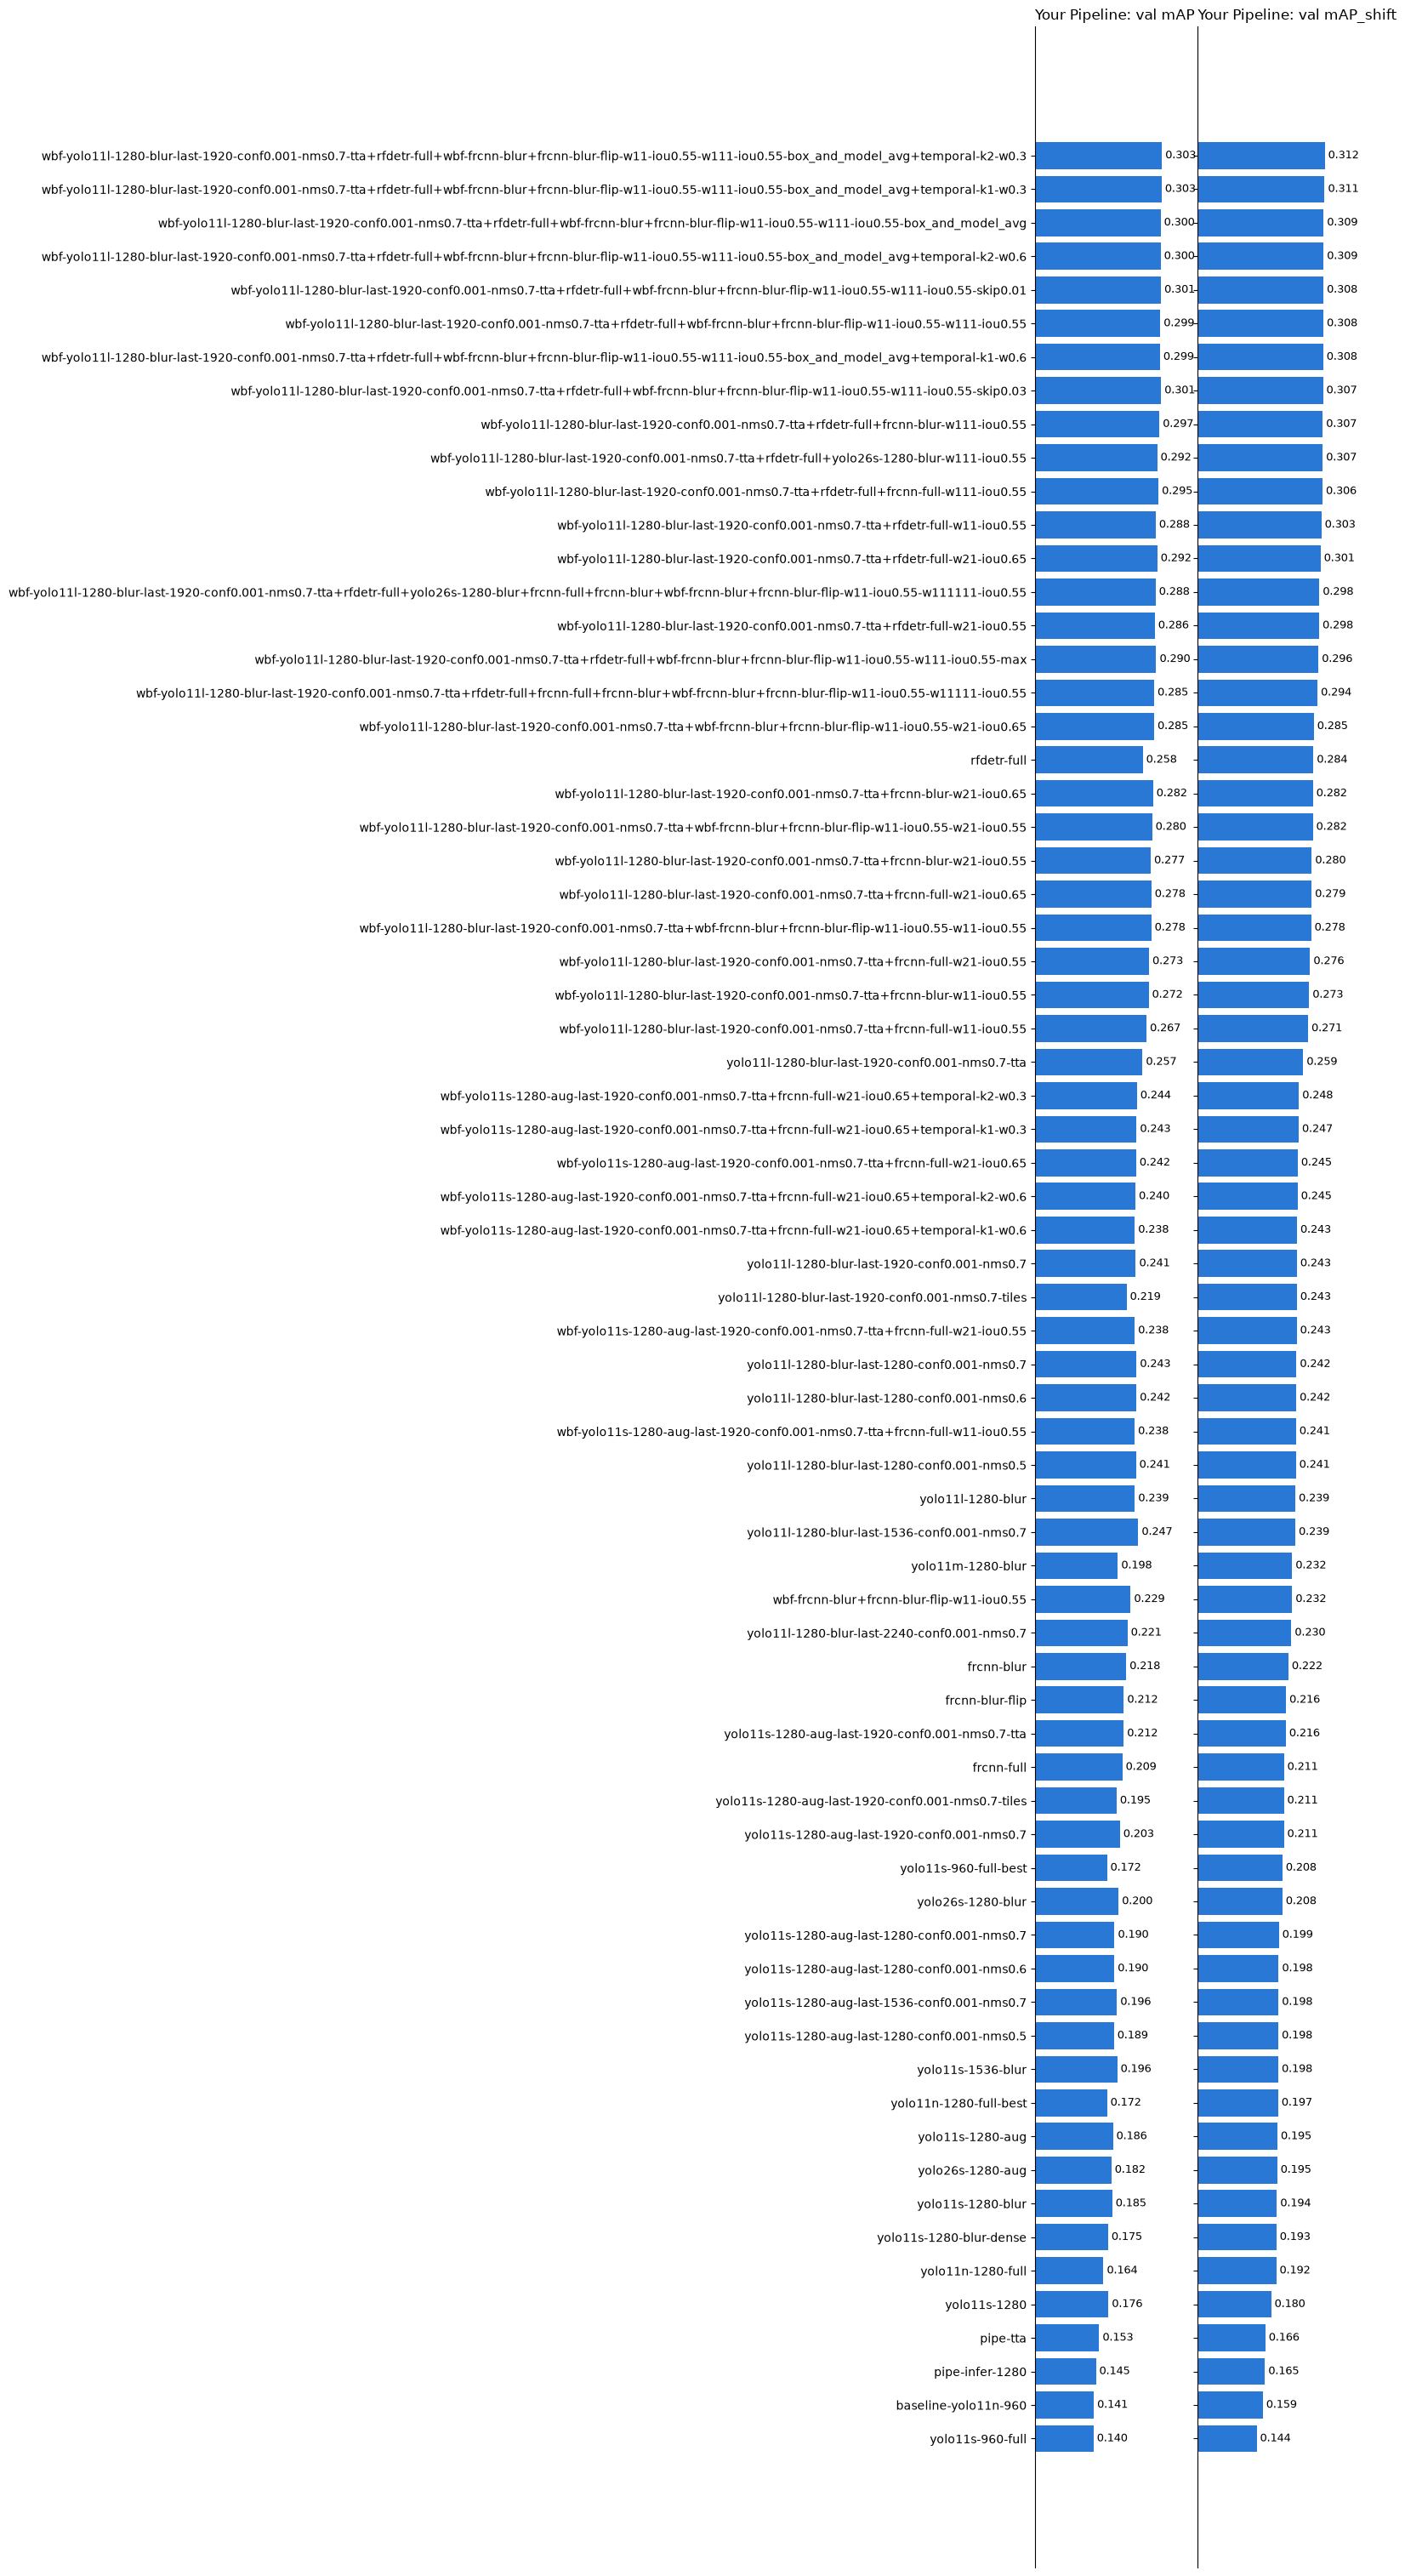

,mAP_shift,mean clip gain,clips better,clips
run,,,,
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k2-w0.3,0.312,0.145,7,7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k1-w0.3,0.311,0.144,7,7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg,0.309,0.143,7,7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k2-w0.6,0.309,0.140,7,7
wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-skip0.01,0.308,0.143,7,7
...,...,...,...,...
yolo11s-1280,0.180,0.036,7,7
pipe-tta,0.166,0.008,5,7
pipe-infer-1280,0.165,0.011,5,7


In [109]:
pipeline = load_log().query("section == 'pipeline'").sort_values(SELECT_METRIC)
display(pipeline[['run', 'settings', 'mAP', 'mAP_testlike', 'mAP_blur', SELECT_METRIC, 'AP50', 'AP_small', 'ms_per_frame']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 0.42 * len(pipeline) + 1.4), sharey=True)
for ax, col in zip(axes, ['mAP', SELECT_METRIC]):
    ax.barh(pipeline.run, pipeline[col], color='#2a78d6')
    for y, value in enumerate(pipeline[col]):
        ax.text(value, y, f' {value:.3f}', va='center', fontsize=9)
    ax.set_title(f'Your Pipeline: val {col}', loc='left')
    ax.set_xticks([])
    ax.margins(x=0.15)
    ax.spines[['top', 'right', 'bottom']].set_visible(False)
plt.tight_layout()
plt.show()

display(paired(pipeline.run[::-1], 'baseline-yolo11n-960'))

## Final model and submission
The best row of Your Pipeline by `SELECT_METRIC` decides the models and the inference settings. Its full description (`spec`) is stored in the log, so the test frames are predicted exactly as the val frames were.

In [110]:
add_blur_metric()
final = load_log().query("section == 'pipeline'").dropna(subset=[SELECT_METRIC]).nlargest(1, SELECT_METRIC).iloc[0]
FINAL_SPEC = spec_of(final.run)
print(f'Final: {final.run} ({final.settings})')
print(f'val mAP {final.mAP:.3f}, test-like {final.mAP_testlike:.3f}, blurred {final.mAP_blur:.3f}, '
      f'{SELECT_METRIC} {final[SELECT_METRIC]:.3f}')

Final: wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k2-w0.3 (temporal rescoring of wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg, k=2, w=0.3)
val mAP 0.303, test-like 0.320, blurred 0.303, mAP_shift 0.312


### Retraining on train + val
With `USE_TRAINVAL`, every YOLO in the final model is retrained with its recipe on train plus every 5th val frame. Val adds 7 clips to the 56 in train, including the only 4K footage. No held-out frames are left, so this model uses `last.pt` after the fixed number of epochs and is not scored on val. Both the original and the retrained version are submitted, so one of each can be chosen as a final Kaggle submission.

In [111]:
def model_specs(spec):
    if spec['kind'] in MODEL_KINDS:
        yield spec
    for child in spec.get('members', []) + ([spec['base']] if 'base' in spec else []):
        yield from model_specs(child)


def with_trainval(spec):
    original, spec = json.dumps(spec, sort_keys=True), dict(spec)
    if spec['kind'] == 'ultralytics' and spec['weights'] in TRAINVAL:
        spec.update(weights=TRAINVAL[spec['weights']], checkpoint='last')
    if 'members' in spec:
        spec['members'] = [with_trainval(member) for member in spec['members']]
    if 'base' in spec:
        spec['base'] = with_trainval(spec['base'])
    if json.dumps(spec, sort_keys=True) != original:
        spec['run'] += '-trainval'
    return spec


trainval_frames = PREPARED_FRAMES + sorted((PREP / 'val' / 'images').rglob('*.jpg'))[::TRAIN_STRIDE]
trainval_yaml = write_frame_list('train_trainval', trainval_frames)

TRAINVAL = {}
for member in model_specs(FINAL_SPEC) if USE_TRAINVAL else []:
    weights = member['weights']
    if member['kind'] != 'ultralytics' or weights not in RECIPES:
        continue
    run_ultralytics(f'{weights}-trainval', 'final', f'{weights} recipe on train + val', data=trainval_yaml,
                    evaluate=False, val=False, **RECIPES[weights])
    last = Path(RUNS) / f'{weights}-trainval' / 'weights' / 'last.pt'
    if last.exists() and not unfinished(last):
        TRAINVAL[weights] = f'{weights}-trainval'
print(f'{len(trainval_frames)} frames; retrained:', TRAINVAL or 'none')

5438 frames; retrained: none


### Submission file
One row per test image in `test_images.csv`. `PredictionString` is a list of `class score x y width height` groups, with (x, y) as the top-left corner in pixels of the original image. Images with no detections stay empty, and at most 500 detections per image are kept, highest score first.

Test predictions of every model are saved on Drive as `test_predictions.npy`, so an interrupted run continues where it stopped and the ensemble and temporal steps reuse them.

In [112]:
def to_submission(rows):
    sizes = test_images[['width', 'height']].to_numpy(float)
    strings = [''] * len(test_images)
    for image_id, part in by_image(rows).items():
        part = part[np.argsort(-part[:, 5], kind='stable')][:MAX_DET]
        width, height = sizes[image_id]
        x1, y1 = part[:, 1].clip(0, width), part[:, 2].clip(0, height)
        x2, y2 = (part[:, 1] + part[:, 3]).clip(0, width), (part[:, 2] + part[:, 4]).clip(0, height)
        groups = zip(part[:, 6].astype(int) - 1, part[:, 5], x1, y1, x2 - x1, y2 - y1)
        strings[image_id] = ' '.join(f'{c} {s:.5f} {x:.1f} {y:.1f} {w:.1f} {h:.1f}' for c, s, x, y, w, h in groups)
    return pd.DataFrame({'image_id': test_images.image_id, 'PredictionString': strings})


SUBMISSIONS = {FINAL_SPEC['run']: FINAL_SPEC}
if TRAINVAL:
    trainval_spec = with_trainval(FINAL_SPEC)
    SUBMISSIONS[trainval_spec['run']] = trainval_spec

pending = [s['run'] for spec in SUBMISSIONS.values() for s in model_specs(spec)
           if not (Path(RUNS) / s['run'] / 'test_predictions.npy').exists()]
assert not pending or torch.cuda.is_available(), f'{pending} still need a GPU runtime'

files = {name: to_submission(cached_rows(spec, 'test')) for name, spec in SUBMISSIONS.items()}
MAIN = FINAL_SPEC['run']  # the train-only model; the train + val version scored lower on Kaggle
submission = files[MAIN]
print('Main submission:', MAIN)
submission.head()

  0%|          | 0/953 [00:00<?, ?it/s]            [2026-11-14 09:15:19] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


Main submission: wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k2-w0.3


,image_id,PredictionString
0,clip_001_0000001,0 0.79348 1712.4 788.6 56.6 145.1 0 0.61552 97...
1,clip_001_0000002,0 0.84555 1662.2 793.5 60.4 151.4 0 0.70059 73...
2,clip_001_0000003,0 0.78716 1667.4 797.3 62.4 154.7 0 0.71396 17...
3,clip_001_0000004,0 0.80955 1667.5 800.8 61.8 156.0 0 0.63557 17...
4,clip_001_0000005,0 0.65963 937.1 732.2 39.0 101.5 0 0.58760 166...


Check the file before using a submission: every test image appears once, each detection has 6 values, classes are 0-7, and boxes stay inside their frame.

In [113]:
def check_submission(submission):
    values = submission.PredictionString.fillna('').str.split()
    counts = values.str.len() // 6
    assert len(submission) == len(test_images) and submission.image_id.is_unique
    assert (values.str.len() % 6 == 0).all() and counts.max() <= MAX_DET

    detections = pd.DataFrame(
        [[i, *group] for i, row in zip(submission.image_id, values)
         for group in np.array(row, dtype=float).reshape(-1, 6)],
        columns=['image_id', 'cls', 'score', 'x', 'y', 'w', 'h']).merge(test_images, on='image_id')

    assert detections.cls.between(0, len(CLASSES) - 1).all() and detections.score.between(0, 1).all()
    assert (detections.w >= 0).all() and (detections.h >= 0).all()
    assert (detections.x >= -1).all() and (detections.y >= -1).all()
    assert (detections.x + detections.w <= detections.width + 1).all()
    assert (detections.y + detections.h <= detections.height + 1).all()
    return detections, counts


checked = {name: check_submission(file) for name, file in files.items()}
for name, (found, counts) in checked.items():
    print(f'{name}: {len(found)} detections, {(counts == 0).sum()} empty images')
detections = checked[MAIN][0]
print(detections.cls.astype(int).map(lambda i: CLASSES[i]).value_counts())

wbf-yolo11l-1280-blur-last-1920-conf0.001-nms0.7-tta+rfdetr-full+wbf-frcnn-blur+frcnn-blur-flip-w11-iou0.55-w111-iou0.55-box_and_model_avg+temporal-k2-w0.3: 1750661 detections, 0 empty images
cls
person      850127
car         353388
motor       221110
bicycle      88327
tricycle     84693
van          67283
truck        65654
bus          20079
Name: count, dtype: int64


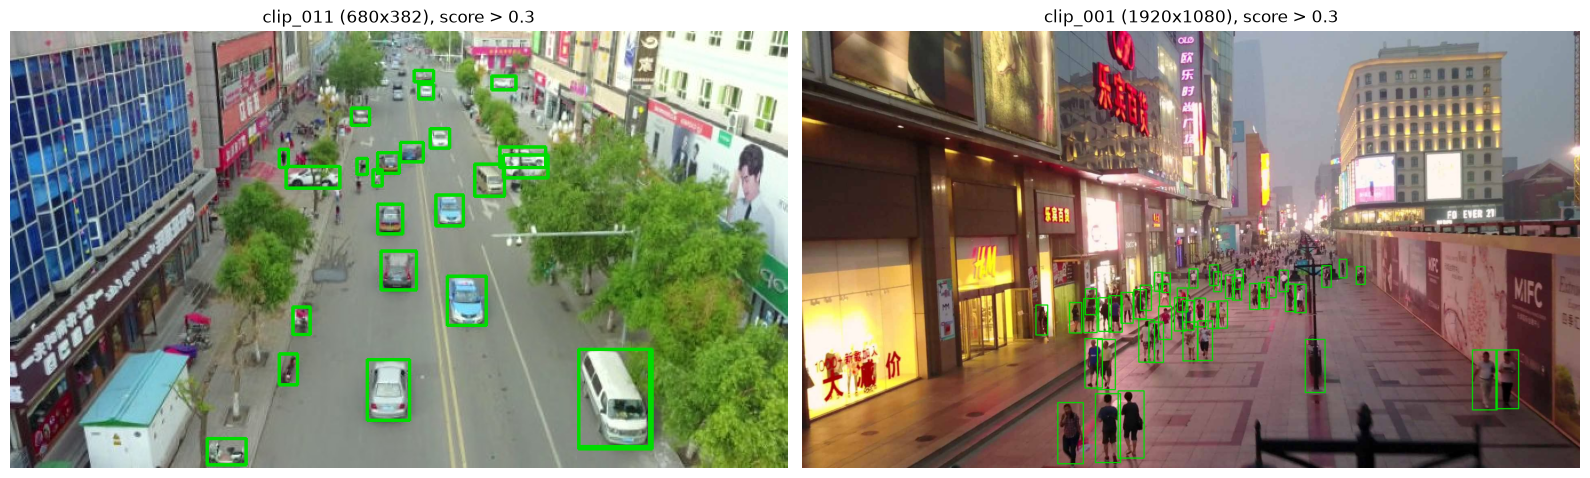

In [114]:
samples = test_images.drop_duplicates(['width', 'height']).sort_values('width').iloc[[0, -1]]
sure = detections[detections.score > 0.3]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, frame in zip(axes, samples.itertuples()):
    image = cv2.cvtColor(cv2.imread(str(DATA / frame.file_name)), cv2.COLOR_BGR2RGB)
    draw_boxes(image, sure[sure.image_id == frame.image_id], (0, 220, 0))
    ax.imshow(image)
    ax.set_title(f'{frame.clip} ({frame.width}x{frame.height}), score > 0.3')
    ax.axis('off')
plt.tight_layout()
plt.show()

The boxes above should sit on objects in both the smallest and the largest frame size. If they are shifted or scaled, the coordinates are wrong, so do not submit.

In [115]:
for name, file in files.items():
    file.to_csv(Path(RUNS) / f'submission-{name}.csv', index=False)
submission.to_csv('submission.csv', index=False)
print(Path('submission.csv').stat().st_size / 1e6, 'MB')

56.165175 MB


In [116]:
if SUBMIT and not SMOKE_TEST:
    submitted = '\n'.join(get_ipython().getoutput(f'kaggle competitions submissions -c {COMPETITION} -v'))
    for name in files:
        if f',{name},' in submitted or f'"{name}"' in submitted:
            print('Already on Kaggle:', name)
            continue
        file = Path(RUNS) / f'submission-{name}.csv'
        !kaggle competitions submit -c {COMPETITION} -f "{file}" -m "{name}"
    !kaggle competitions submissions -c {COMPETITION}

100%|█████████████████████████████████████| 53.6M/53.6M [00:02<00:00, 19.4MB/s]
Submission ref: 58335759
9 submissions remaining today.
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026     ref  fileName                                                                                                                                                                date                        description                                                                                                                                                  status                     publicScore   privateScore  
--------  ----------------------------------------------------------------------------------------------------------------------------------------------------------------------  --------------------------  -----------------------------------------------------------------------------------------------------------------------------------------------------------  -----

In [117]:
stop_runtime()